TODO:
- Calculate uncertainty

# Cable timing calibration

Experimental setup:

[ signal generator ] --> [ reference cable ] --> [ cable # ] --> [ picoscope channel 2 ]

The Ch. 1 data will act as reference. The timing delay for a given cable will be the difference between the Ch. 2 and 1 rise times, accounting also for the time delay from the reference cable.

Each time the resolution on the scope was changed, the Ch. 1 waveform was recorded; the files have been named according to the trials with which they are associated. Three trials were performed for the Ch. 2 measurements.

In [253]:
### Import libraries
import numpy as np
from matplotlib import pyplot as plt
import os
from scipy.optimize import curve_fit
import pandas as pd

### Set plotting style
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"] # path to LaTeX installation
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "text.latex.preamble": r"\usepackage{amsmath}",
    "font.size": 14
})
plt.style.use('dark_background')
plt.rcParams['figure.dpi'] = 300

### Directory in which data files are located
dir = 'timing-calibration-data/'

In [3]:
### Define function to get x coordinates from x start point and x-units/div
def getTimeVals(start,step,num=50):
    return np.arange(start,start+step*num,step)

In [125]:
### Define fitting function (s curve)
def sigmoid(x, a, b, c, d):
    return a/(1+np.exp(-b*(x+c)))+d

### Define function to get x value of fitted function given a y value
def getFitX(y, a, b, c, d):
    return -1/b*np.log(a/y-(1+d))-c

### Define function to perform fit
def performFit(xvals, yvals, a0, b0, c0, d0):
    p0 = [a0, b0, c0, d0]
    fitvals, _ = curve_fit(sigmoid, xvals, yvals, p0=p0)
    return sigmoid(xvals, *fitvals), fitvals

In [194]:
### Define function to analyze and plot data
def analyze(file_CH1, file_CH2, xstep, xstart_CH1, xstart_CH2, title, num=50,
                  a0=0.35, b0=1, c0=1, d0=0):
    
    ### Read in data
    data_CH1 = np.loadtxt(dir+file_CH1)
    data_CH2 = np.loadtxt(dir+file_CH2)

    ### Generate x coordinates (ns)
    tvals_CH1 = getTimeVals(xstart_CH1,xstep,num)
    tvals_CH2 = getTimeVals(xstart_CH2,xstep,num)

    ### Fit to sigmoid function
    fitVvals_CH1, fitparams_CH1 = performFit(tvals_CH1, data_CH1, a0, b0, c0, d0)
    fitVvals_CH2, fitparams_CH2 = performFit(tvals_CH2, data_CH2, a0, b0, c0, d0)

    ### Plot waveforms
    plt.scatter(tvals_CH1,data_CH1,s=5,label='Ch.1 data')
    plt.scatter(tvals_CH2,data_CH2,s=5,label='Ch.2 data')
    plt.ylabel('Voltage [V]')
    plt.xlabel('Time [ns]')
    plt.title(title)

    ### Plot fit
    plt.plot(tvals_CH1, fitVvals_CH1, label='Ch.1 fit')
    plt.plot(tvals_CH2, fitVvals_CH2, label='Ch.2 fit')

    ### Find and print timing difference
    midpointV_CH1 = (np.max(fitVvals_CH1)-np.min(fitVvals_CH1))/2 + np.min(fitVvals_CH1)
    midpointV_CH2 = (np.max(fitVvals_CH2)-np.min(fitVvals_CH2))/2 + np.min(fitVvals_CH2)
    midpointt_CH1 = getFitX(midpointV_CH1, fitparams_CH1[0], fitparams_CH1[1], fitparams_CH1[2], fitparams_CH1[3])
    midpointt_CH2 = getFitX(midpointV_CH2, fitparams_CH2[0], fitparams_CH2[1], fitparams_CH2[2], fitparams_CH2[3])
    deltat = midpointt_CH2 - midpointt_CH1
    print('Time delay = '+ str(deltat) + ' ns')

    ### Add midpoints to plot
    plt.scatter(midpointt_CH1, midpointV_CH1, s=10, zorder=10, label='Ch.1 midpoint')
    plt.scatter(midpointt_CH2, midpointV_CH2, s=10, zorder=10, label='Ch.2 midpoint')
    plt.legend(loc='lower right',fontsize=8)

    return deltat

In [56]:
### Define function to calculate uncertainty
# def getUncertainty():


## Reference Cable

In [5]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.95519006293882E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = -0.0844878500229482 ns


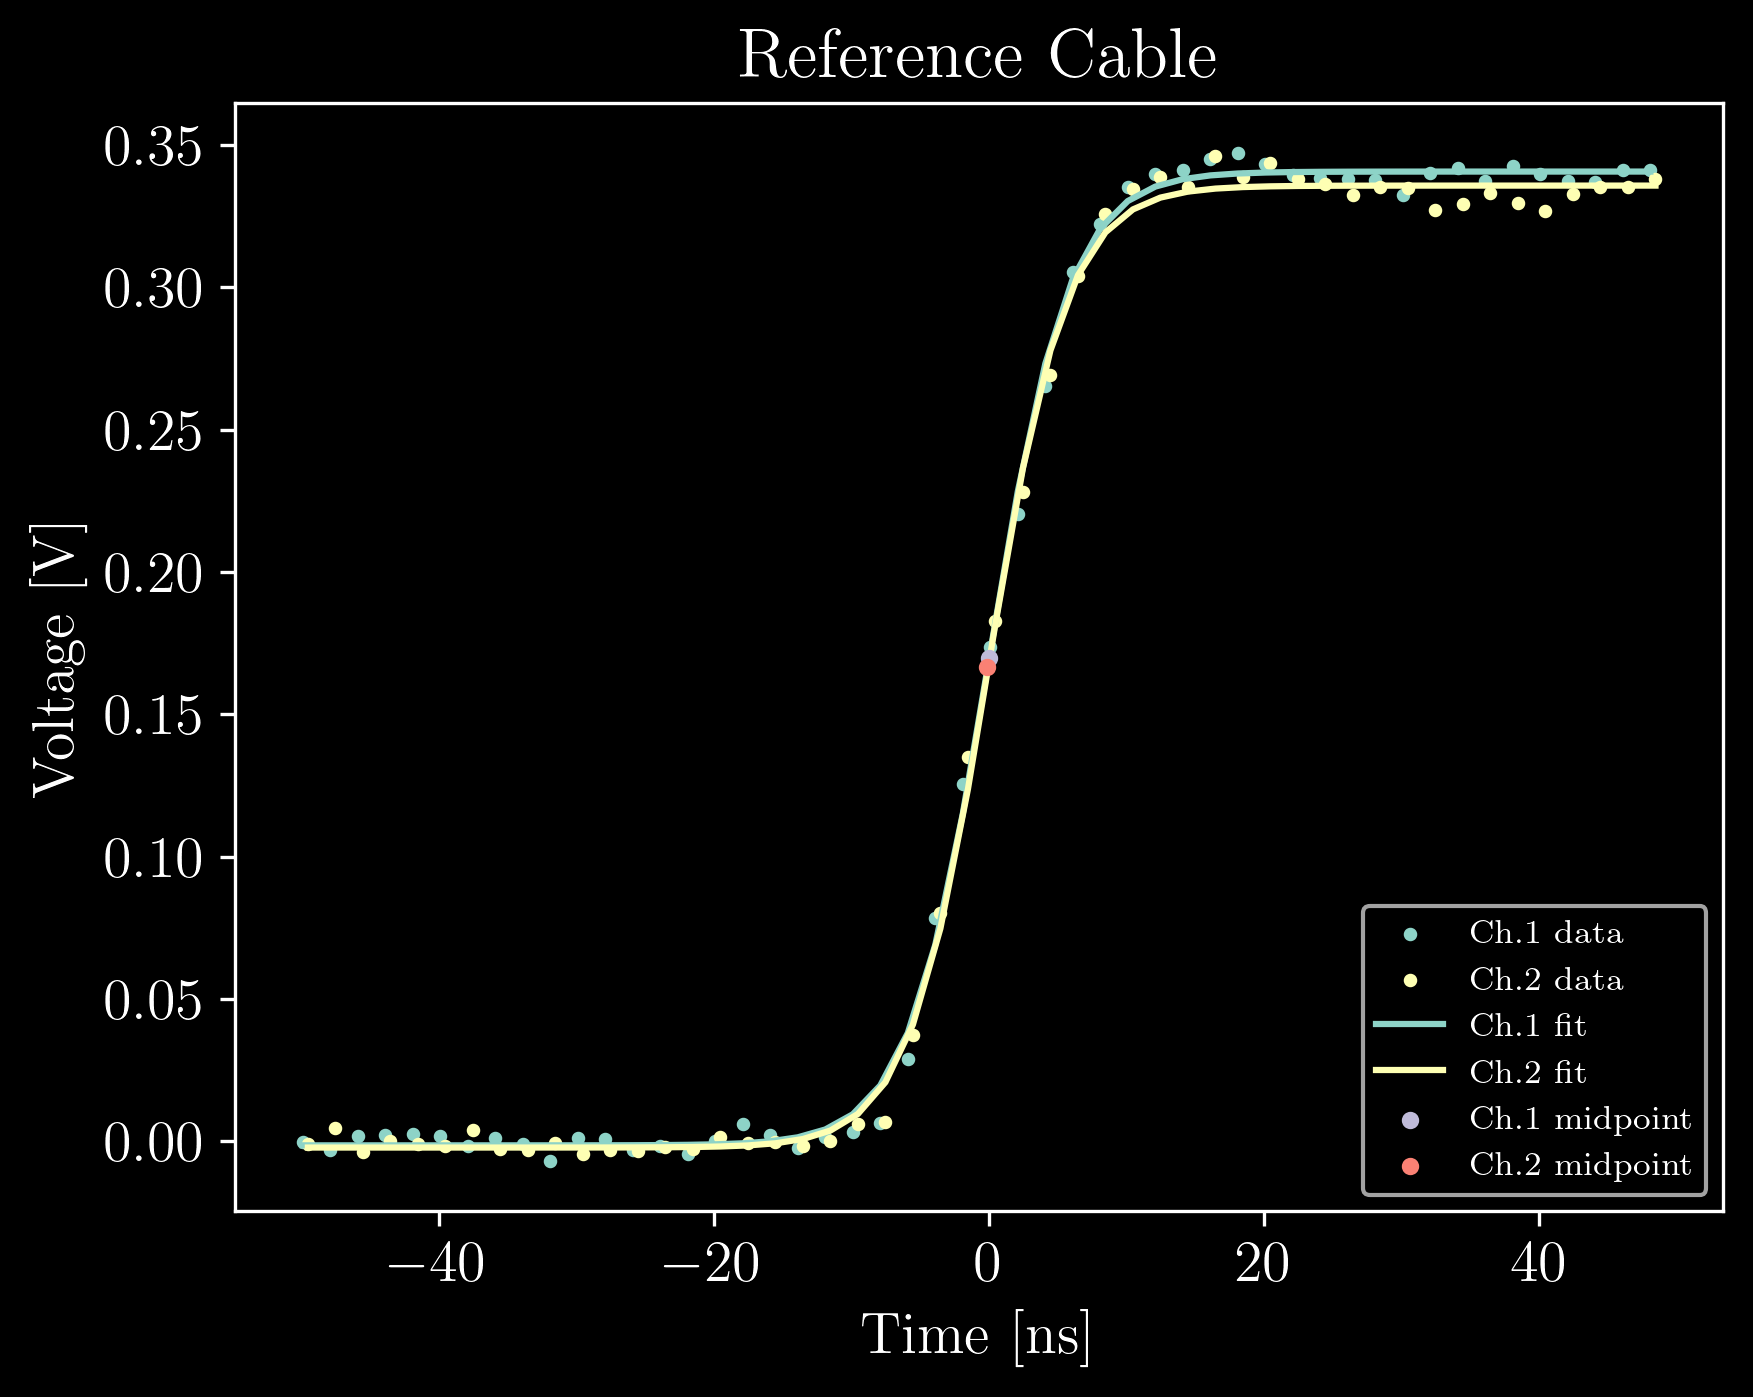

In [195]:
tdelay_ReferenceCable = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Reference copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.95519006293882*10, 
               title='Reference Cable')

## Cable 1

Cable type: pink, medium length, thin (expect to see dispersion)

#### Trial 1

In [14]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.93816088298150E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 15.151951353225256 ns


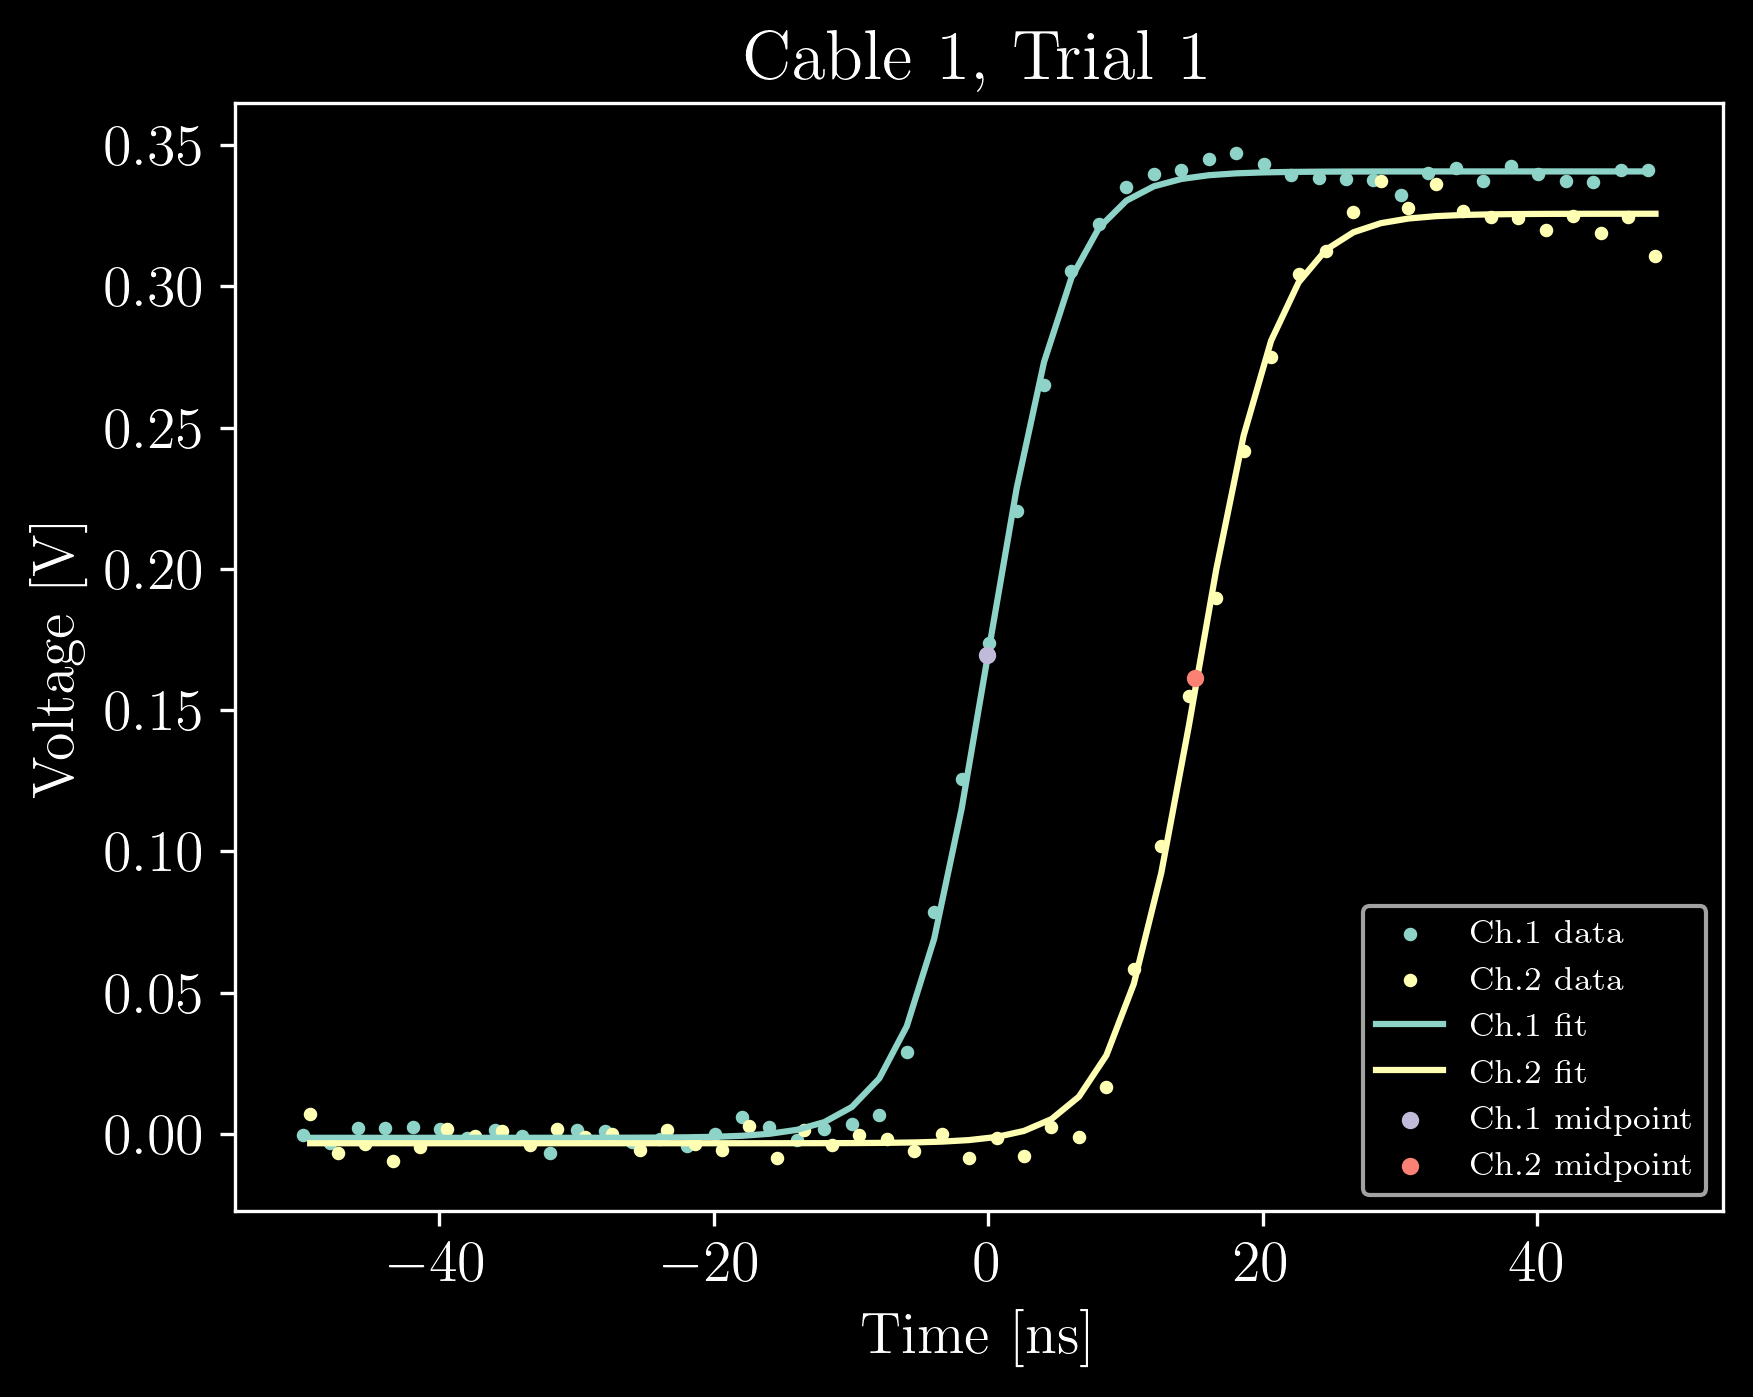

In [196]:
tdelay_Cable1_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable1_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.93816088298150*10, 
               title='Cable 1, Trial 1')

### Trial 2

In [ ]:
### CH. 1 ###
# -3.34630514671056E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -3.50000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -3.42132511639079E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -3.50000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 15.027147898637232 ns


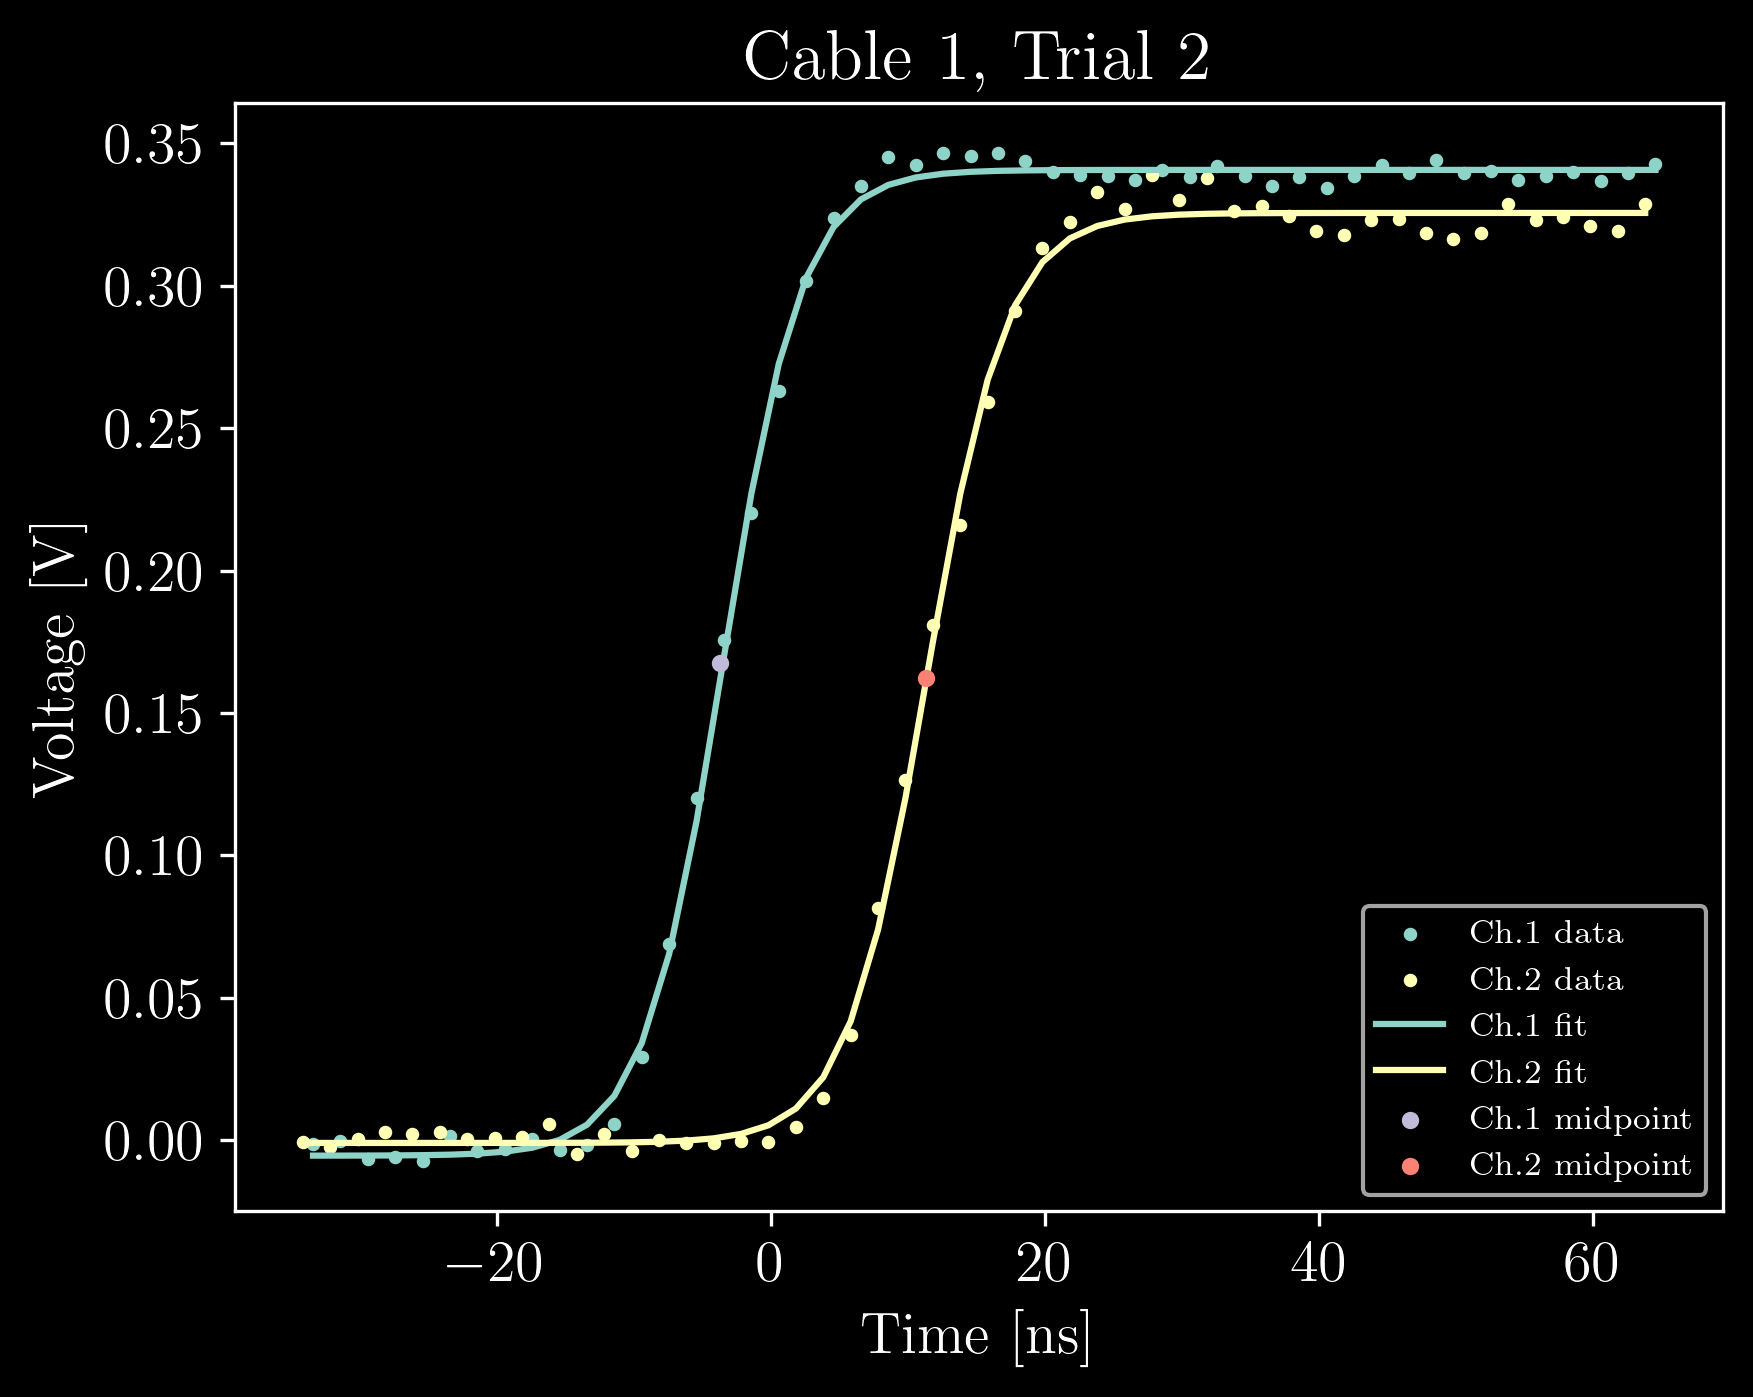

In [197]:
tdelay_Cable1_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables1and2_2-3 copy.txt',
               file_CH2='20261111_Ch2_Cable1_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-3.34630514671056*10, xstart_CH2=-3.42132511639079*10, 
               title='Cable 1, Trial 2')

### Trial 3

In [26]:
### CH. 1 ###
# -3.34630514671056E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -3.50000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -3.40723868314783E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -3.50000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.978259027861052 ns


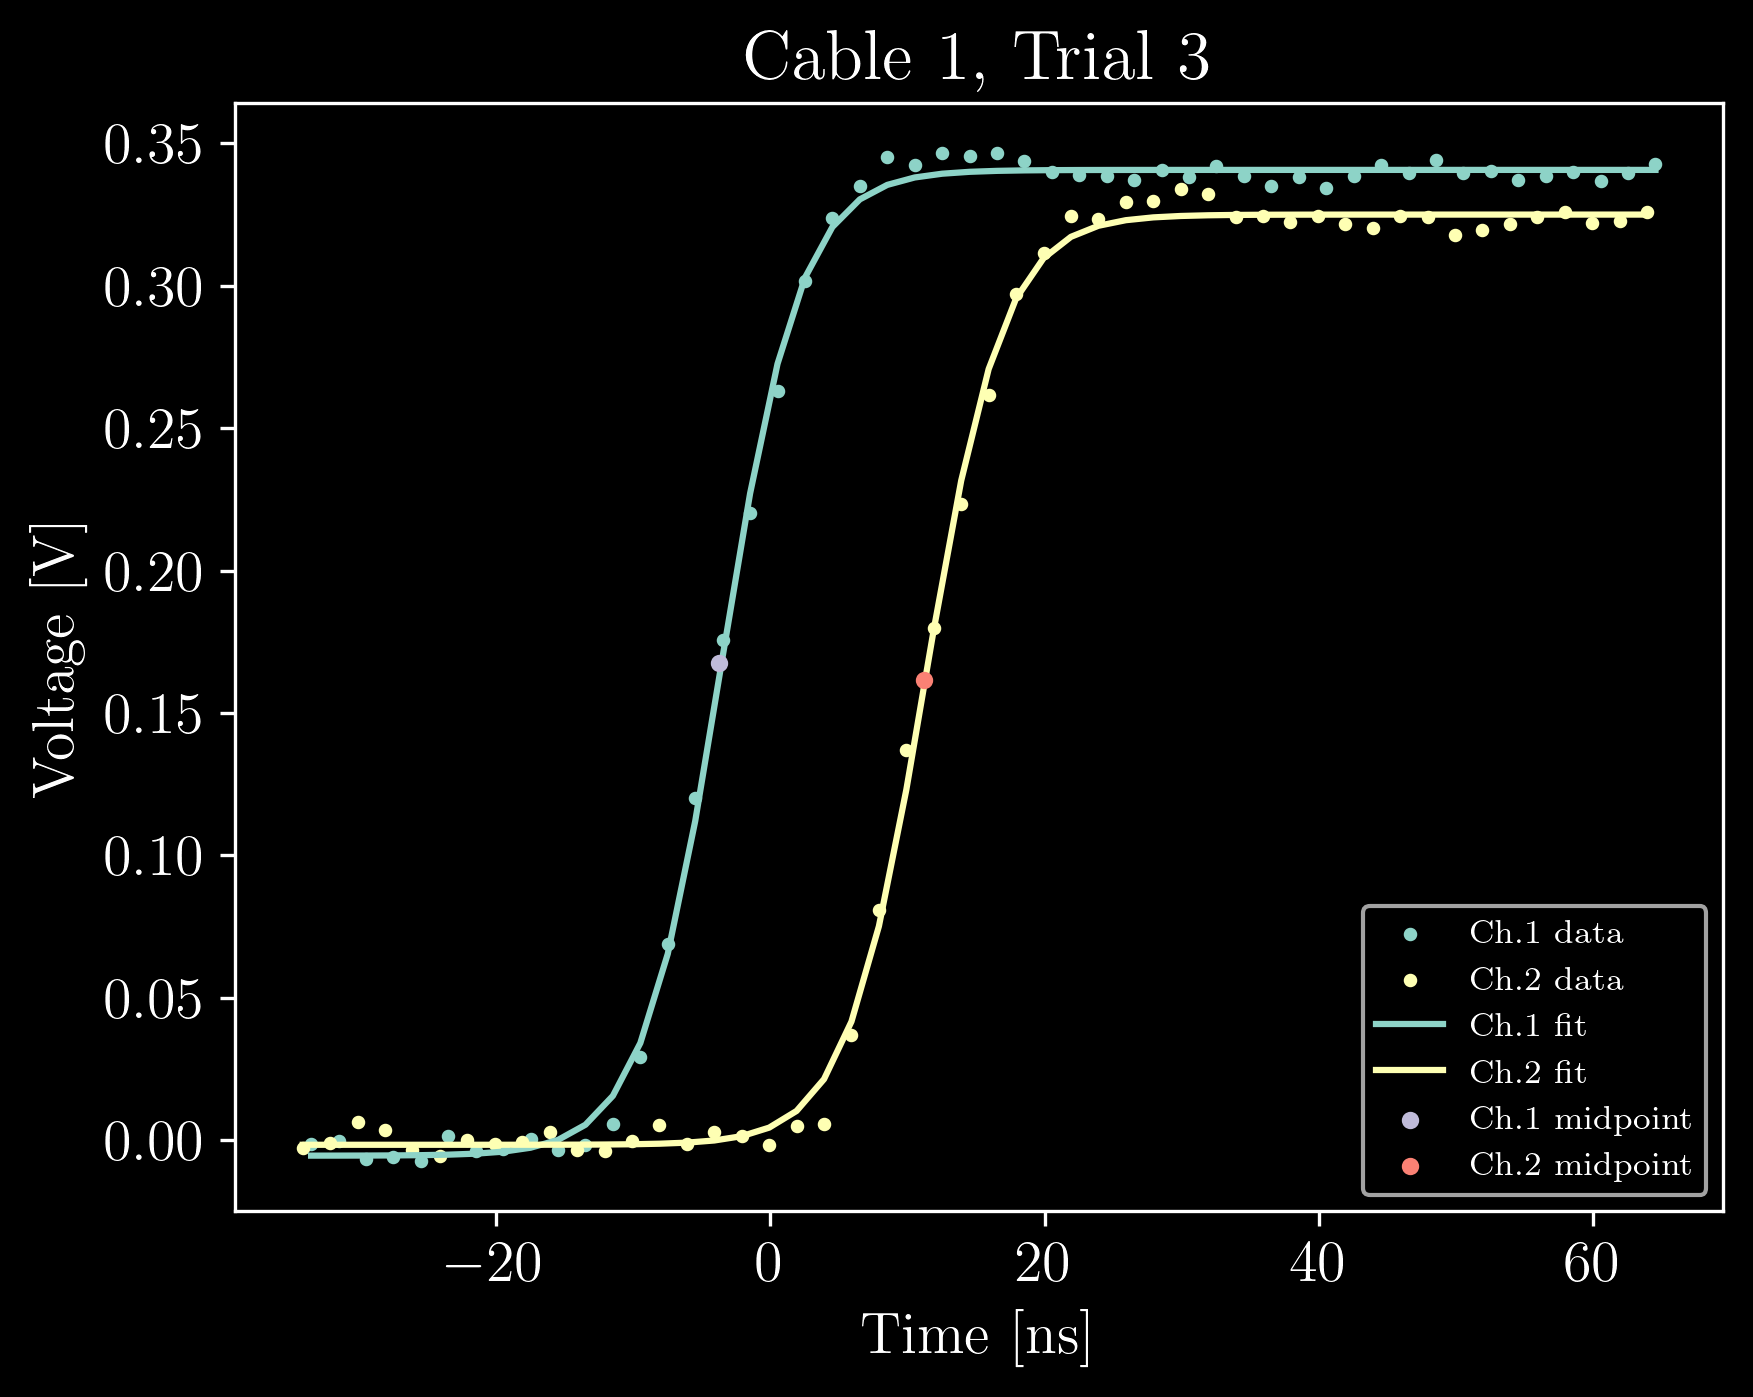

In [198]:
tdelay_Cable1_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables1and2_2-3 copy.txt',
               file_CH2='20261111_Ch2_Cable1_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-3.34630514671056*10, xstart_CH2=-3.40723868314783*10, 
               title='Cable 1, Trial 3')

### Average

In [171]:
tdelay_Cable1_avg = (tdelay_Cable1_1+tdelay_Cable1_2+tdelay_Cable1_3)/3
print('Average time delay = ' + str(tdelay_Cable1_avg) + ' ns')

Average time delay = 15.052452759907846 ns


# Cable 2

Cable type: pink, medium length, thin (expect to see dispersion)

#### Trial 1

In [39]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.96685781860017E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.782472500101651 ns


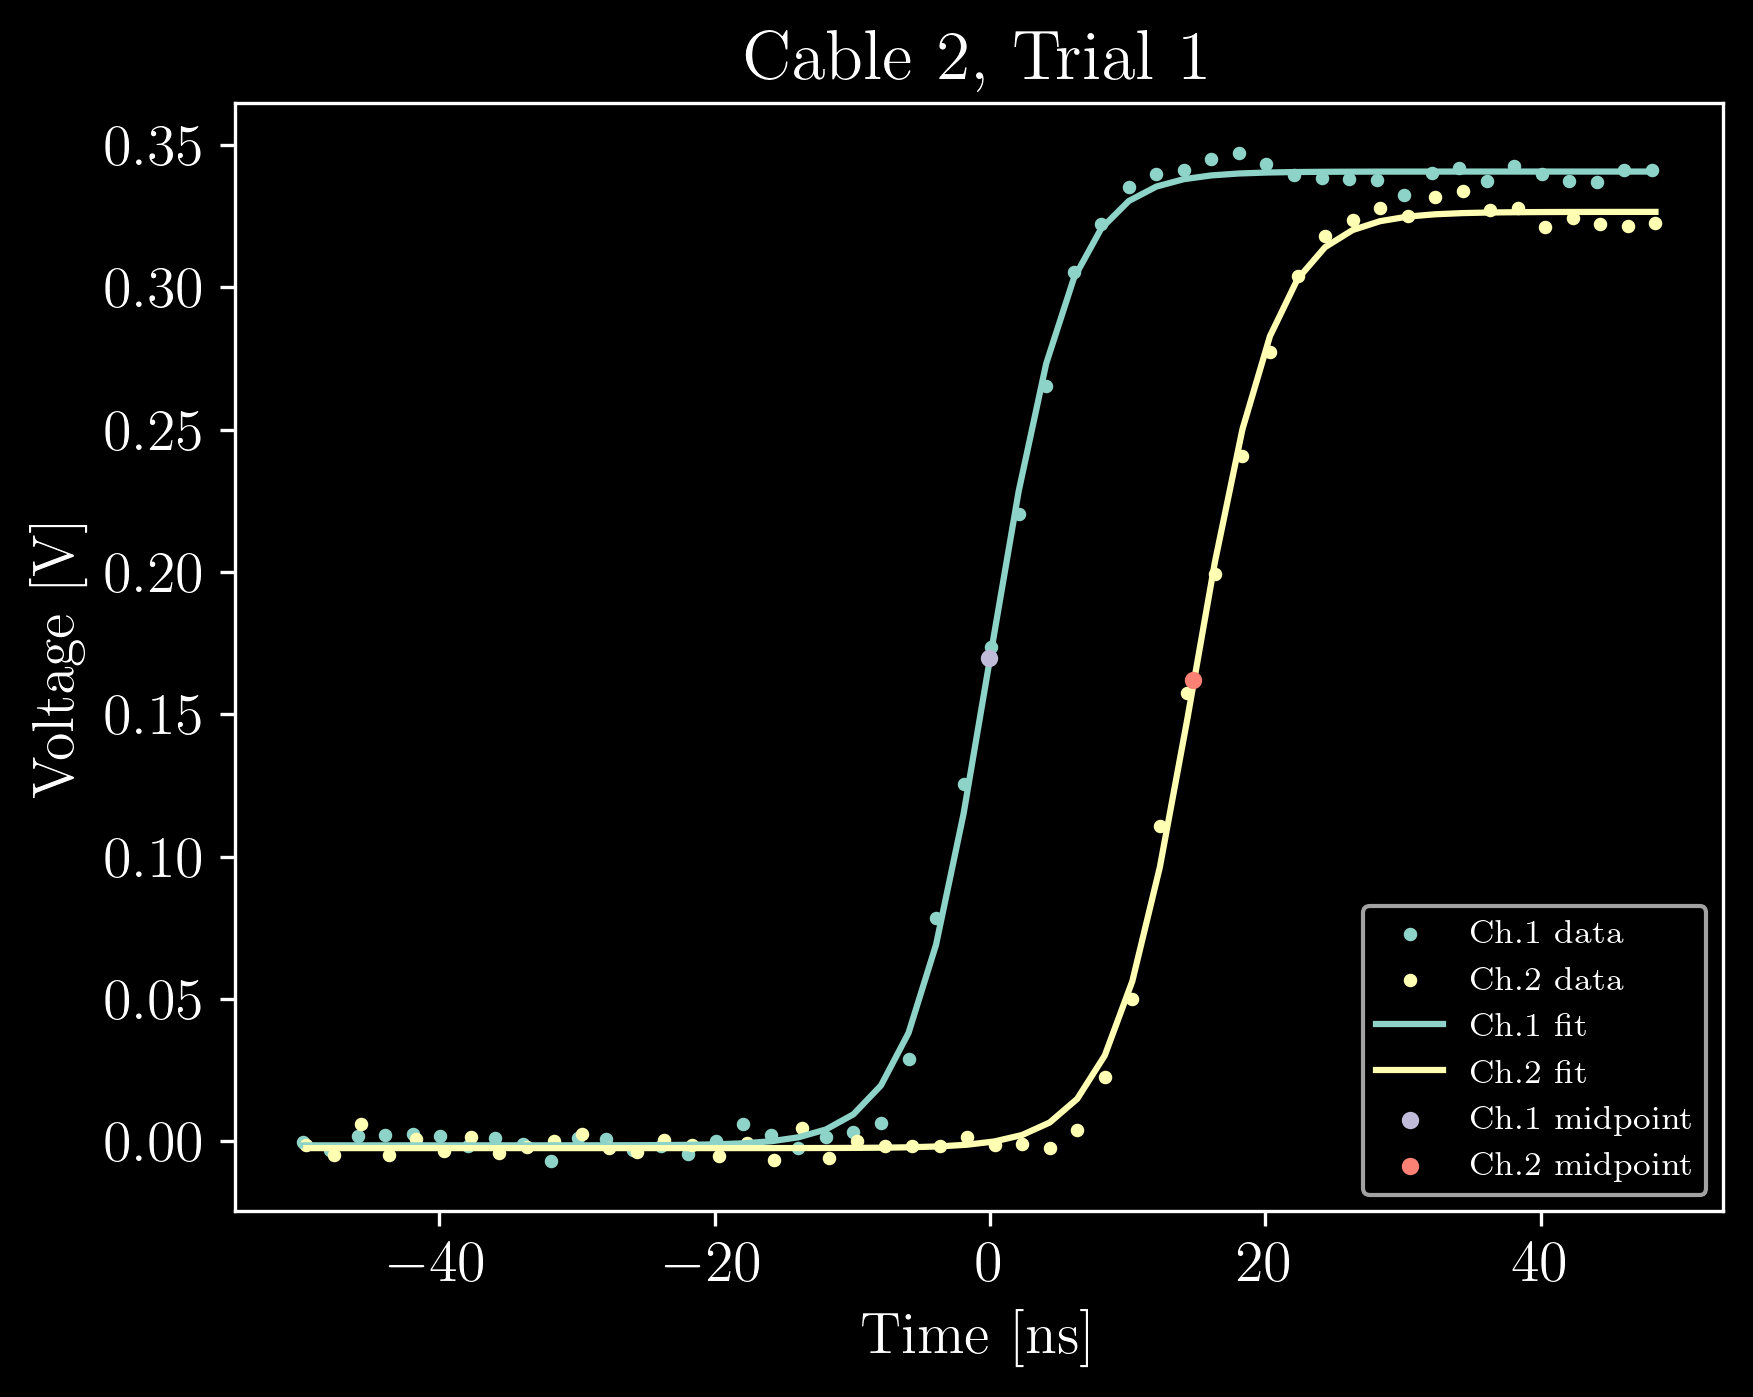

In [199]:
tdelay_Cable2_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable2_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.96685781860017*10, 
               title='Cable 2, Trial 1')

#### Trial 2

In [ ]:
### CH. 1 ###
# -3.34630514671056E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -3.50000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -3.37636053201085E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -3.50000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.968546563576878 ns


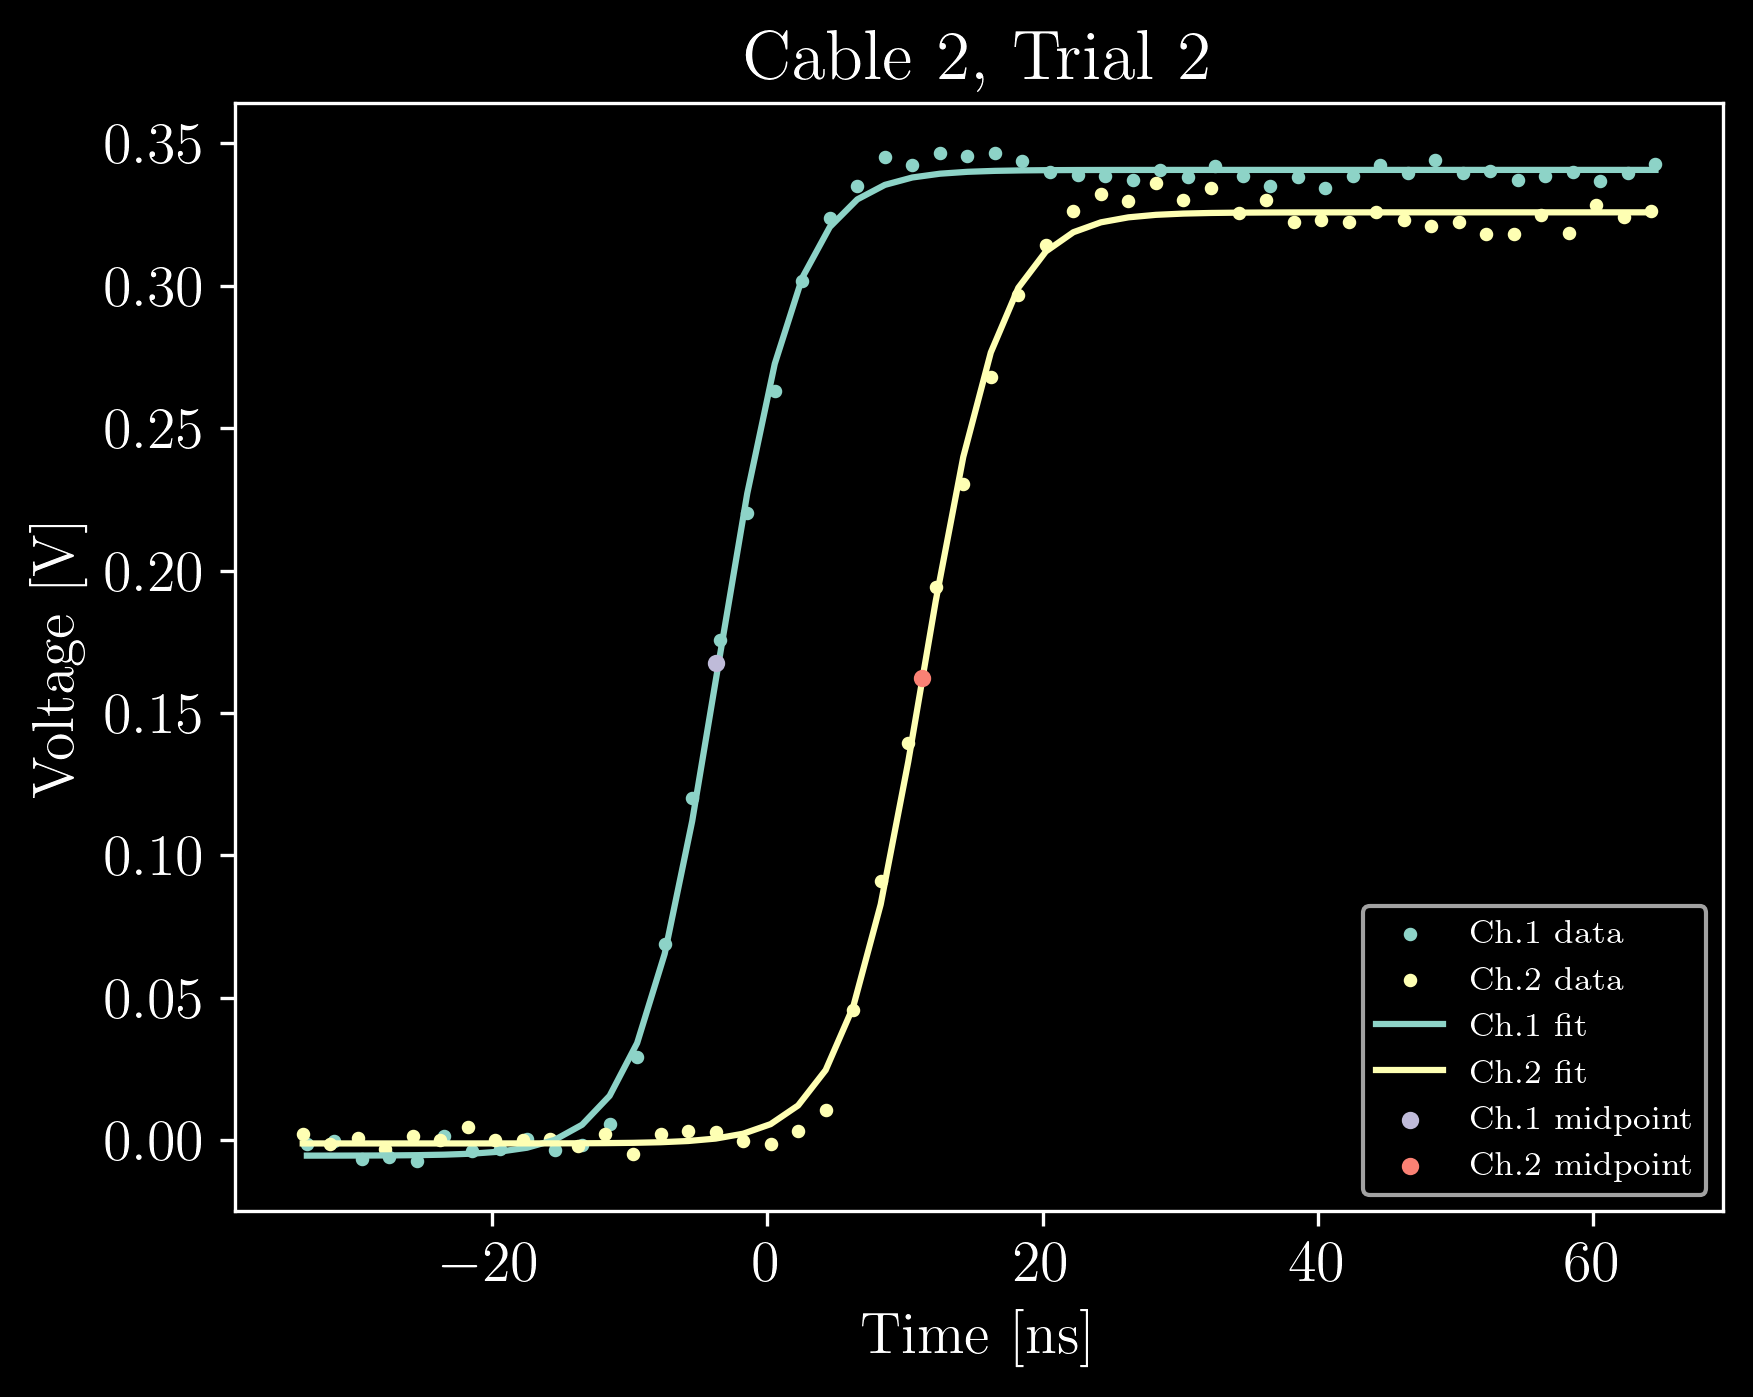

In [200]:
tdelay_Cable2_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables1and2_2-3 copy.txt',
               file_CH2='20261111_Ch2_Cable2_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-3.34630514671056*10, xstart_CH2=-3.37636053201085*10, 
               title='Cable 2, Trial 2')

#### Trial 3

In [ ]:
### CH. 1 ###
# -3.34630514671056E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -3.50000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -3.38709449091771E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -3.50000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.877141265701141 ns


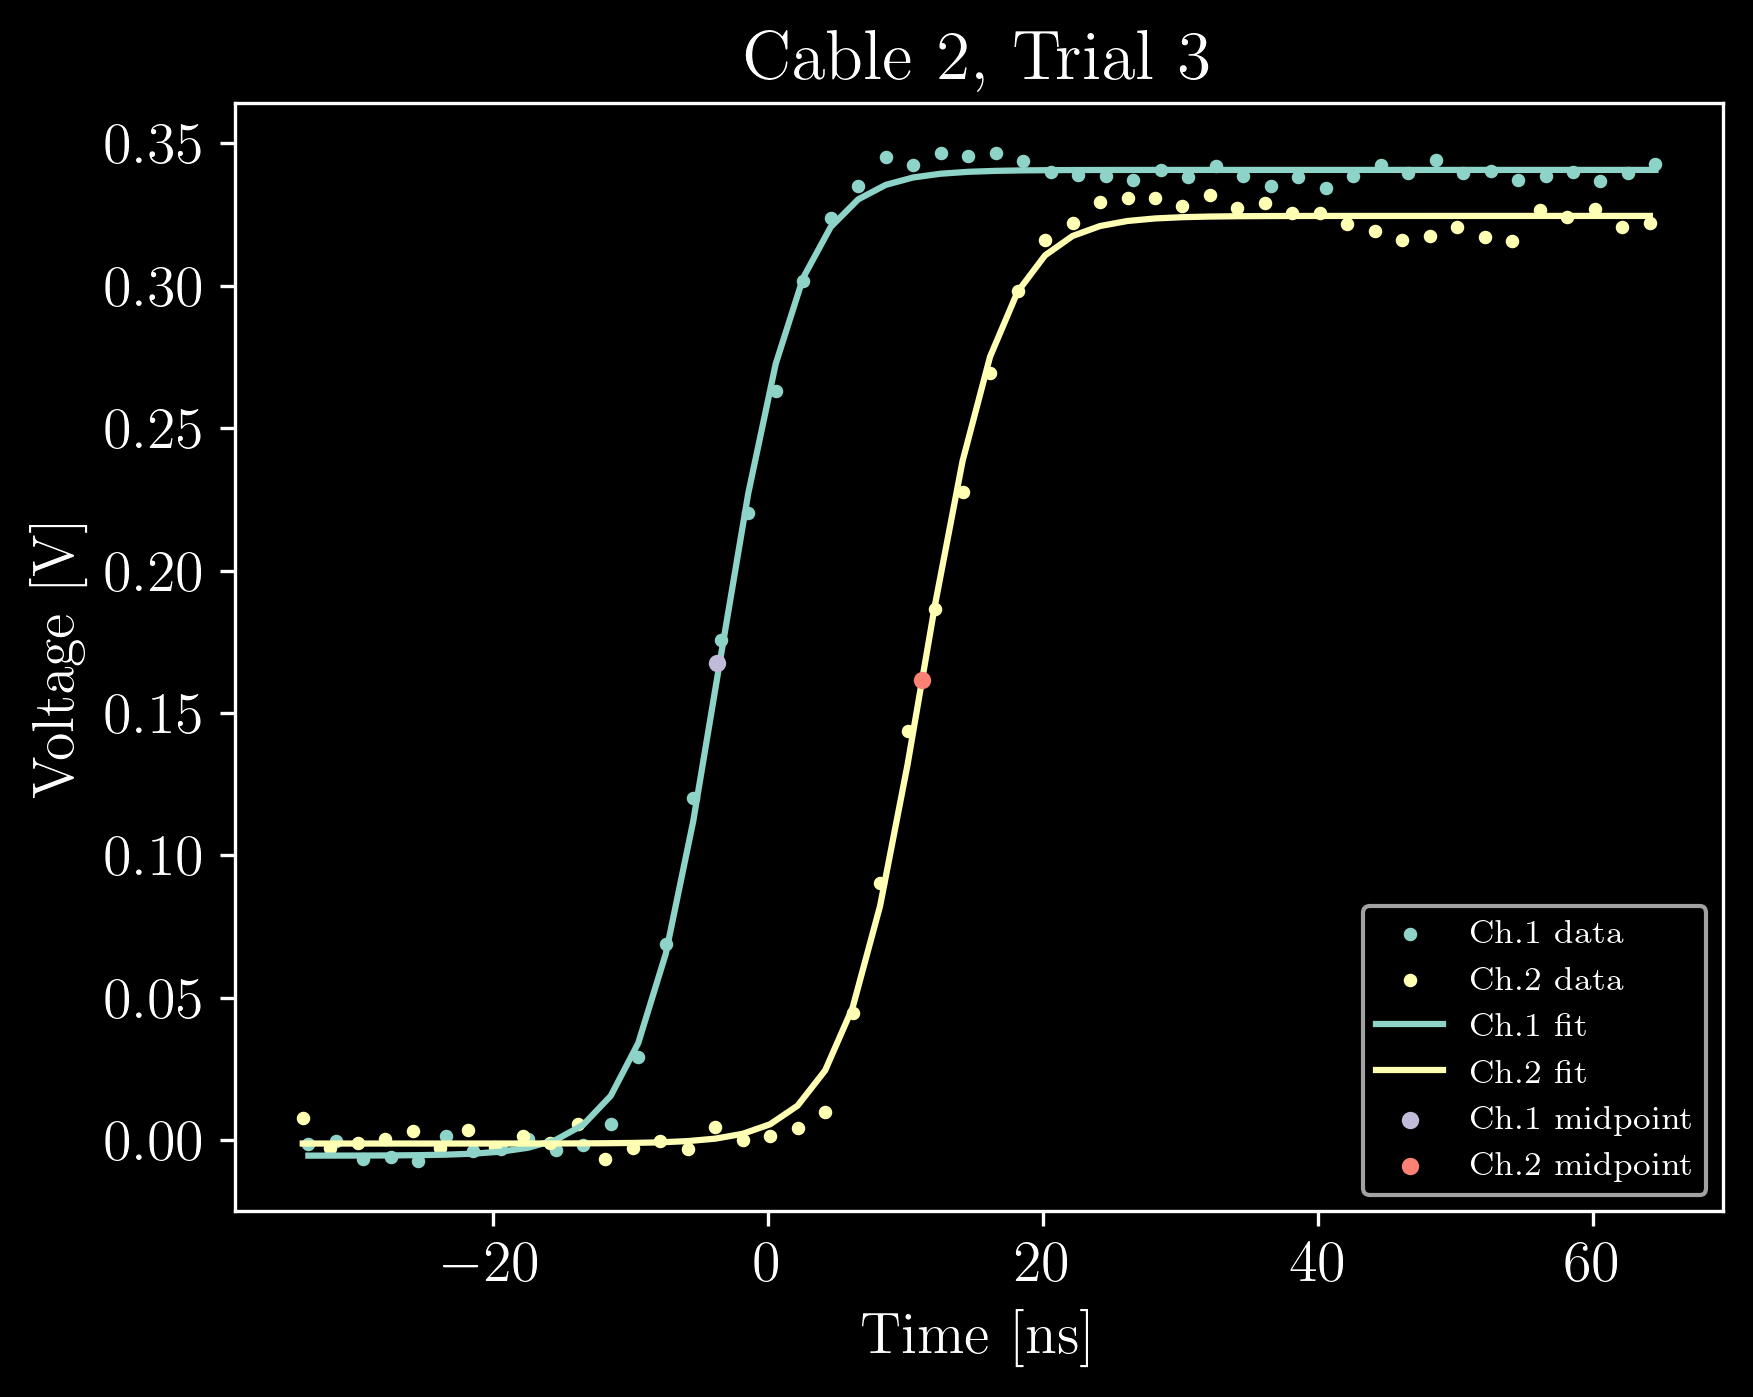

In [201]:
tdelay_Cable2_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables1and2_2-3 copy.txt',
               file_CH2='20261111_Ch2_Cable2_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-3.34630514671056*10, xstart_CH2=-3.38709449091771*10, 
               title='Cable 2, Trial 3')

#### Average

In [175]:
tdelay_Cable2_avg = (tdelay_Cable2_1+tdelay_Cable2_2+tdelay_Cable2_3)/3
print('Average time delay = ' + str(tdelay_Cable2_avg) + ' ns')

Average time delay = 14.876053443126557 ns


# Cable 3

Cable type: pink, medium length, thin (expect to see dispersion)

#### Trial 1

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.98092238553369E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.91142293857168 ns


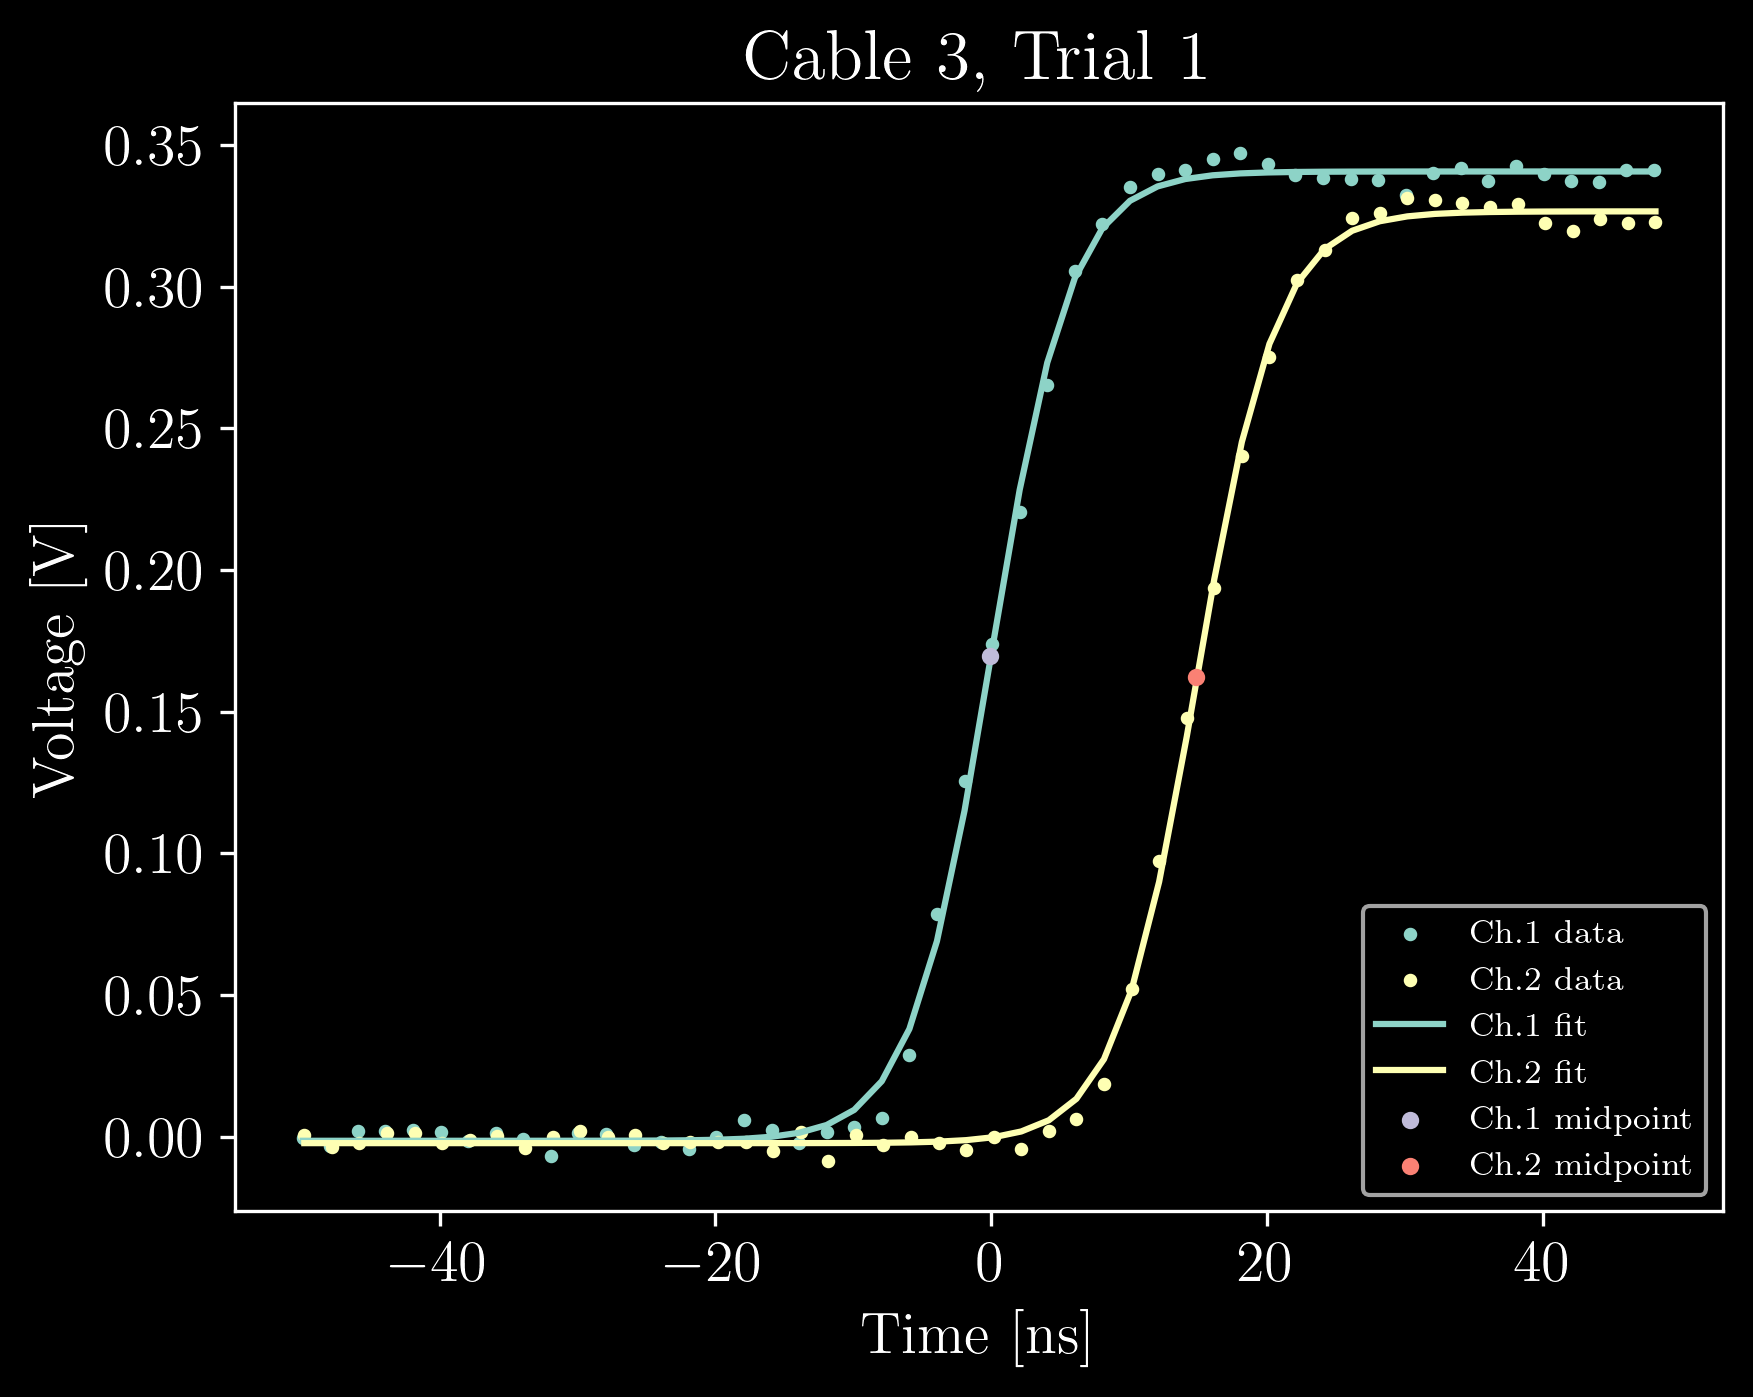

In [ ]:
tdelay_Cable3_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable3_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.98092238553369*10, 
               title='Cable 3, Trial 1')

#### Trial 2

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.88150117985300E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.895022129548625 ns


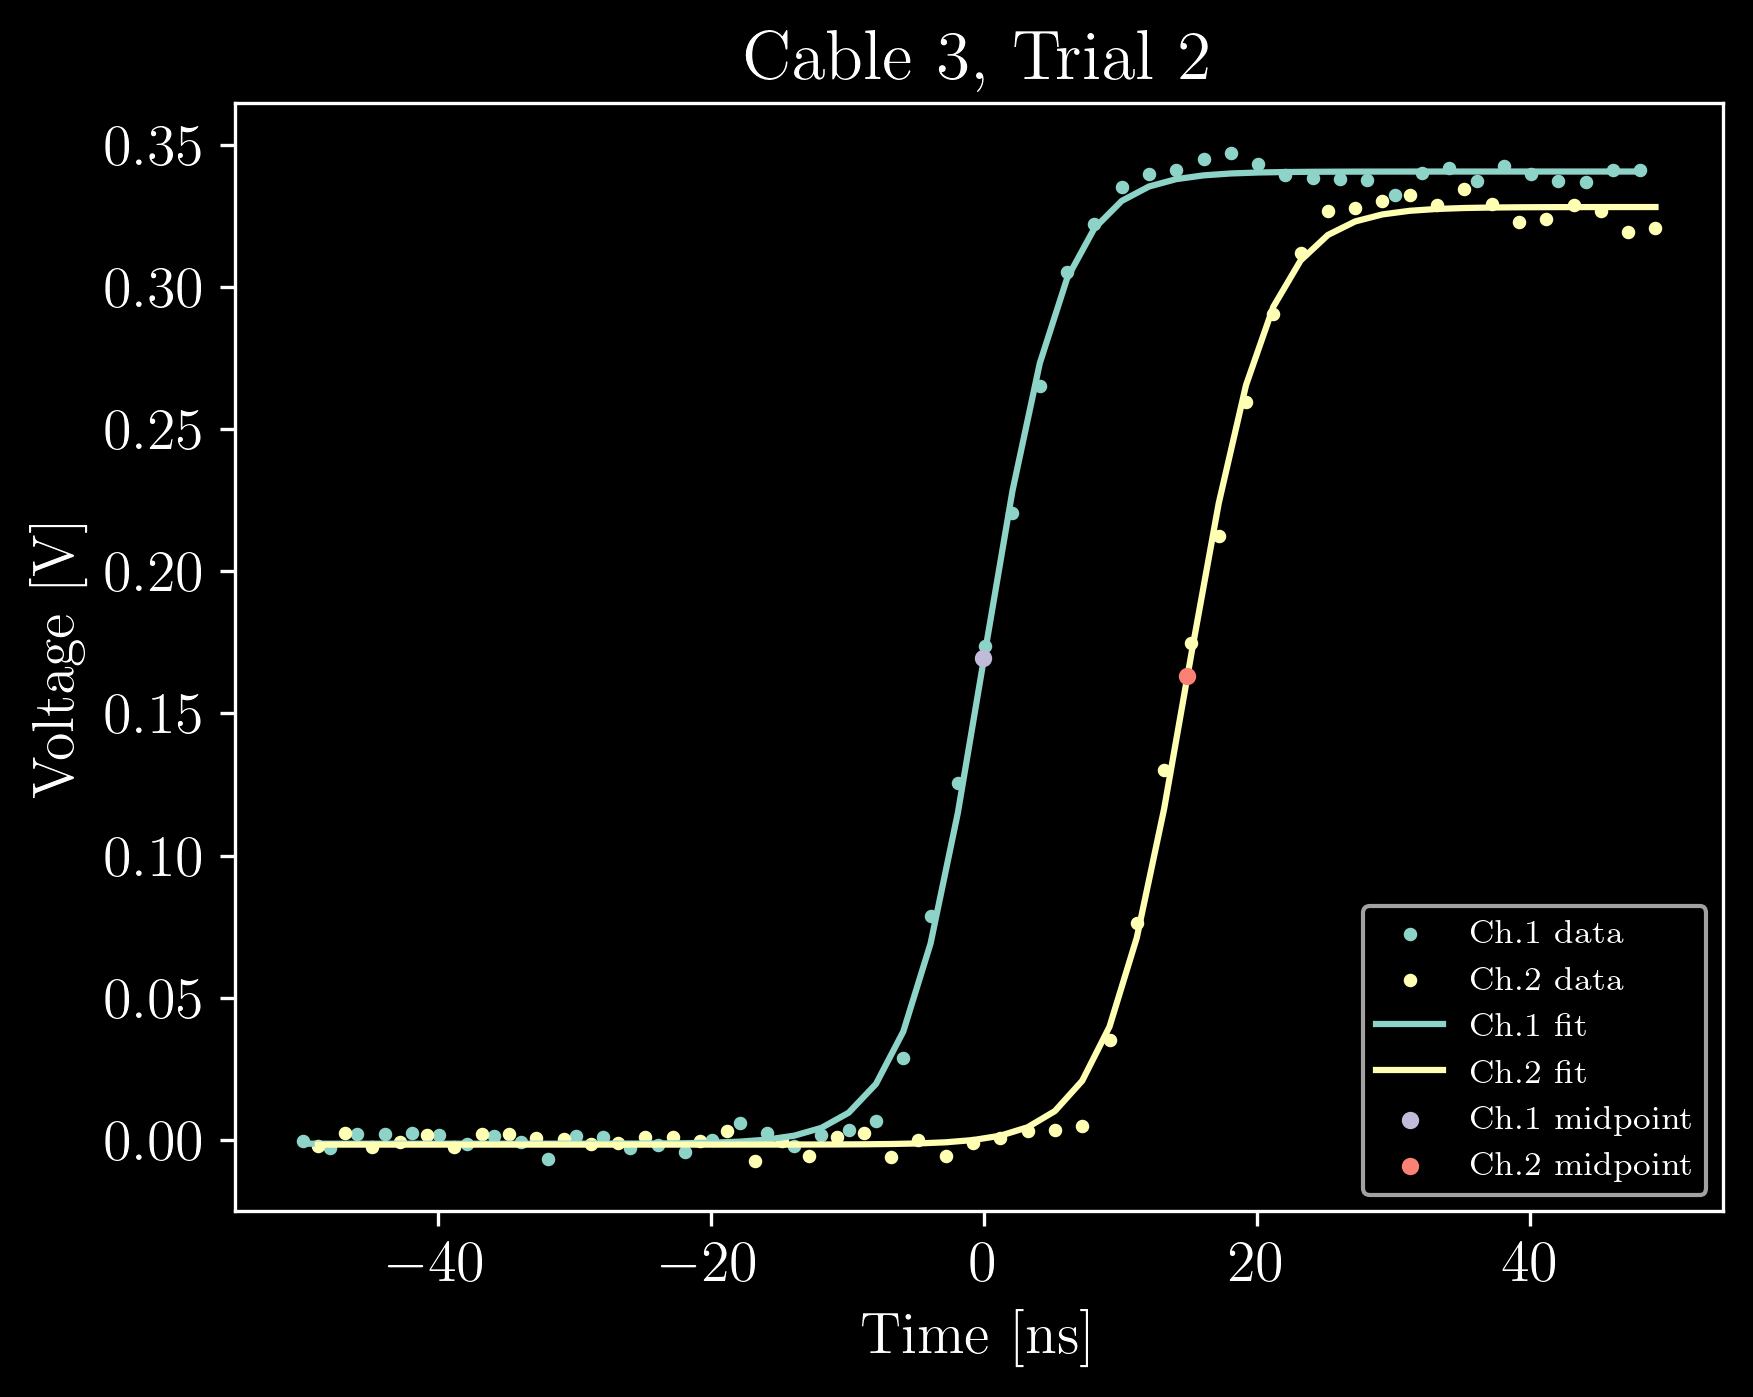

In [ ]:
tdelay_Cable3_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable3_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.88150117985300*10, 
               title='Cable 3, Trial 2')

#### Trial 3

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.82109347458106E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.884115065693319 ns


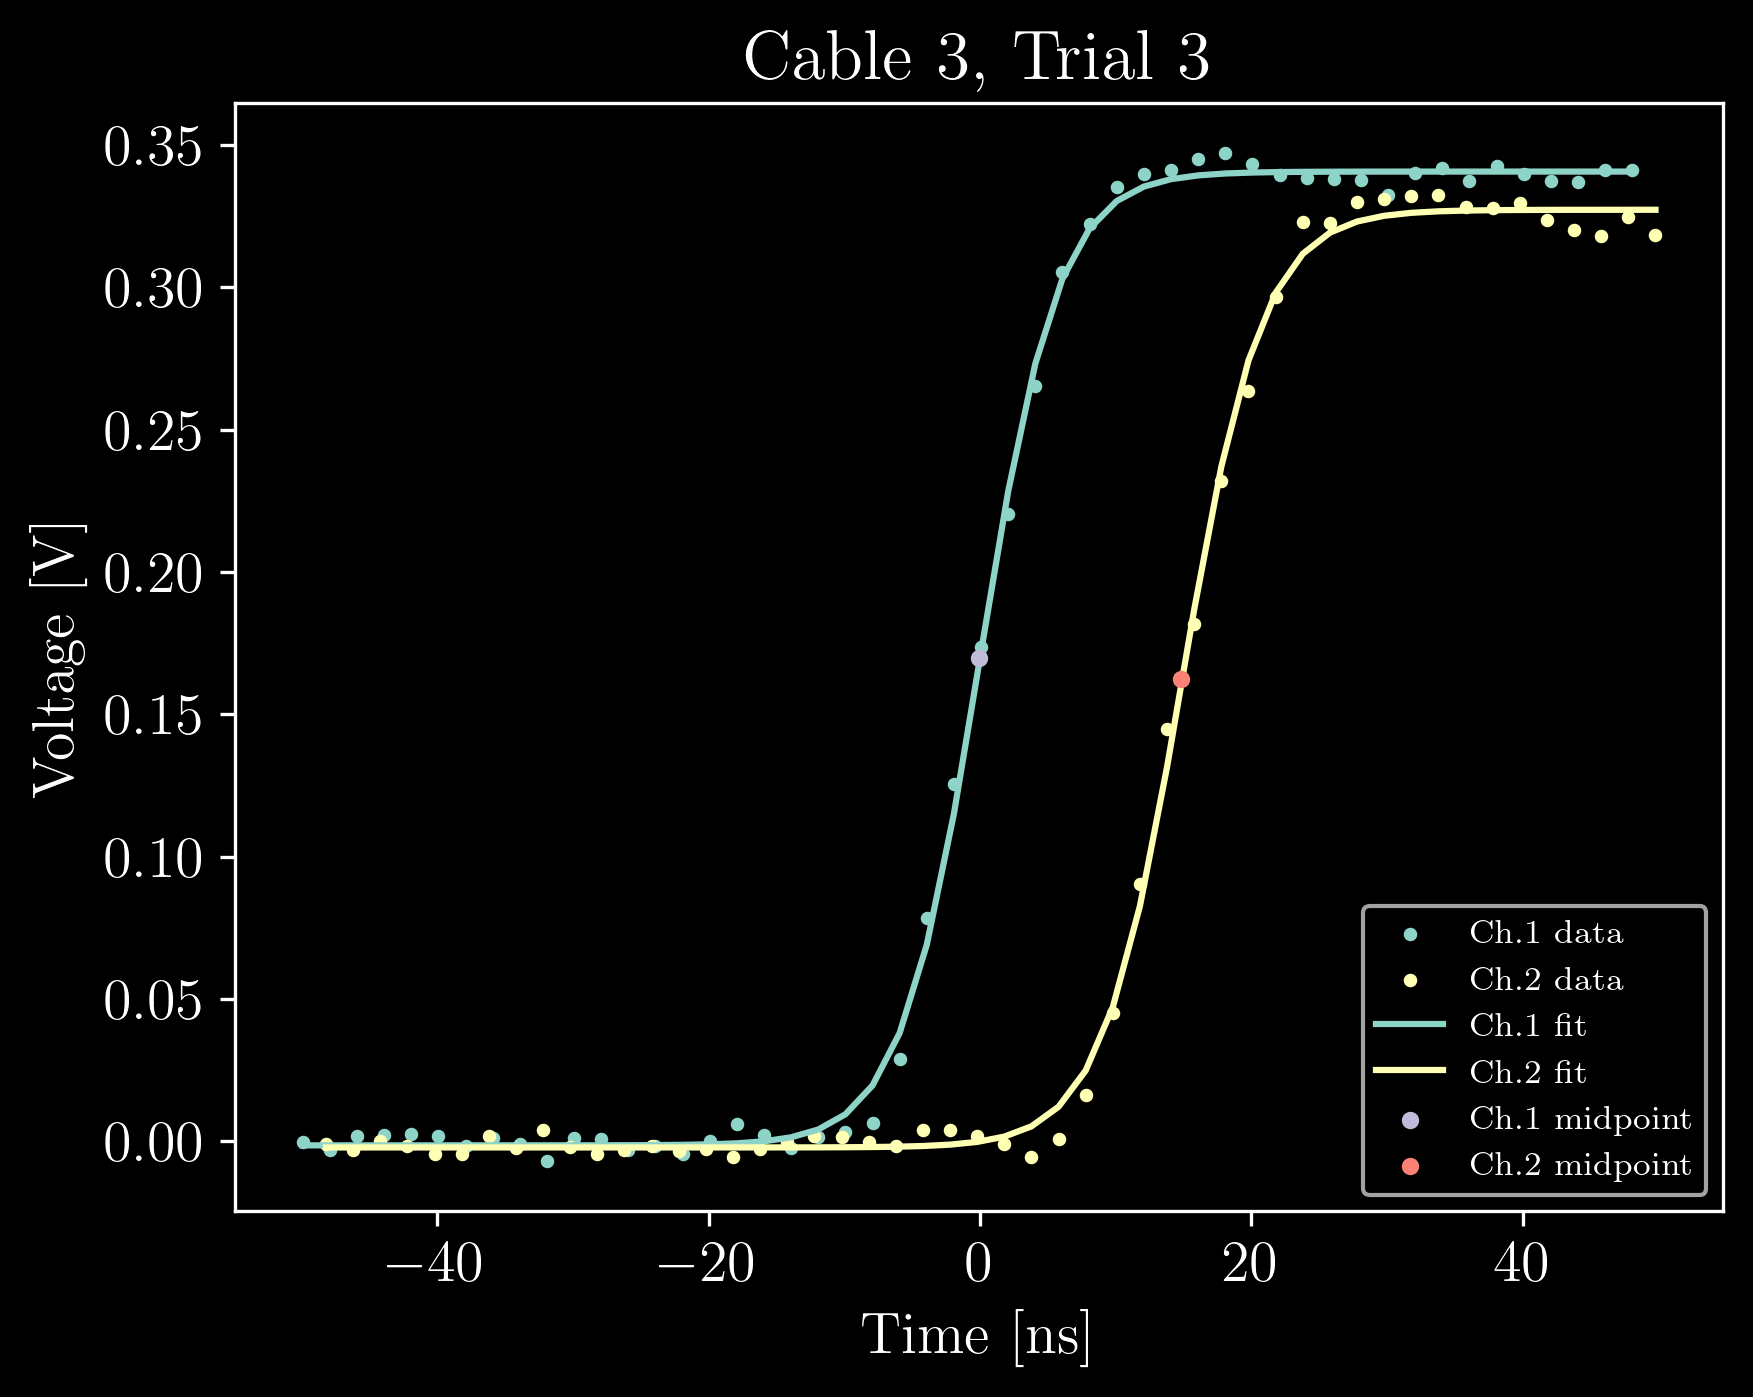

In [ ]:
tdelay_Cable3_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable3_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.82109347458106*10, 
               title='Cable 3, Trial 3')

#### Average

In [179]:
tdelay_Cable3_avg = (tdelay_Cable3_1+tdelay_Cable3_2+tdelay_Cable3_3)/3
print('Average time delay = ' + str(tdelay_Cable3_avg) + ' ns')

Average time delay = 14.896853377937873 ns


# Cable 4

Cable type: pink, medium length, thin (expect to see dispersion)

#### Trial 1

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.81372508409969E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.975727449499972 ns


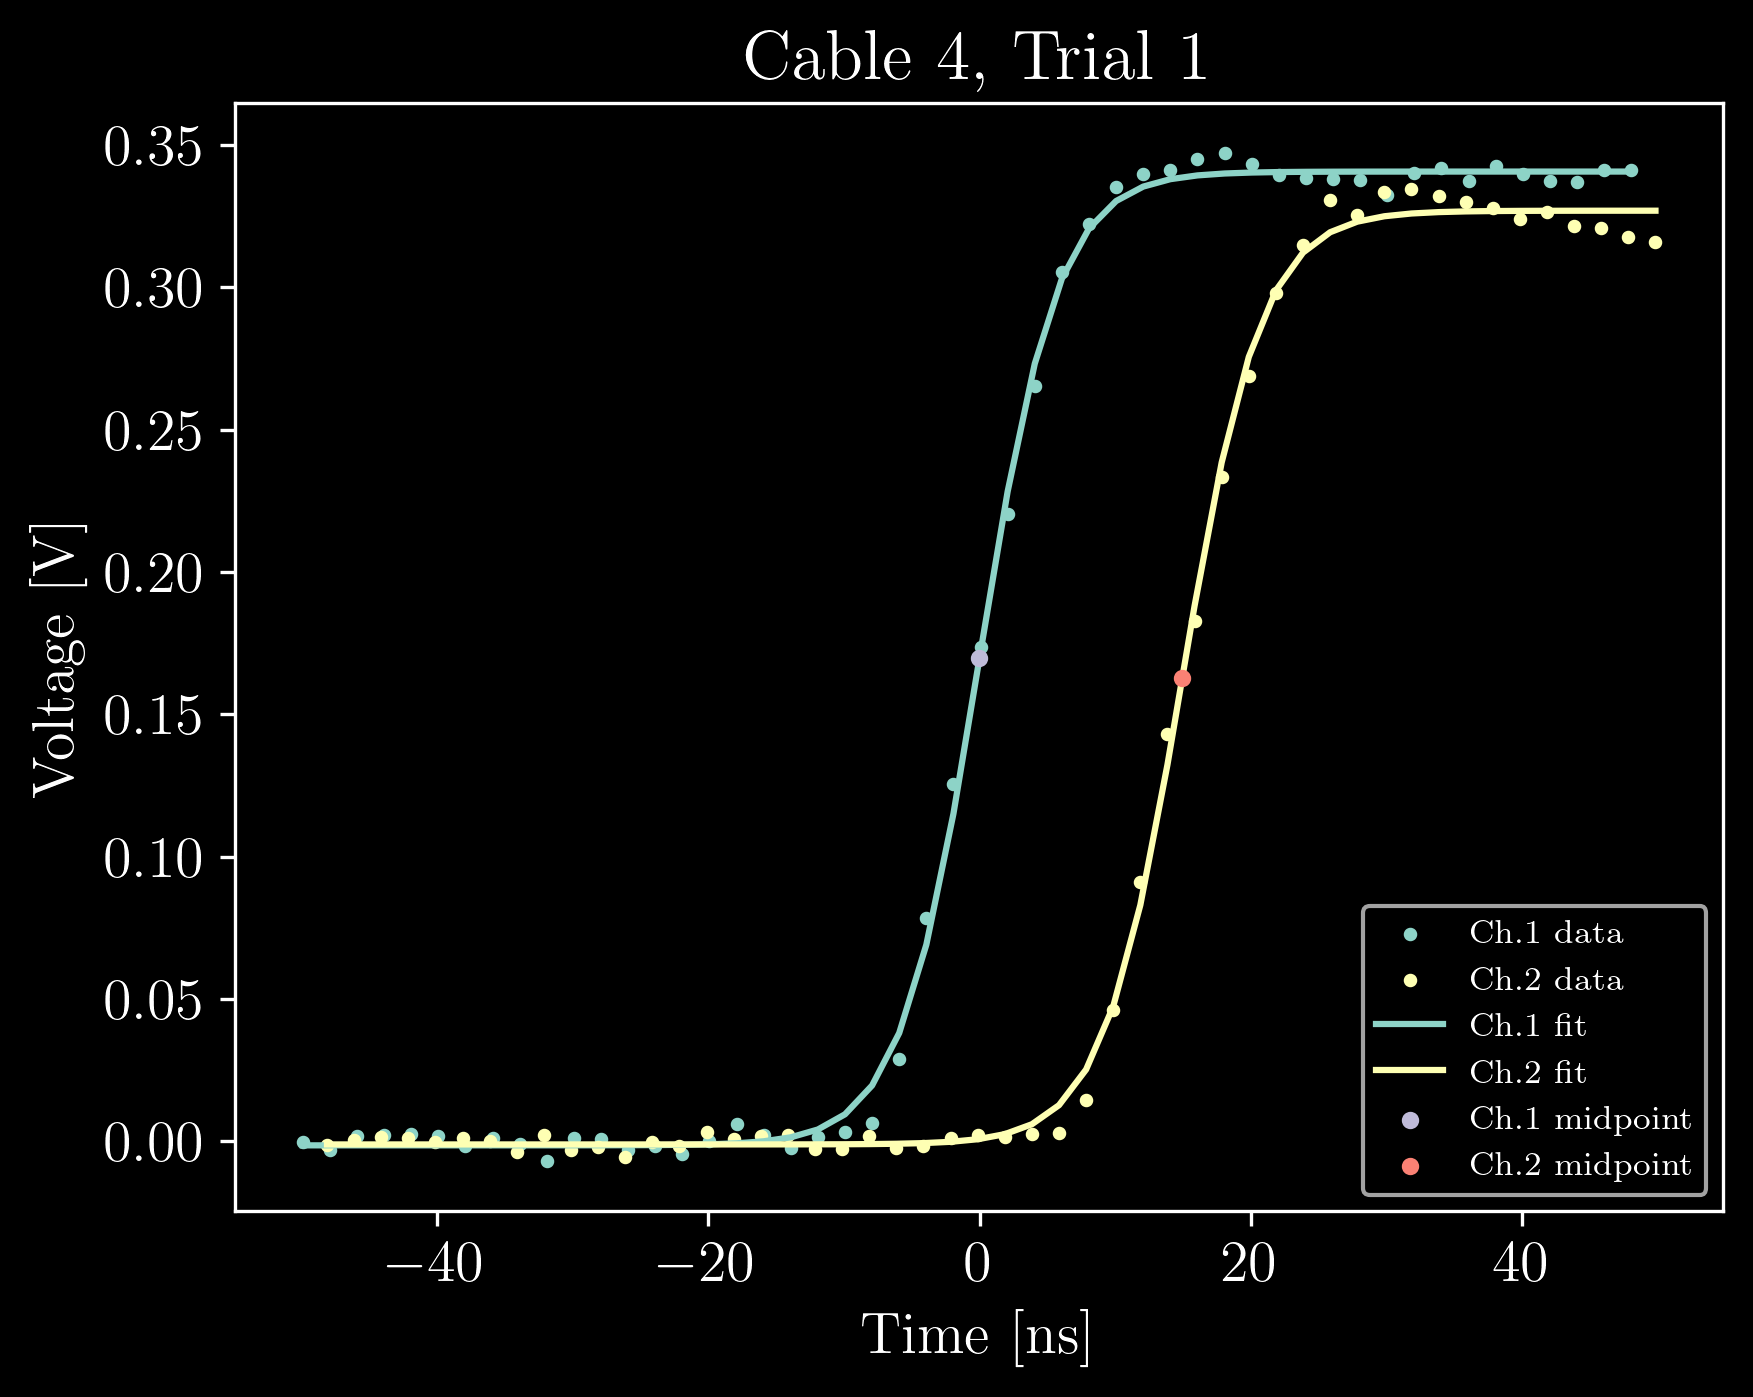

In [ ]:
tdelay_Cable4_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable4_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.81372508409969*10, 
               title='Cable 4, Trial 1')

#### Trial 2

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.93828000421884E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.845325477583609 ns


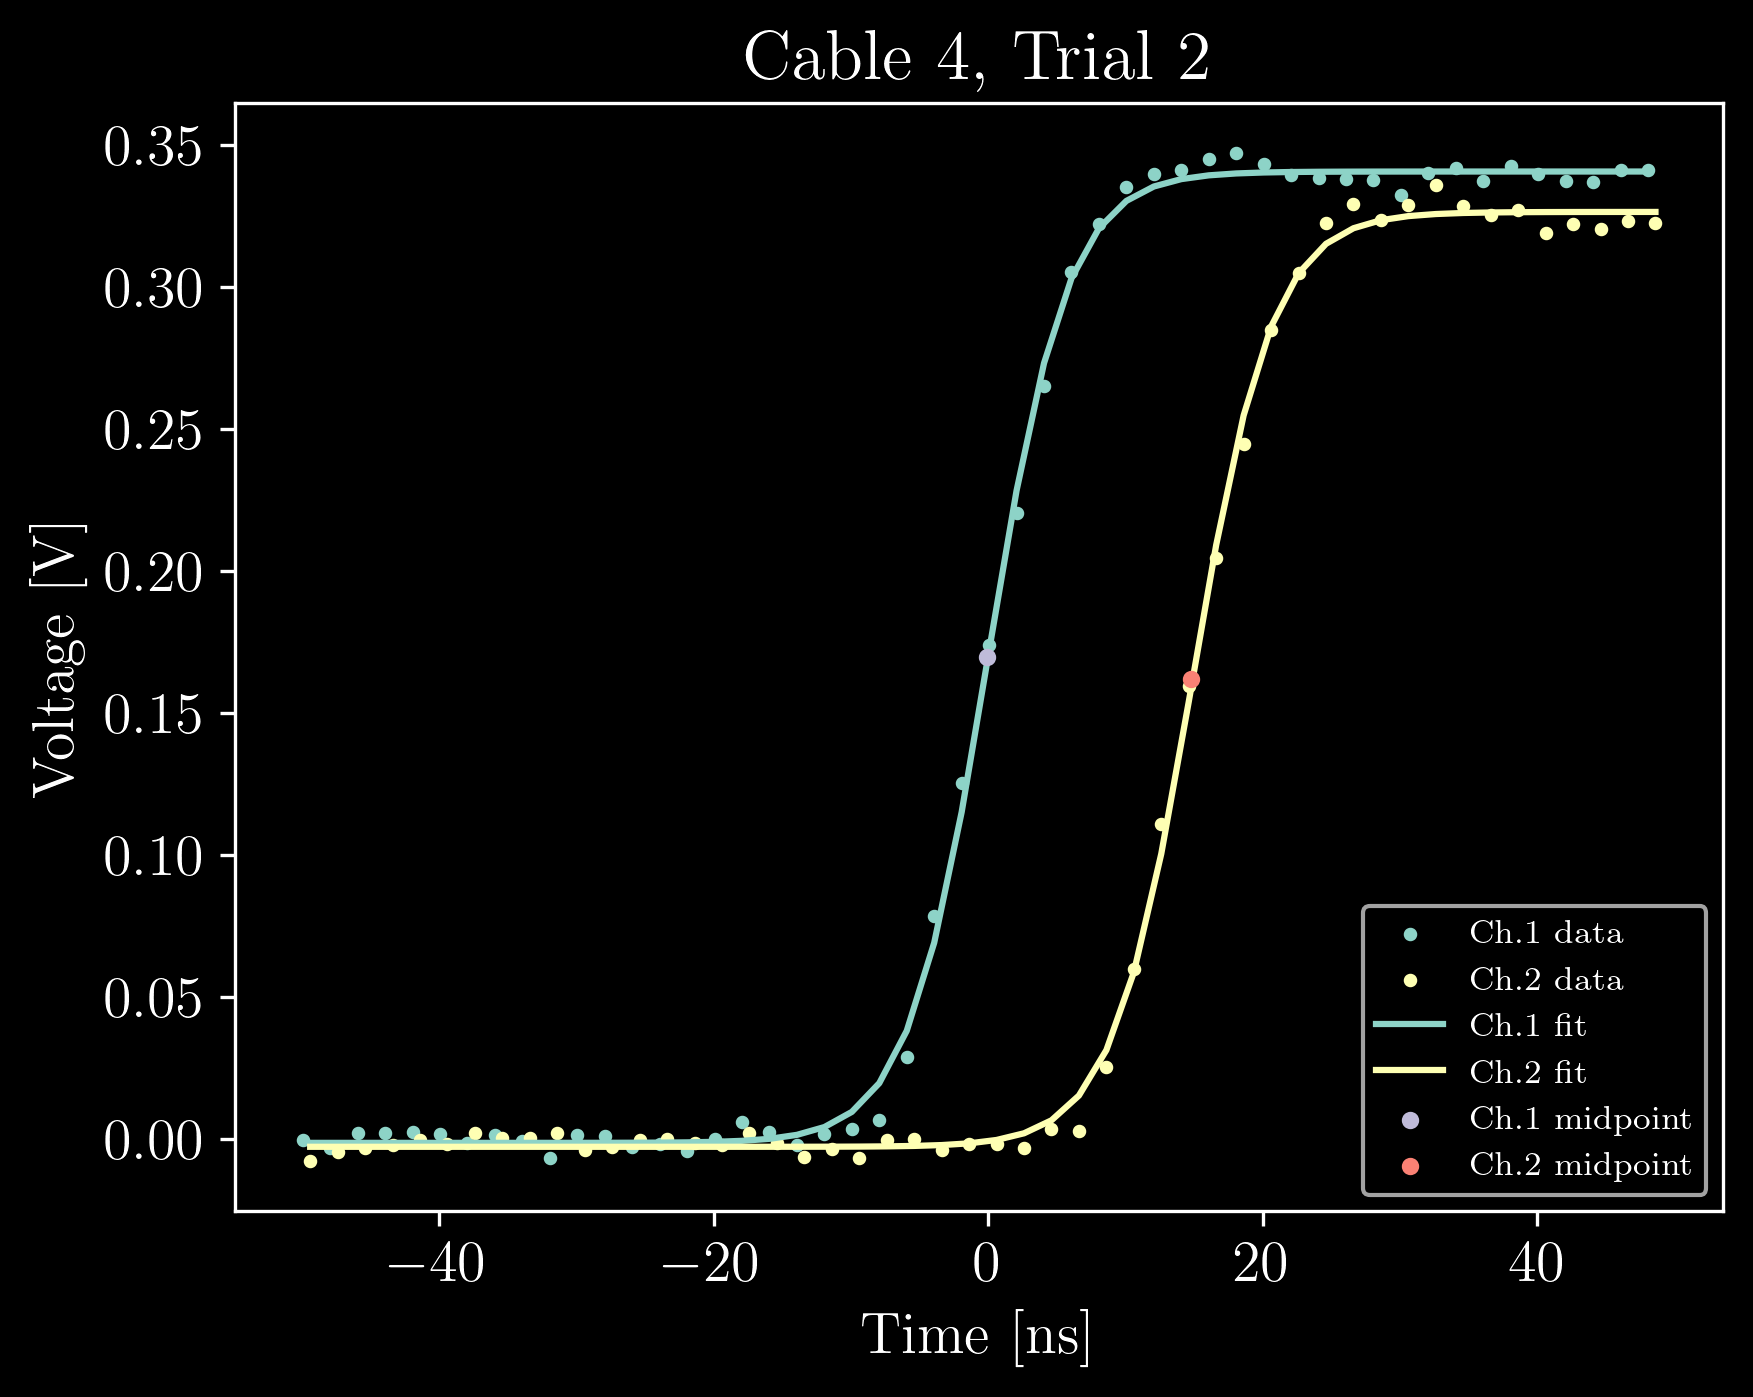

In [ ]:
tdelay_Cable4_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable4_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.93828000421884*10, 
               title='Cable 4, Trial 2')

#### Trial 3

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.86148019294272E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 14.988193810027177 ns


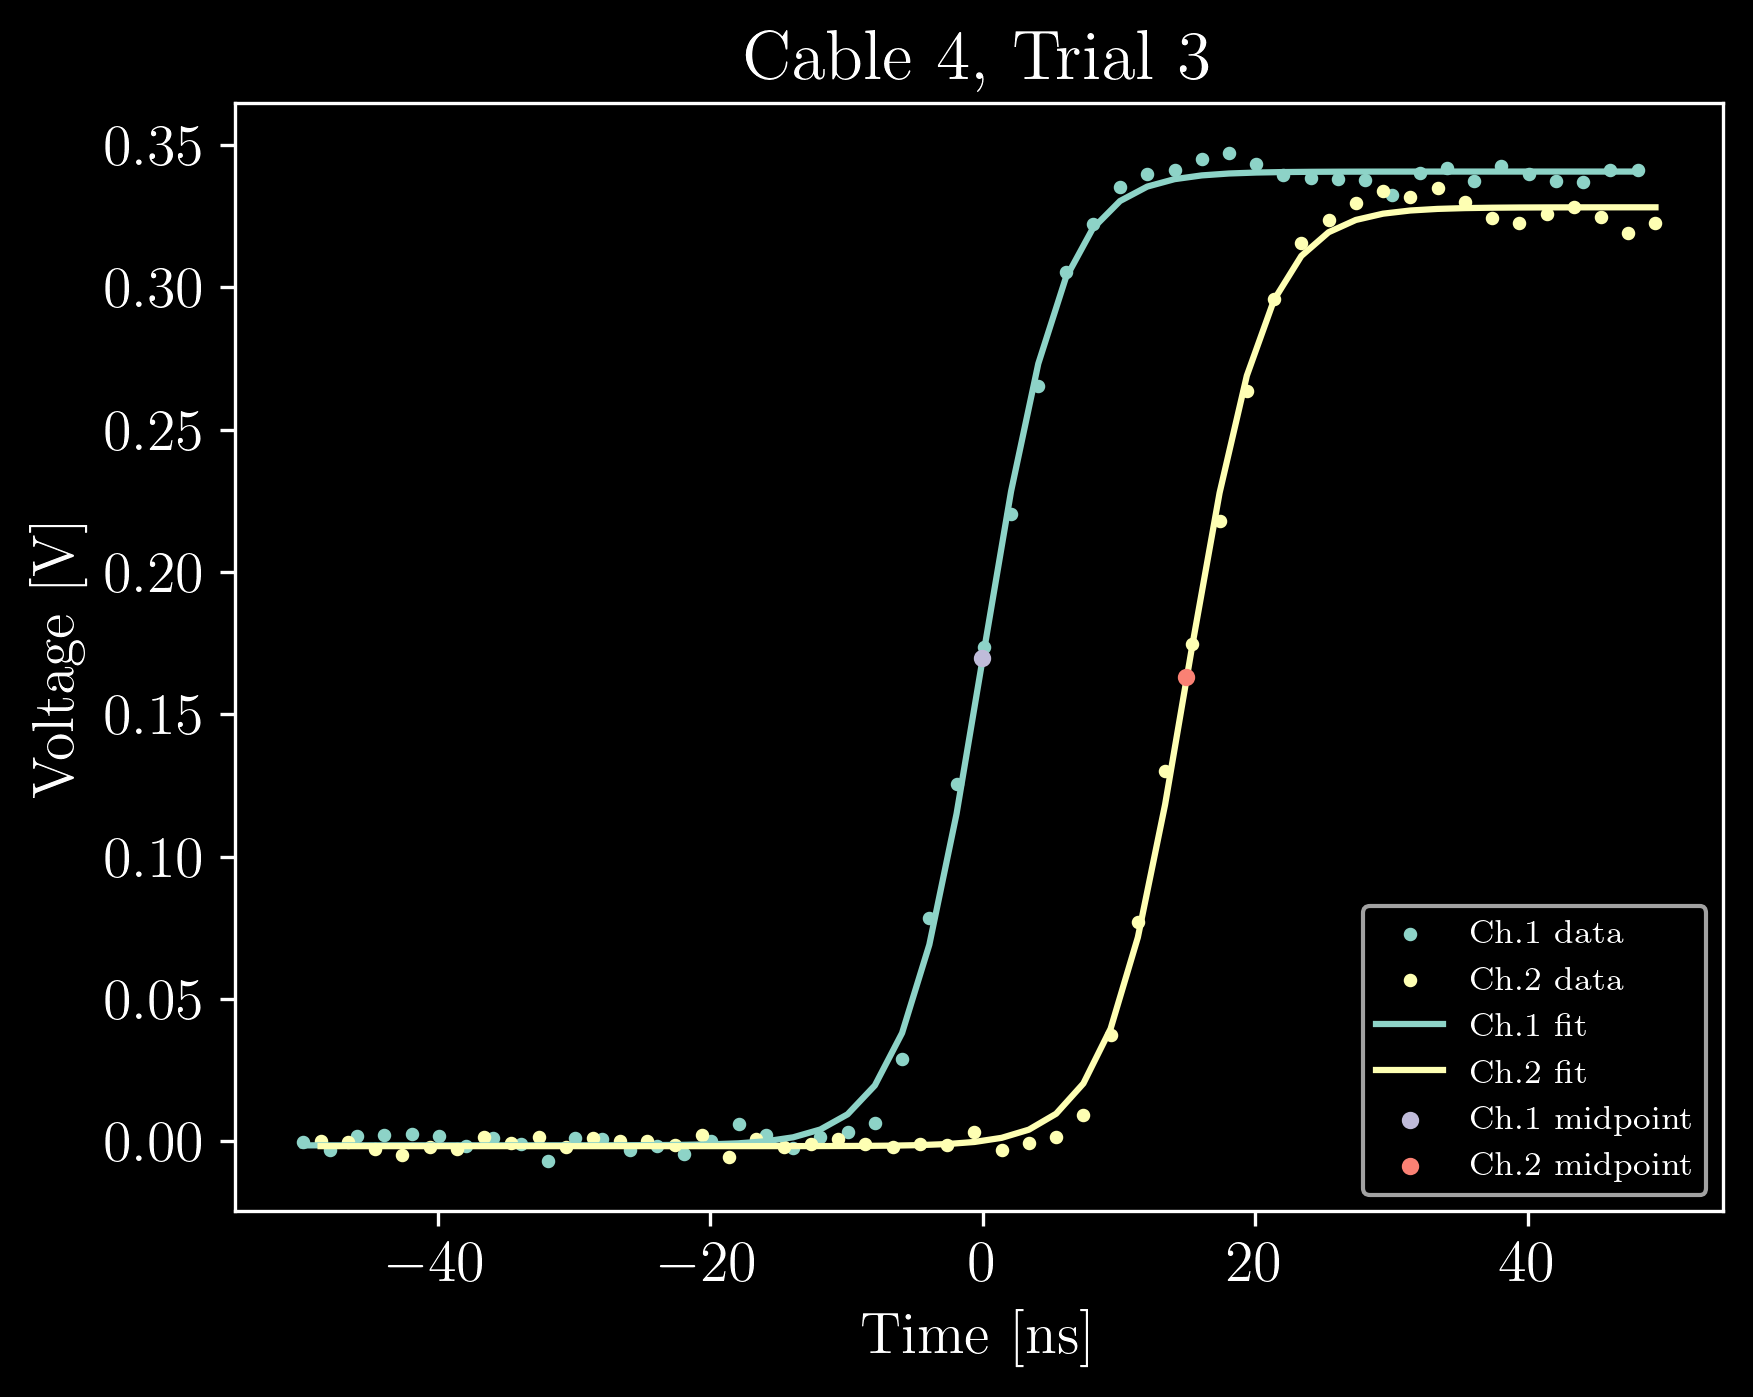

In [ ]:
tdelay_Cable4_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable4_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.86148019294272*10, 
               title='Cable 4, Trial 3')

#### Average

In [183]:
tdelay_Cable4_avg = (tdelay_Cable4_1+tdelay_Cable4_2+tdelay_Cable4_3)/3
print('Average time delay = ' + str(tdelay_Cable4_avg) + ' ns')

Average time delay = 14.936415579036918 ns


# Cable 5

Cable type: black, short, medium thickness

#### Trial 1

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.89818299700971E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 3.9435509314048085 ns


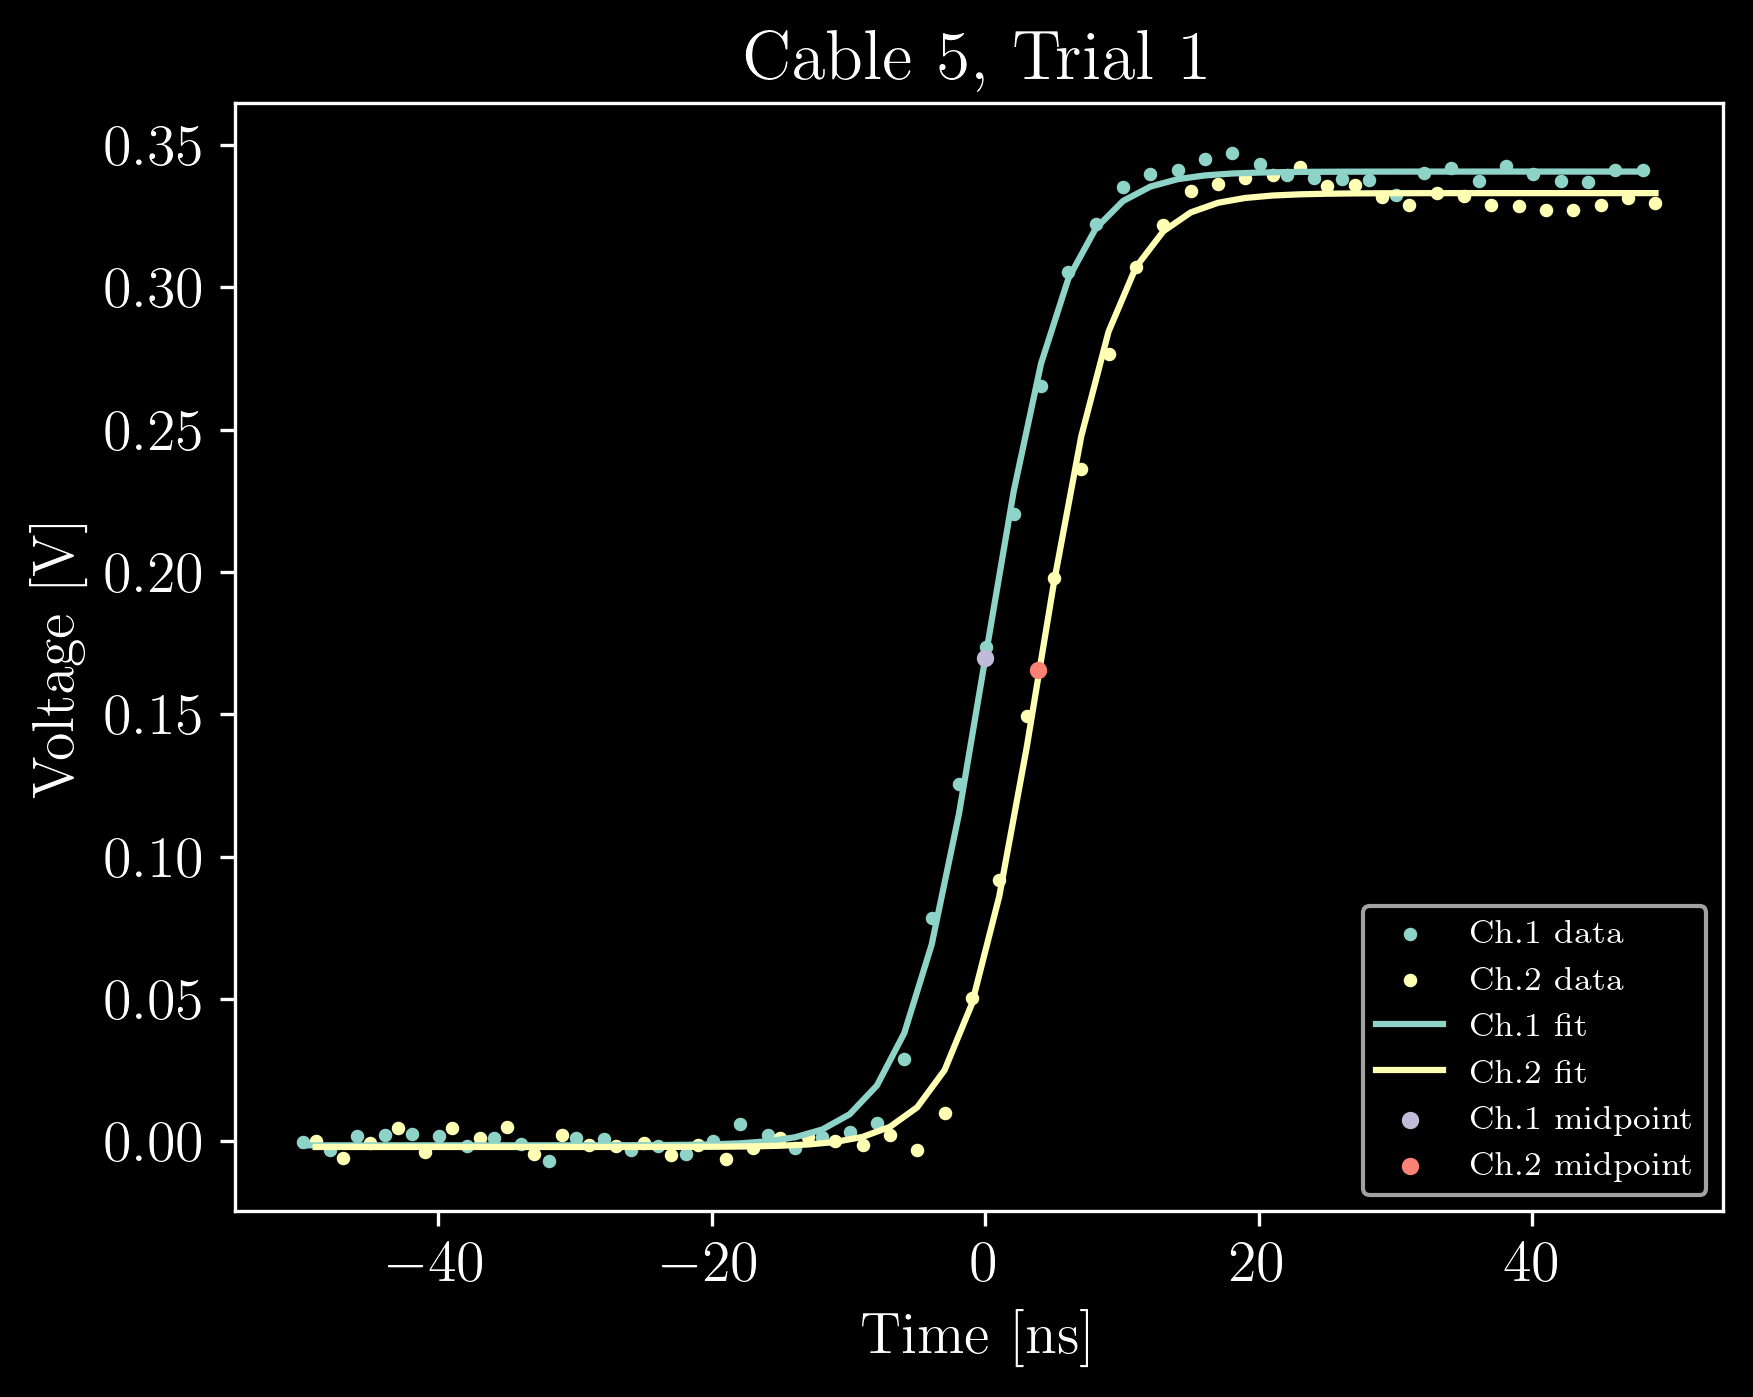

In [ ]:
tdelay_Cable5_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable5_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.89818299700971*10, 
               title='Cable 5, Trial 1')

#### Trial 2

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.92134028539239E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 3.9461377273209113 ns


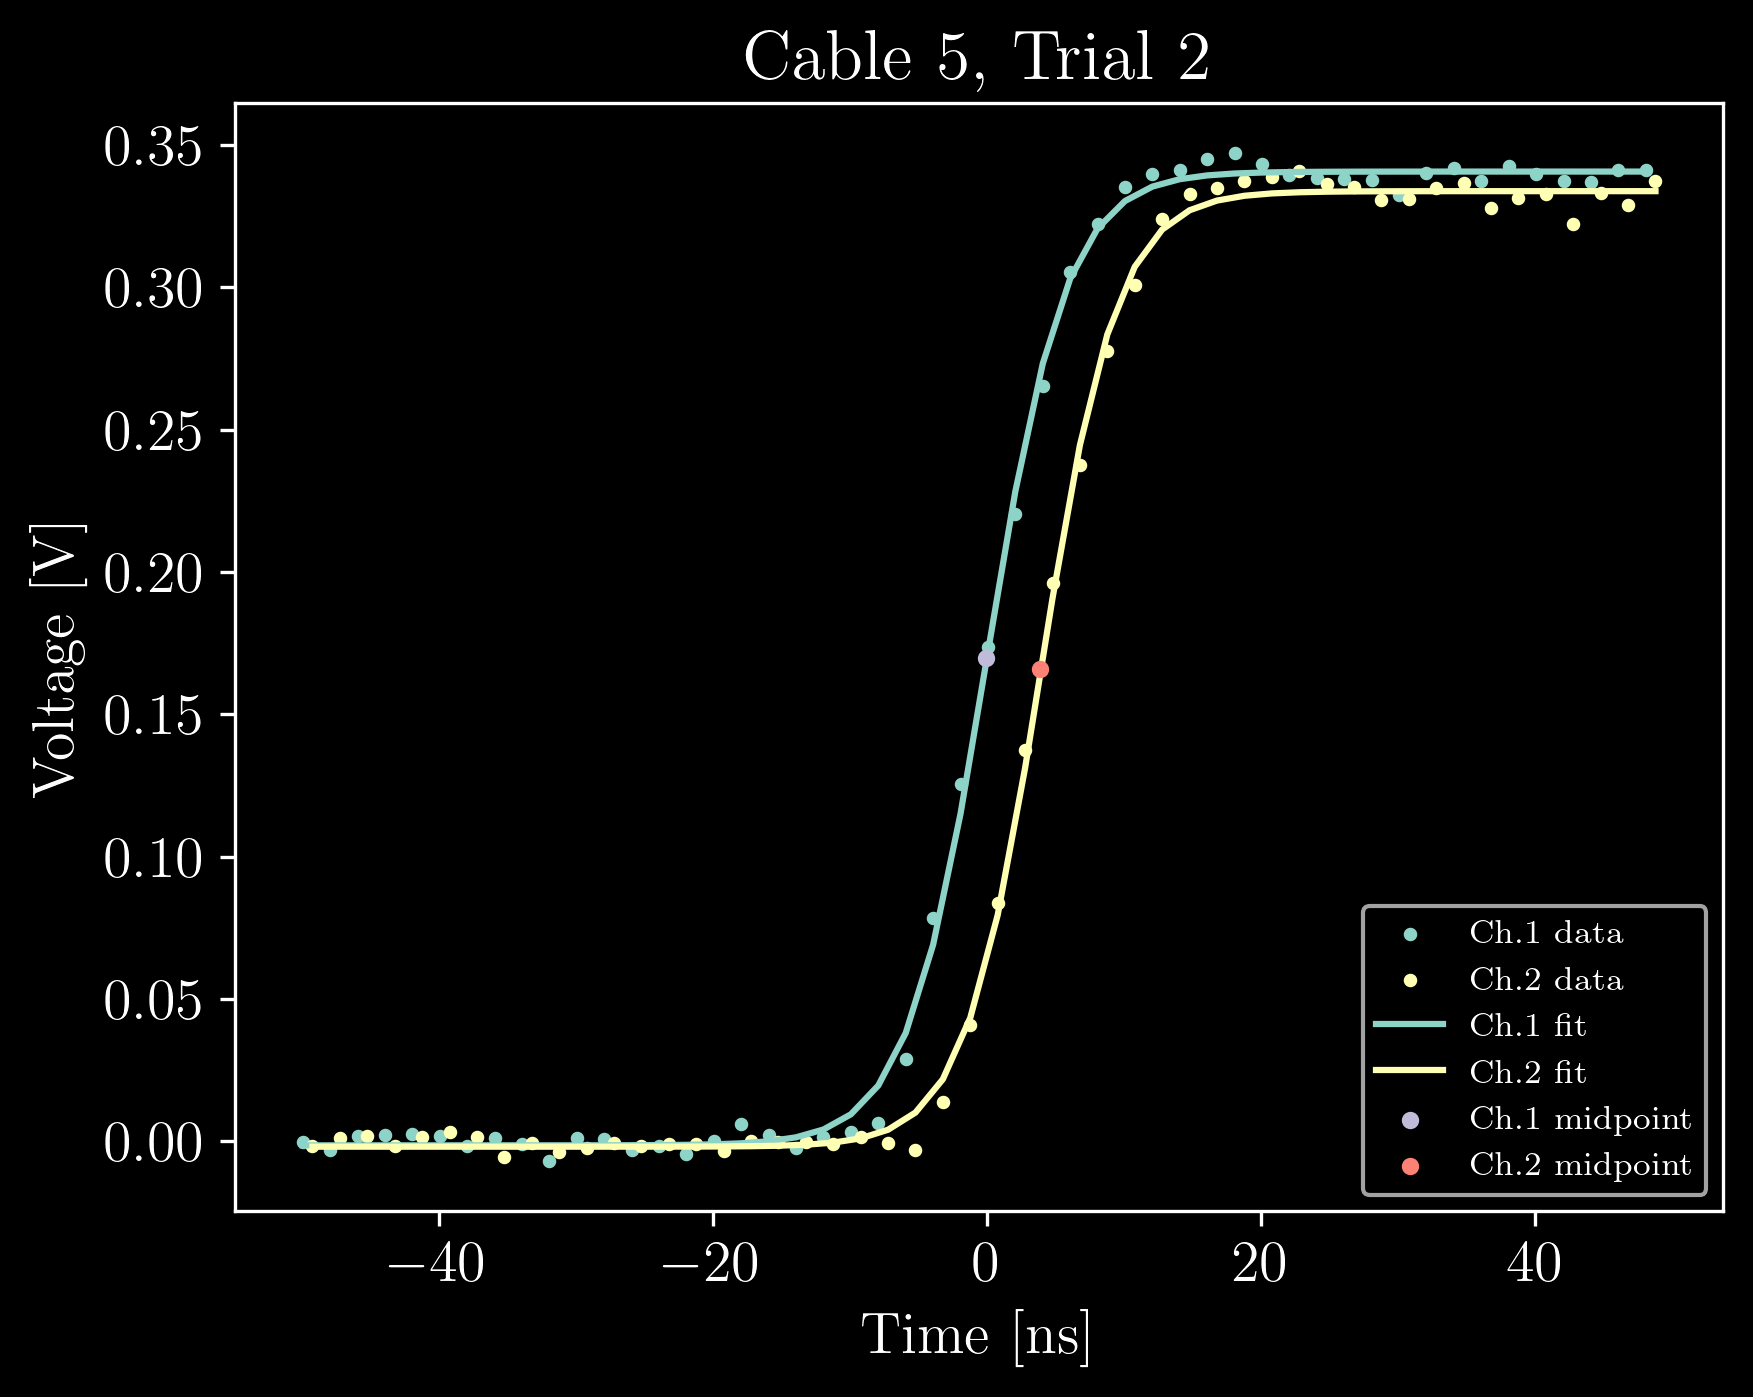

In [ ]:
tdelay_Cable5_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable5_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.92134028539239*10, 
               title='Cable 5, Trial 2')

#### Trial 3

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.93831468849984E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 3.96696995939869 ns


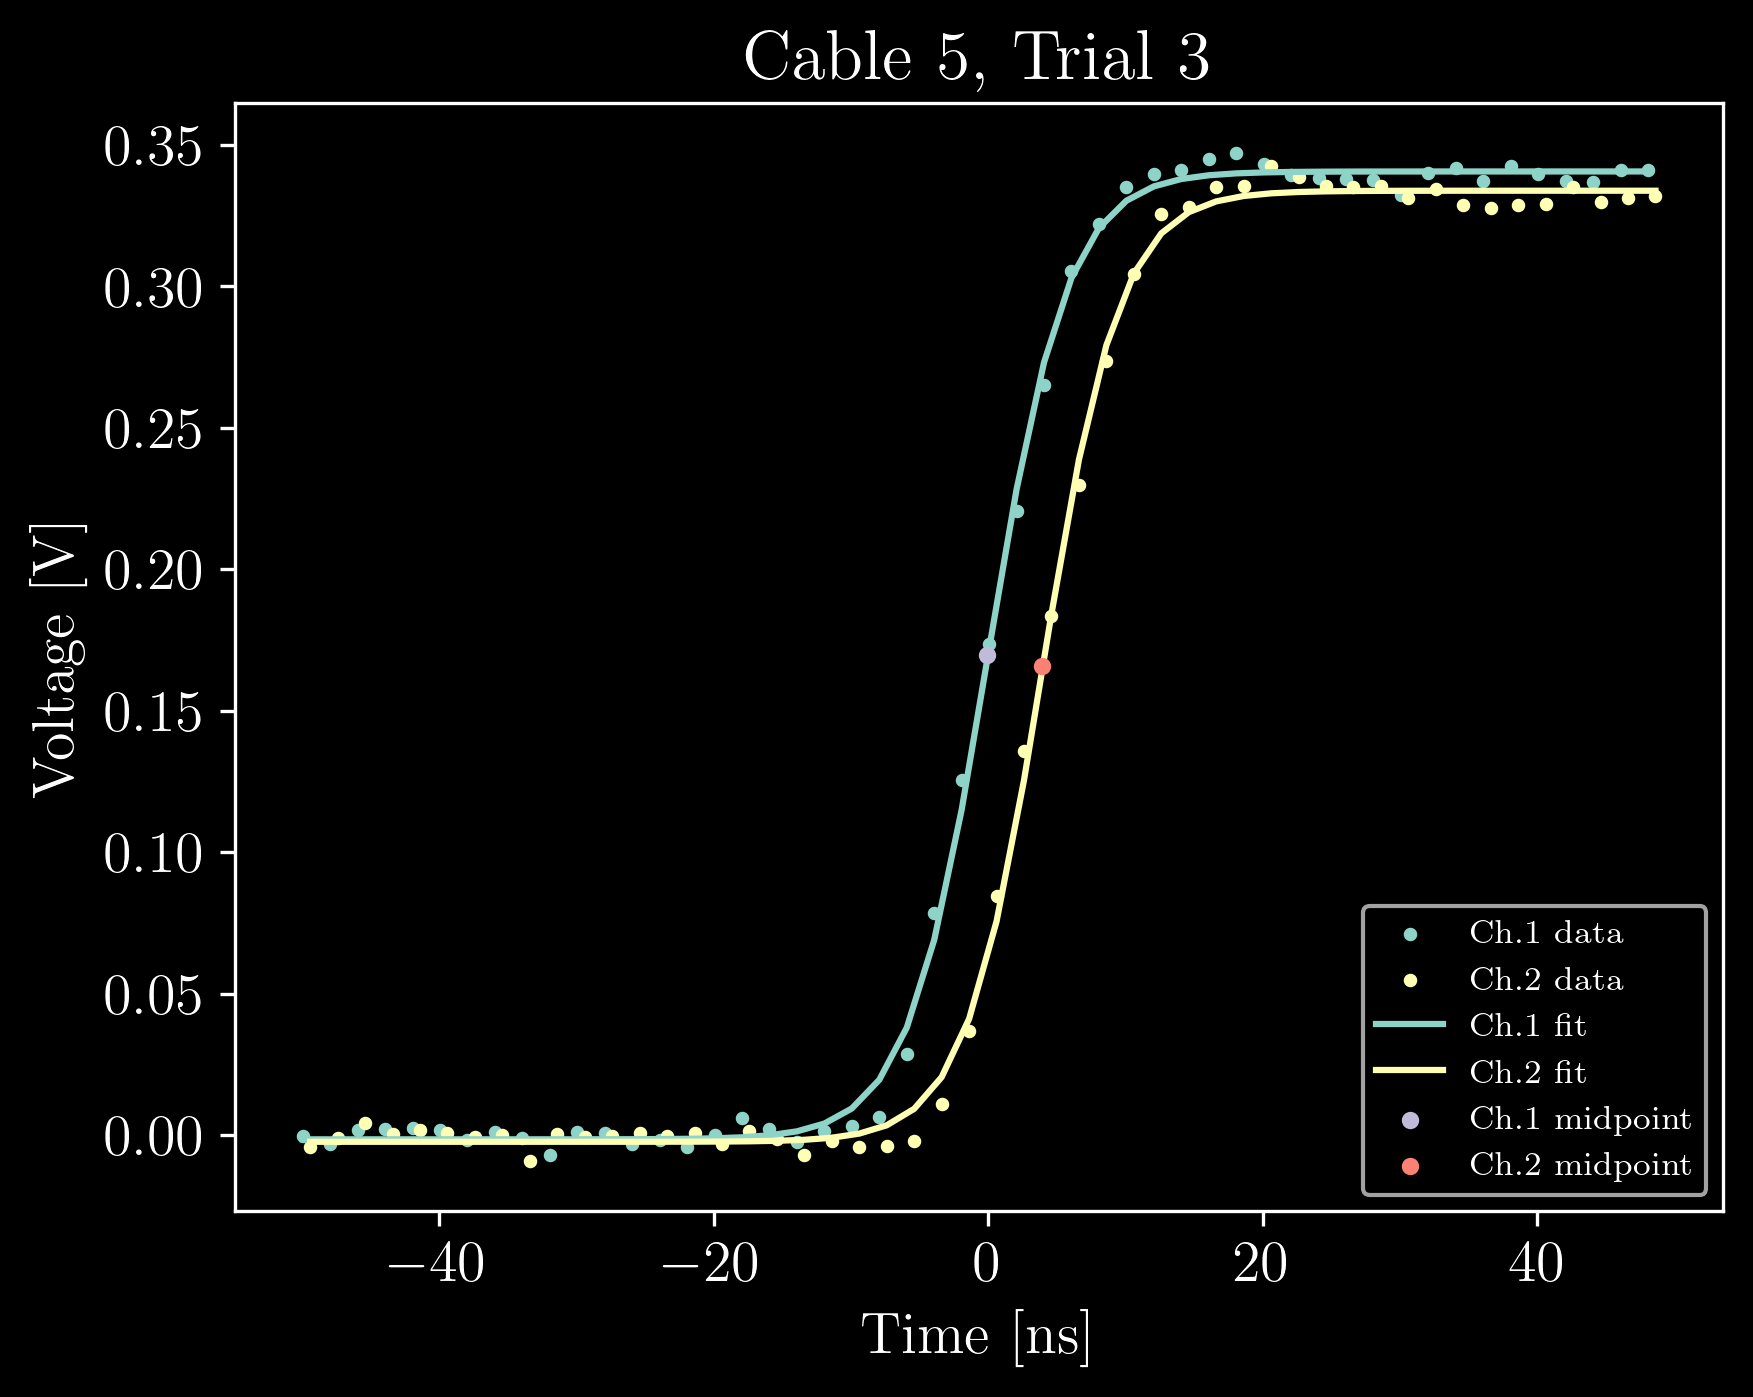

In [ ]:
tdelay_Cable5_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable5_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.93831468849984*10, 
               title='Cable 5, Trial 3')

#### Average

In [188]:
tdelay_Cable5_avg = (tdelay_Cable5_1+tdelay_Cable5_2+tdelay_Cable5_3)/3
print('Average time delay = ' + str(tdelay_Cable5_avg) + ' ns')

Average time delay = 3.9522195393748034 ns


# Cable 6

Cable type: black, short, medium thickness

#### Trial 1

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.85742454551967E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 4.012931085929392 ns


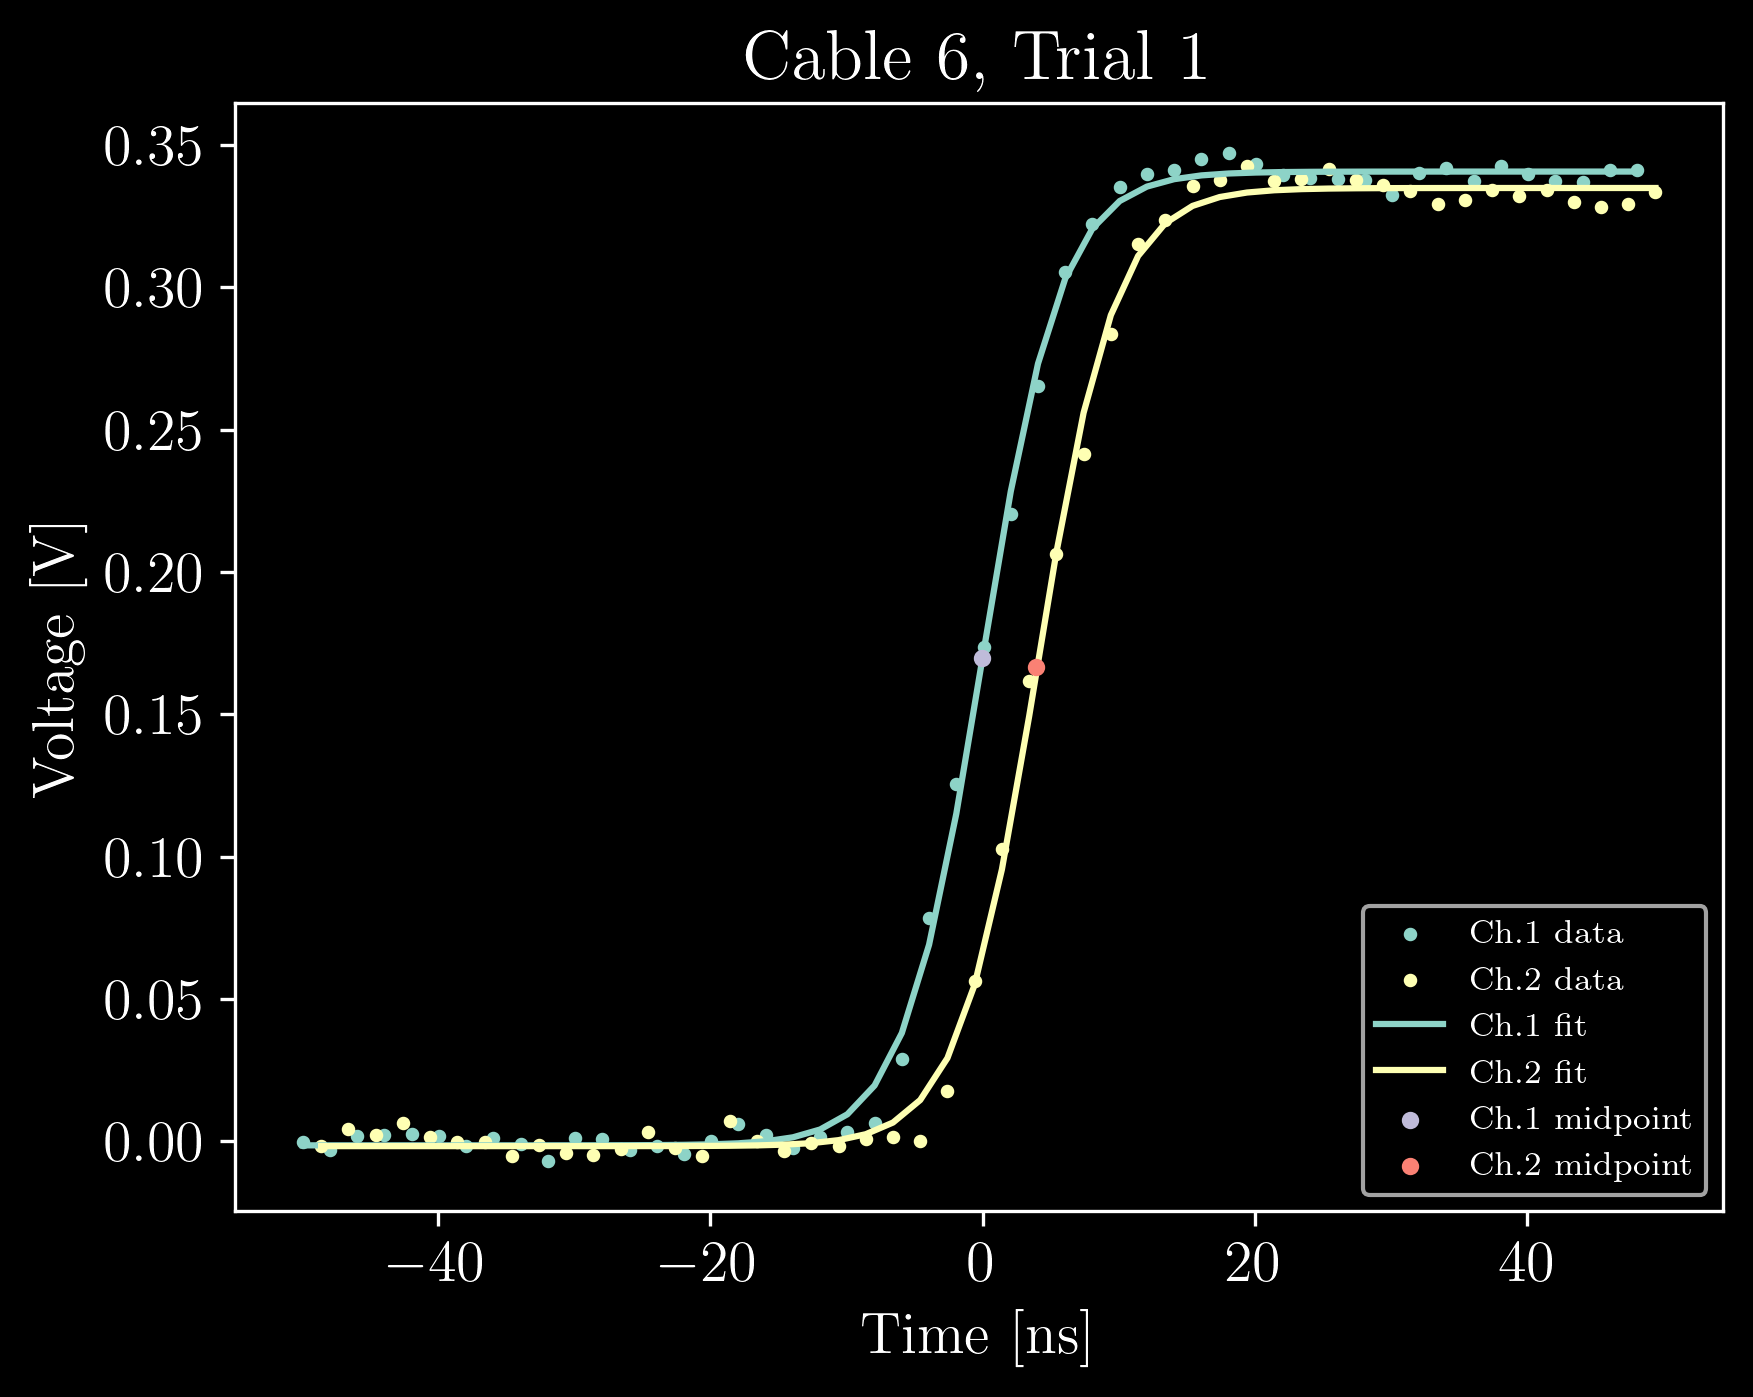

In [ ]:
tdelay_Cable6_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable6_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.85742454551967*10, 
               title='Cable 6, Trial 1')

#### Trial 2

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.88471453860583E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 3.9087745018099014 ns


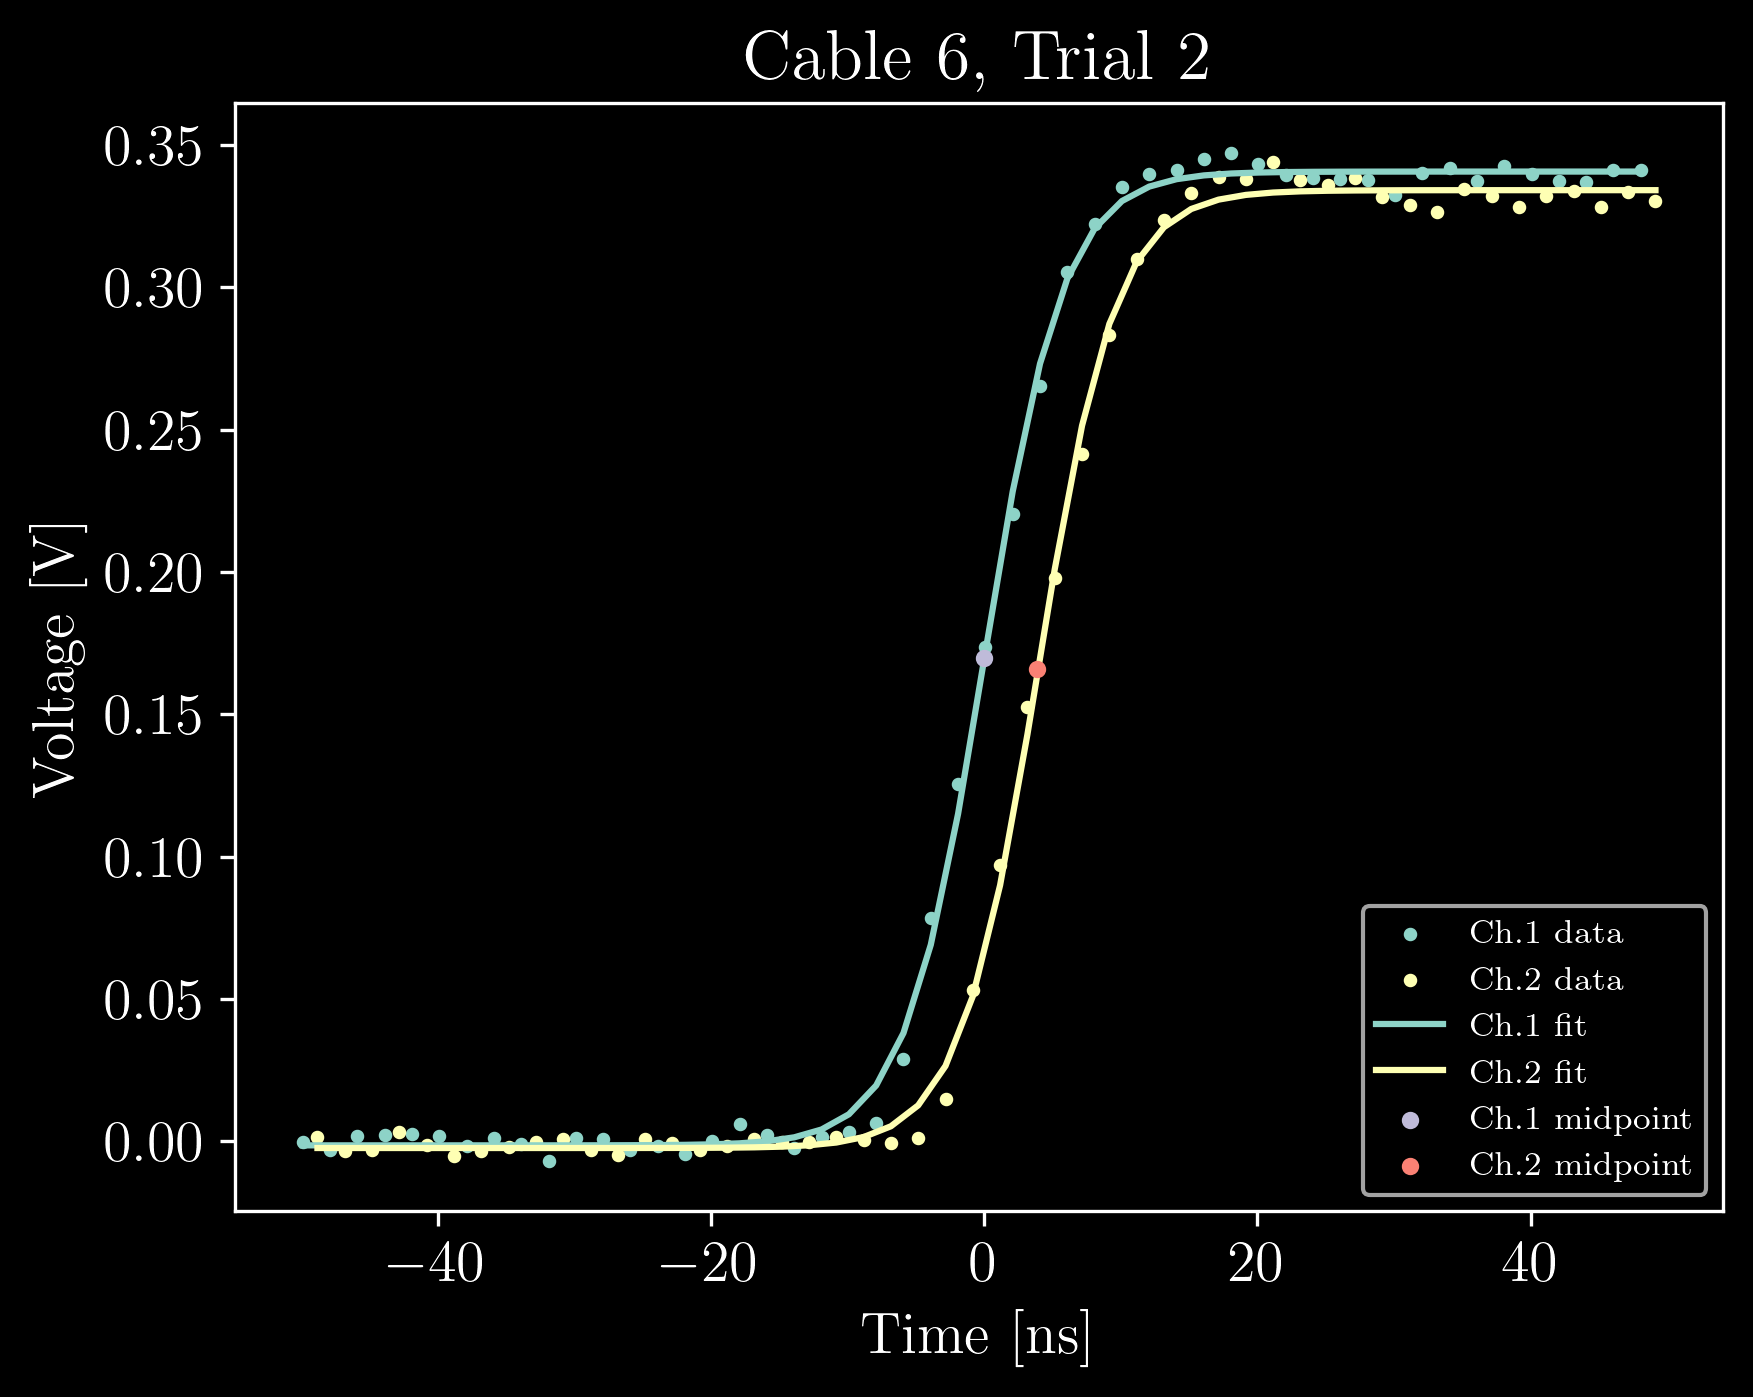

In [ ]:
tdelay_Cable6_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable6_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.88471453860583*10, 
               title='Cable 6, Trial 2')

#### Trial 3

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.97155515628908E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 3.8877351226727317 ns


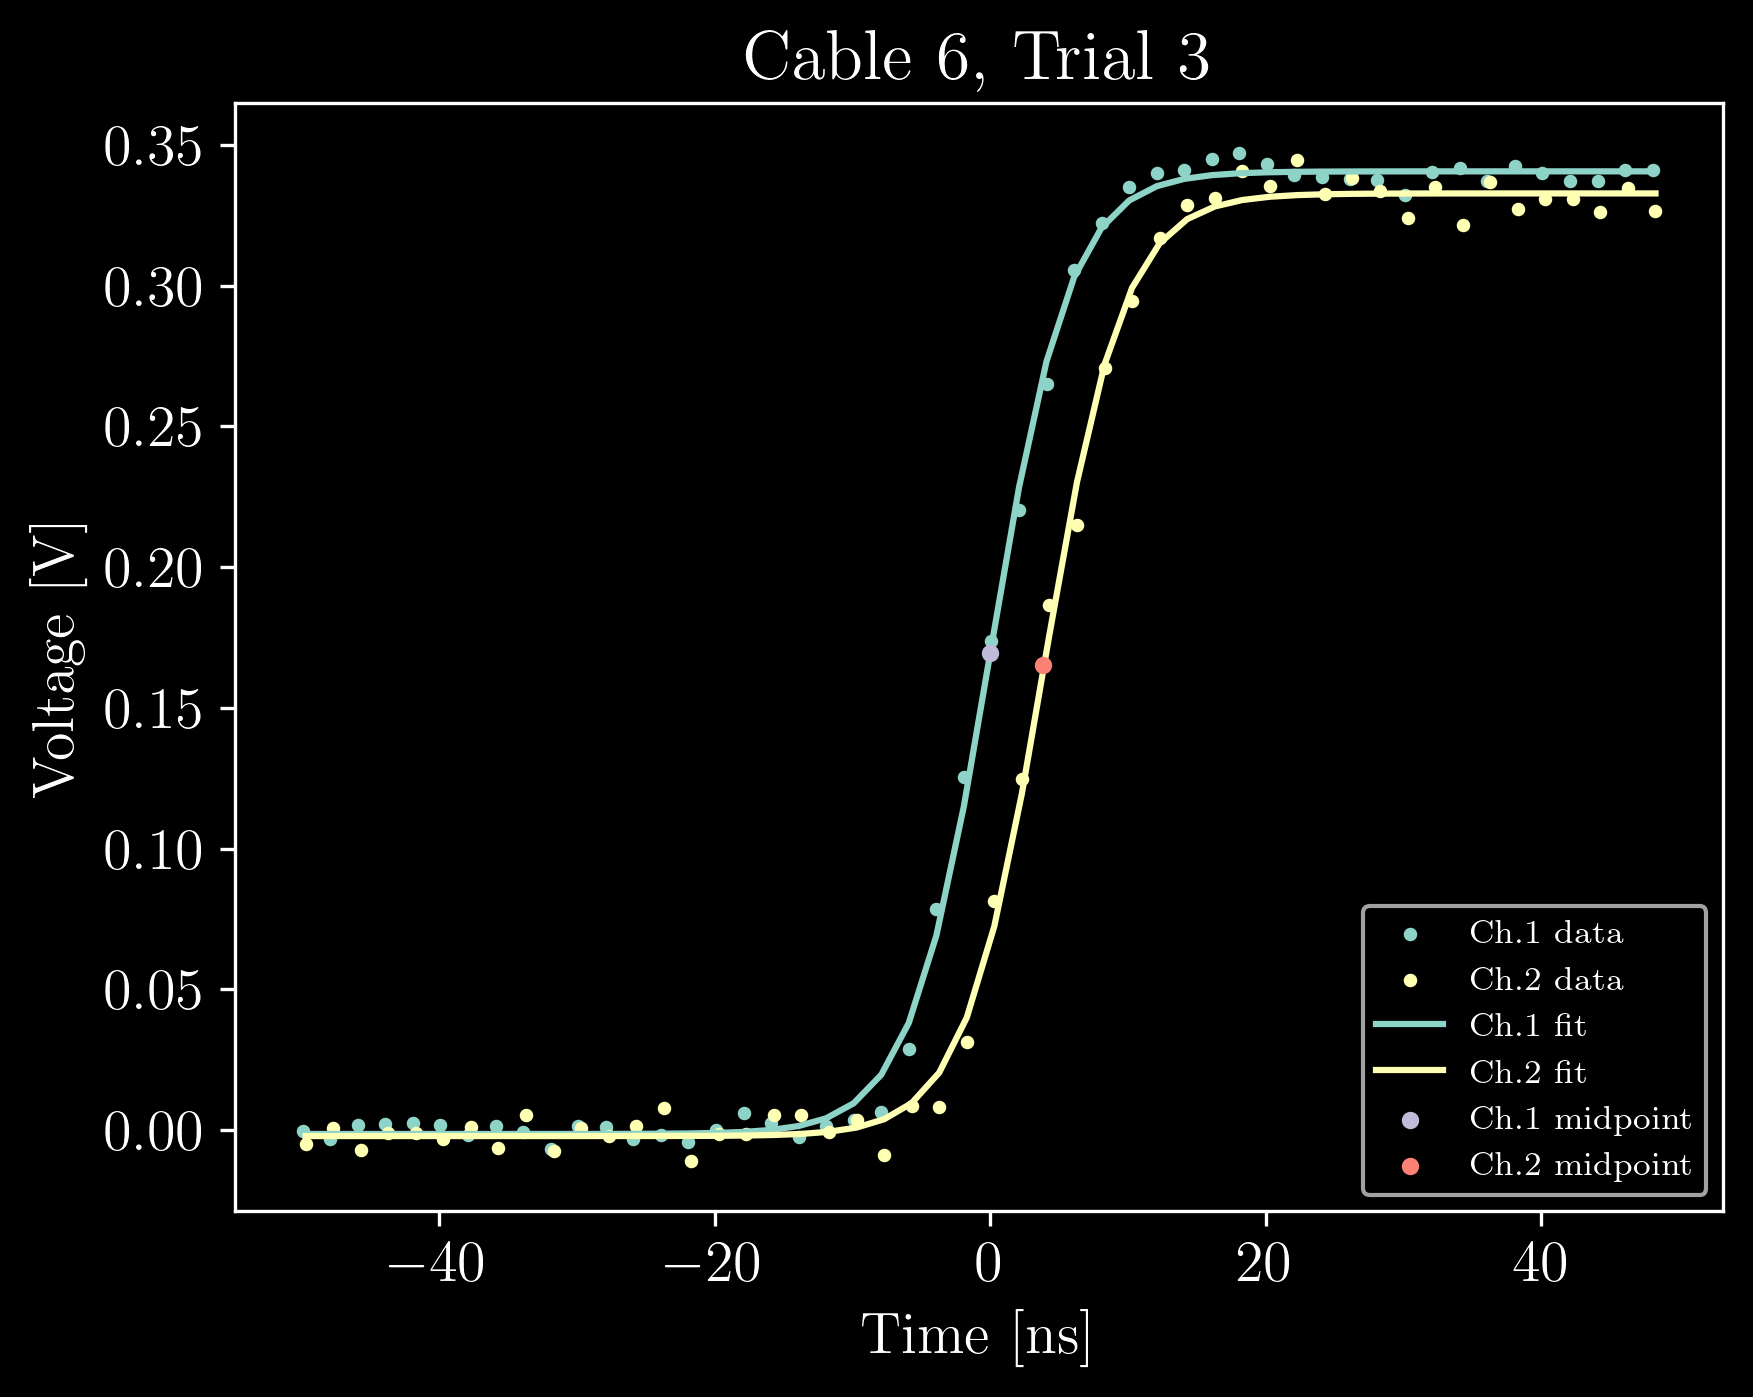

In [ ]:
tdelay_Cable6_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable6_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.97155515628908*10, 
               title='Cable 6, Trial 3')

#### Average

In [192]:
tdelay_Cable6_avg = (tdelay_Cable6_1+tdelay_Cable6_2+tdelay_Cable6_3)/3
print('Average time delay = ' + str(tdelay_Cable6_avg) + ' ns')

Average time delay = 3.9364802368040084 ns


# Cable 7

Cable type: black, short, medium thickness

#### Trial 1

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.84612590923300E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 3.9249931582074318 ns


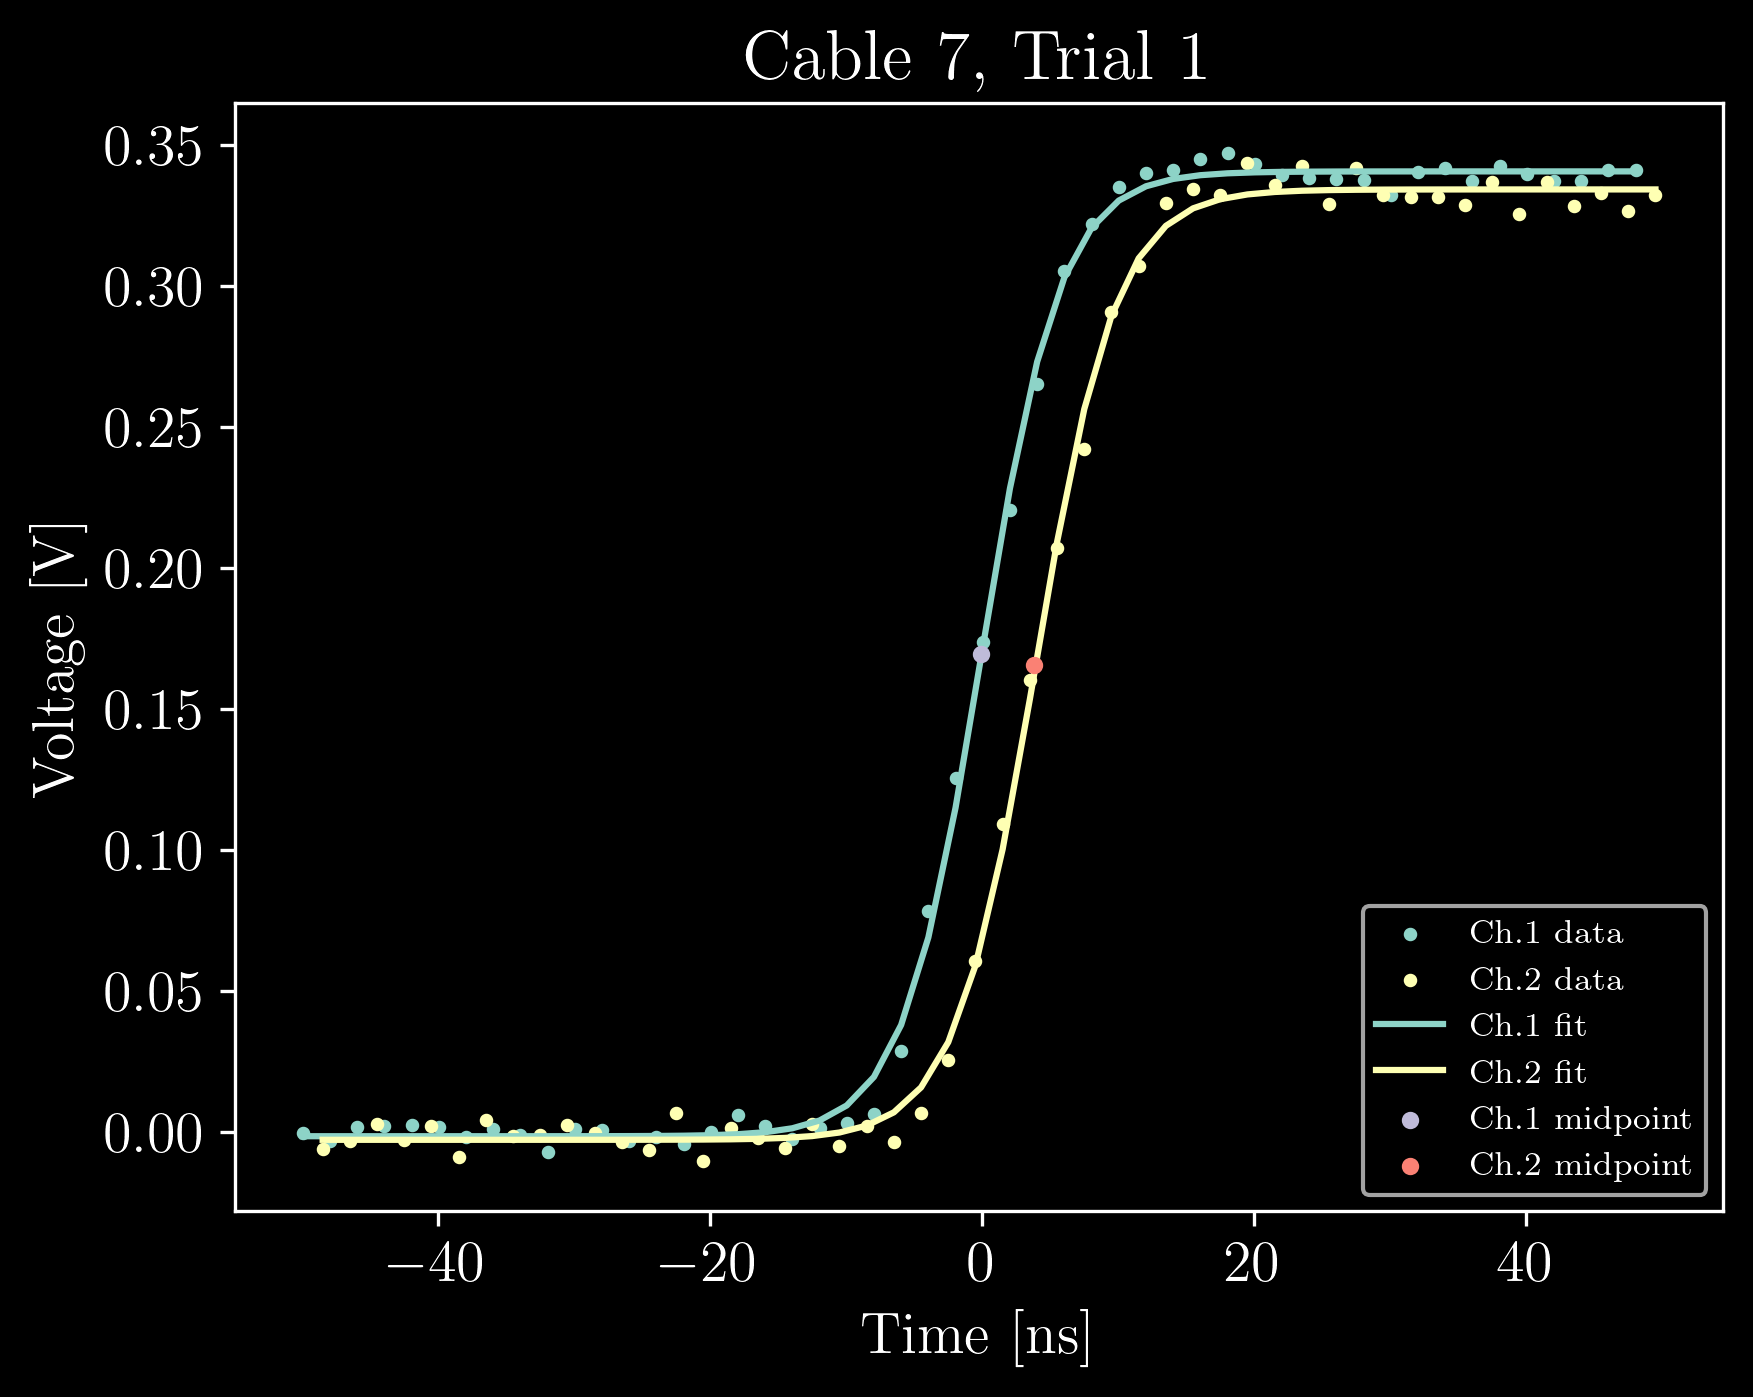

In [204]:
tdelay_Cable7_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable7_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.84612590923300*10, 
               title='Cable 7, Trial 1')

#### Trial 2

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.96602488908231E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 4.036565742271936 ns


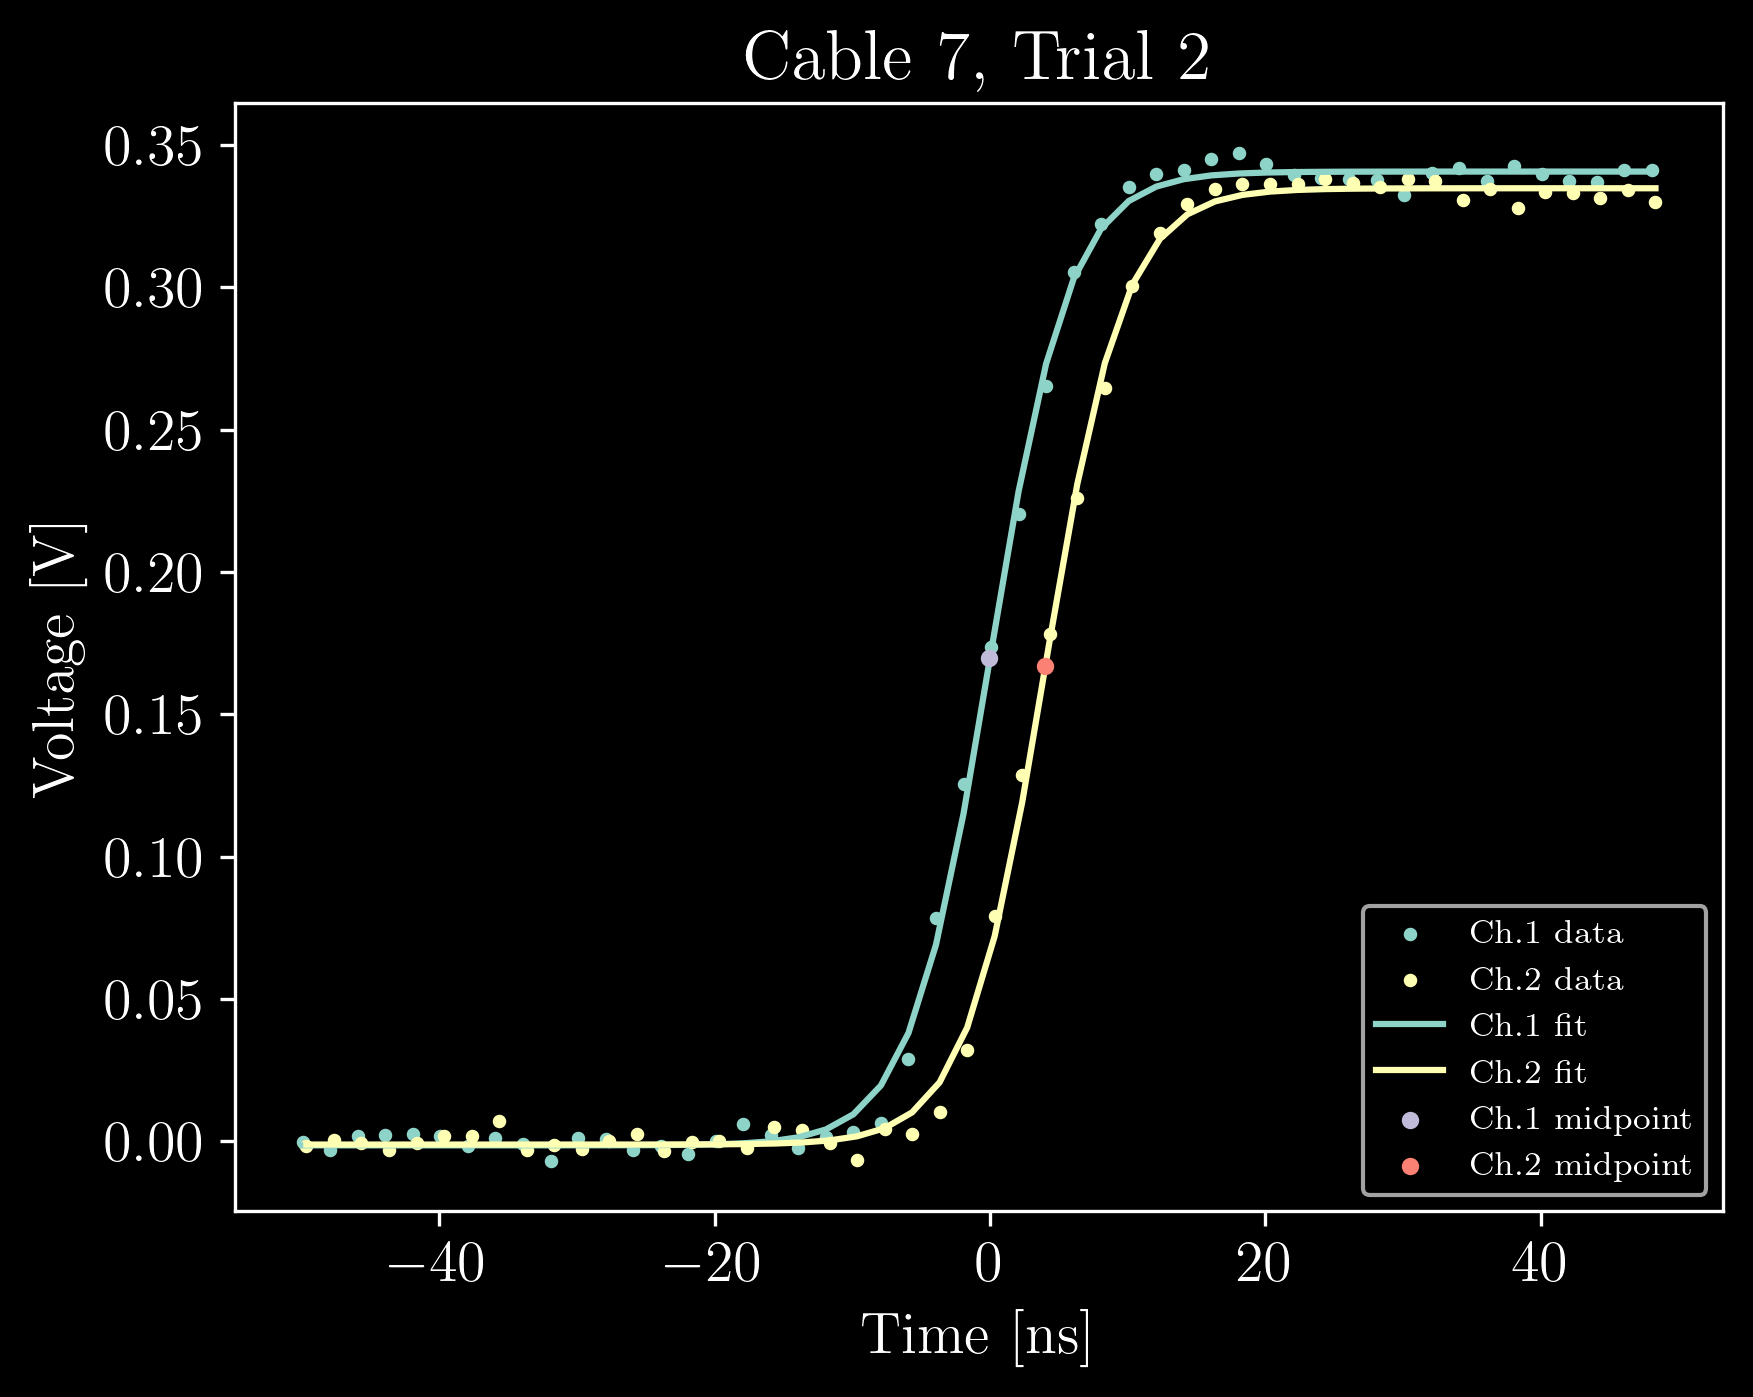

In [205]:
tdelay_Cable7_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable7_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.96602488908231*10, 
               title='Cable 7, Trial 2')

#### Trial 3

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.97624078631479E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 3.7067327262511864 ns


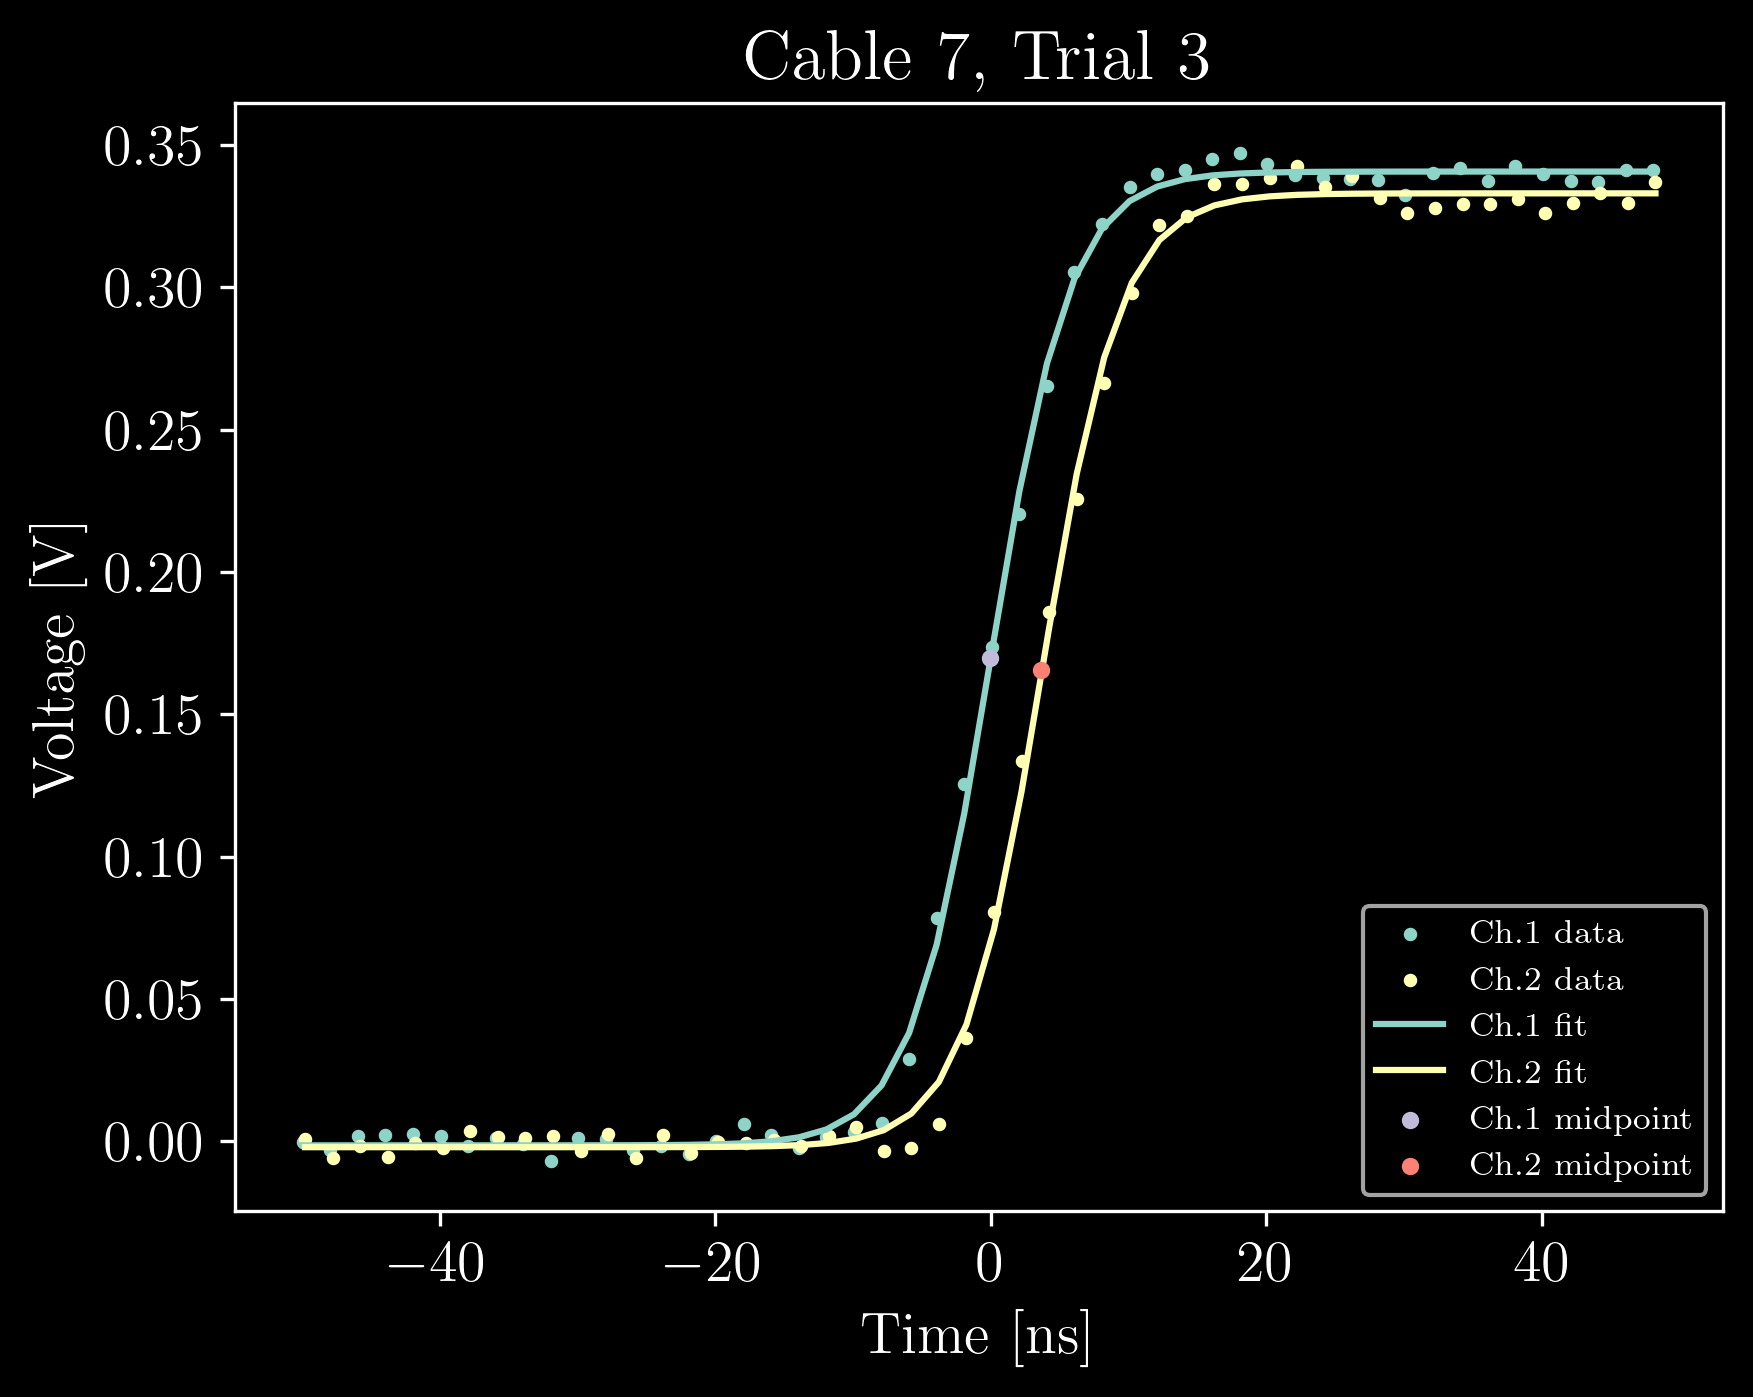

In [207]:
tdelay_Cable7_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable7_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.97624078631479*10, 
               title='Cable 7, Trial 3')

#### Average

In [208]:
tdelay_Cable7_avg = (tdelay_Cable7_1+tdelay_Cable7_2+tdelay_Cable7_3)/3
print('Average time delay = ' + str(tdelay_Cable7_avg) + ' ns')

Average time delay = 3.889430542243518 ns


# Cable 8

Cable type: black, short, medium thickness

#### Trial 1

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.85823170638377E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 4.011270877674752 ns


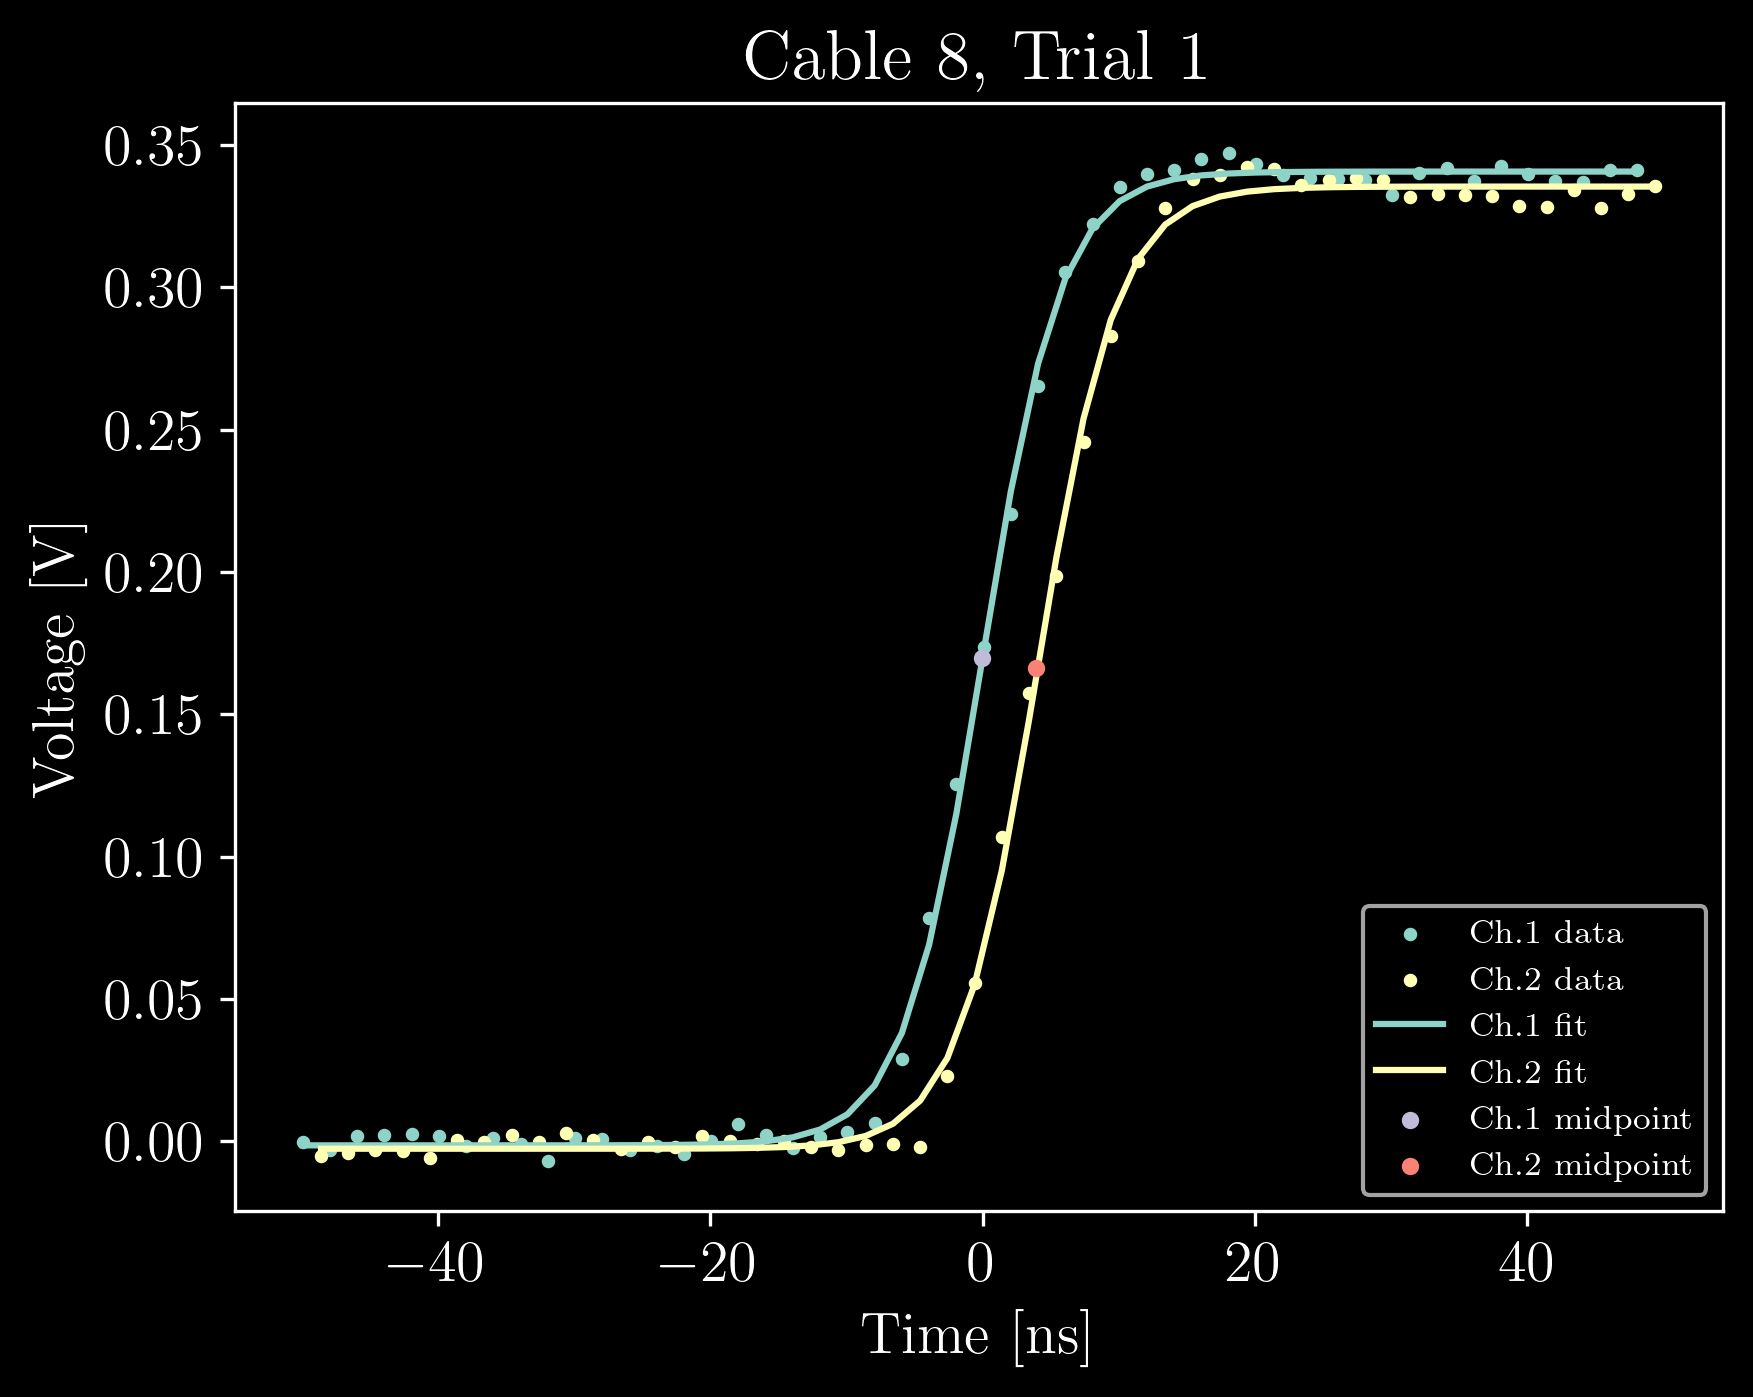

In [209]:
tdelay_Cable8_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable8_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.85823170638377*10, 
               title='Cable 8, Trial 1')

#### Trial 2

In [69]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.85101427062248E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 3.9405495878595707 ns


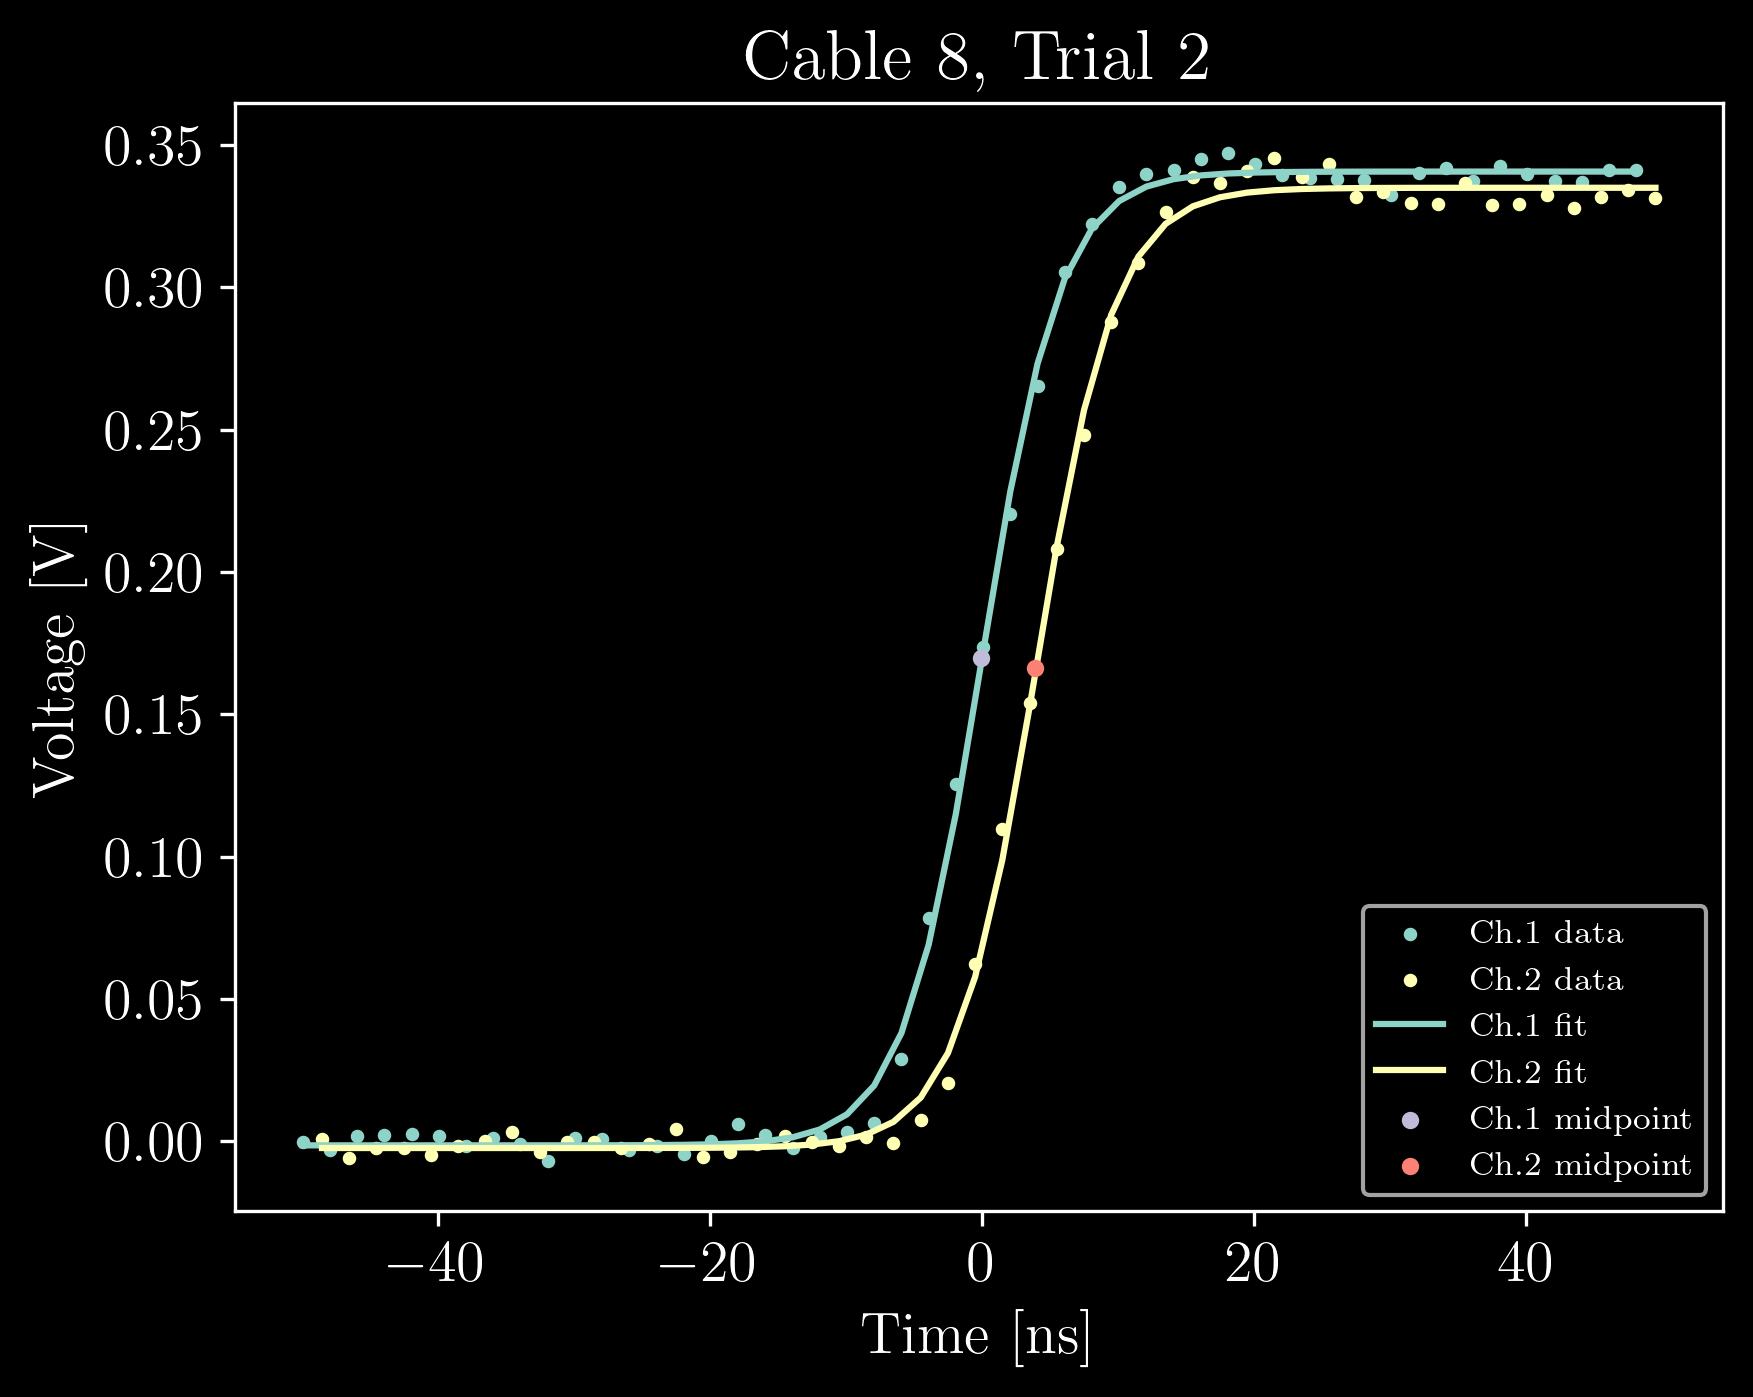

In [210]:
tdelay_Cable8_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable8_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.85101427062248*10, 
               title='Cable 8, Trial 2')

#### Trial 3

In [ ]:
### CH. 1 ###
# -4.99245346027336E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -4.85288033884198E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -5.00000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 4.00013803012851 ns


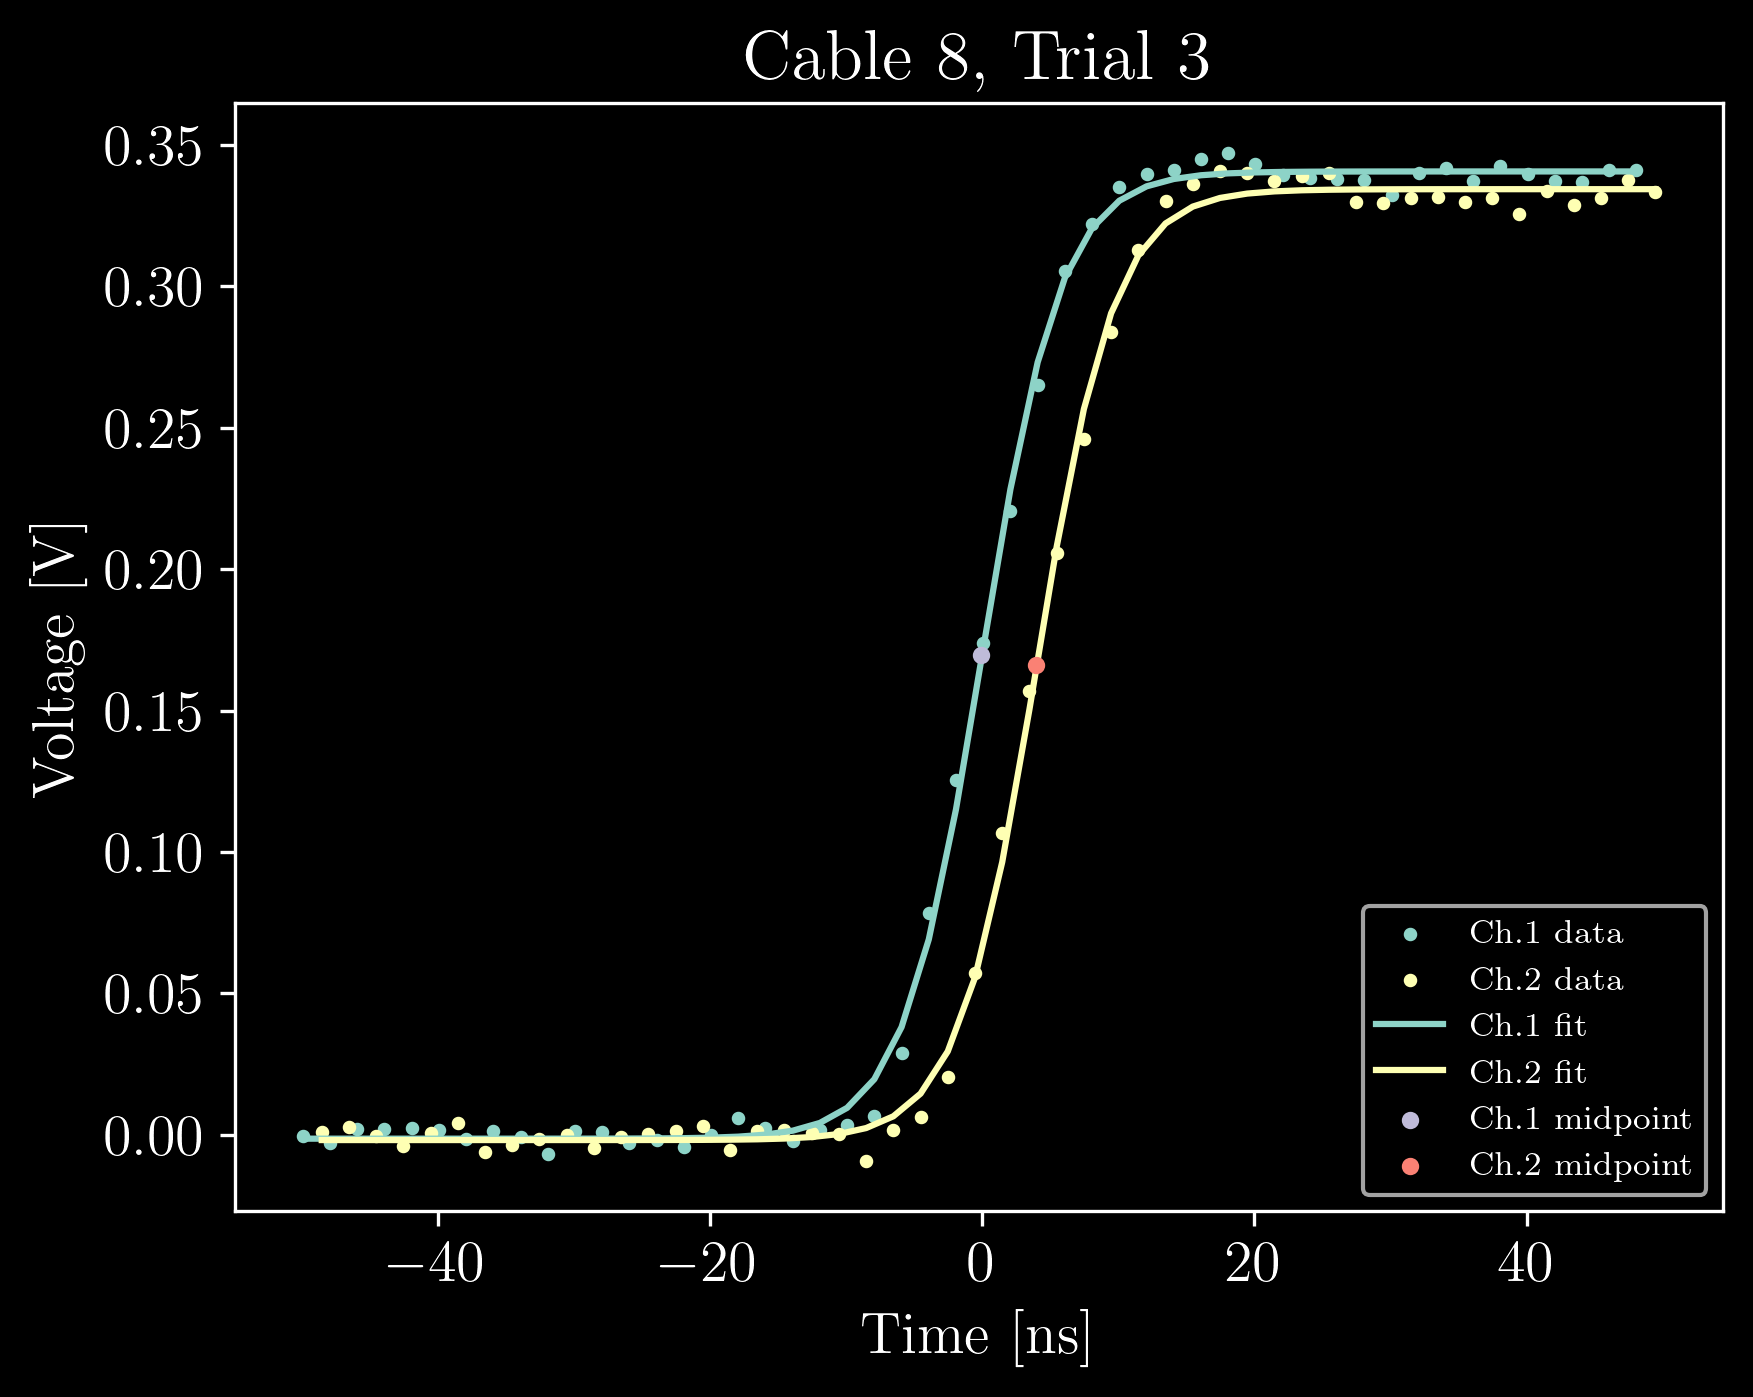

In [211]:
tdelay_Cable8_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables1through8 copy.txt',
               file_CH2='20261111_Ch2_Cable8_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-4.99245346027336*10, xstart_CH2=-4.85288033884198*10, 
               title='Cable 8, Trial 3')

#### Average

In [212]:
tdelay_Cable8_avg = (tdelay_Cable8_1+tdelay_Cable8_2+tdelay_Cable8_3)/3
print('Average time delay = ' + str(tdelay_Cable8_avg) + ' ns')

Average time delay = 3.9839861652209443 ns


# Cable 9

Cable type: black, long, thick

#### Trial 1

In [ ]:
### CH. 1 ###
# -1.18174696871382E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.30000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -1.26965040003773E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.30000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 69.1201070478783 ns


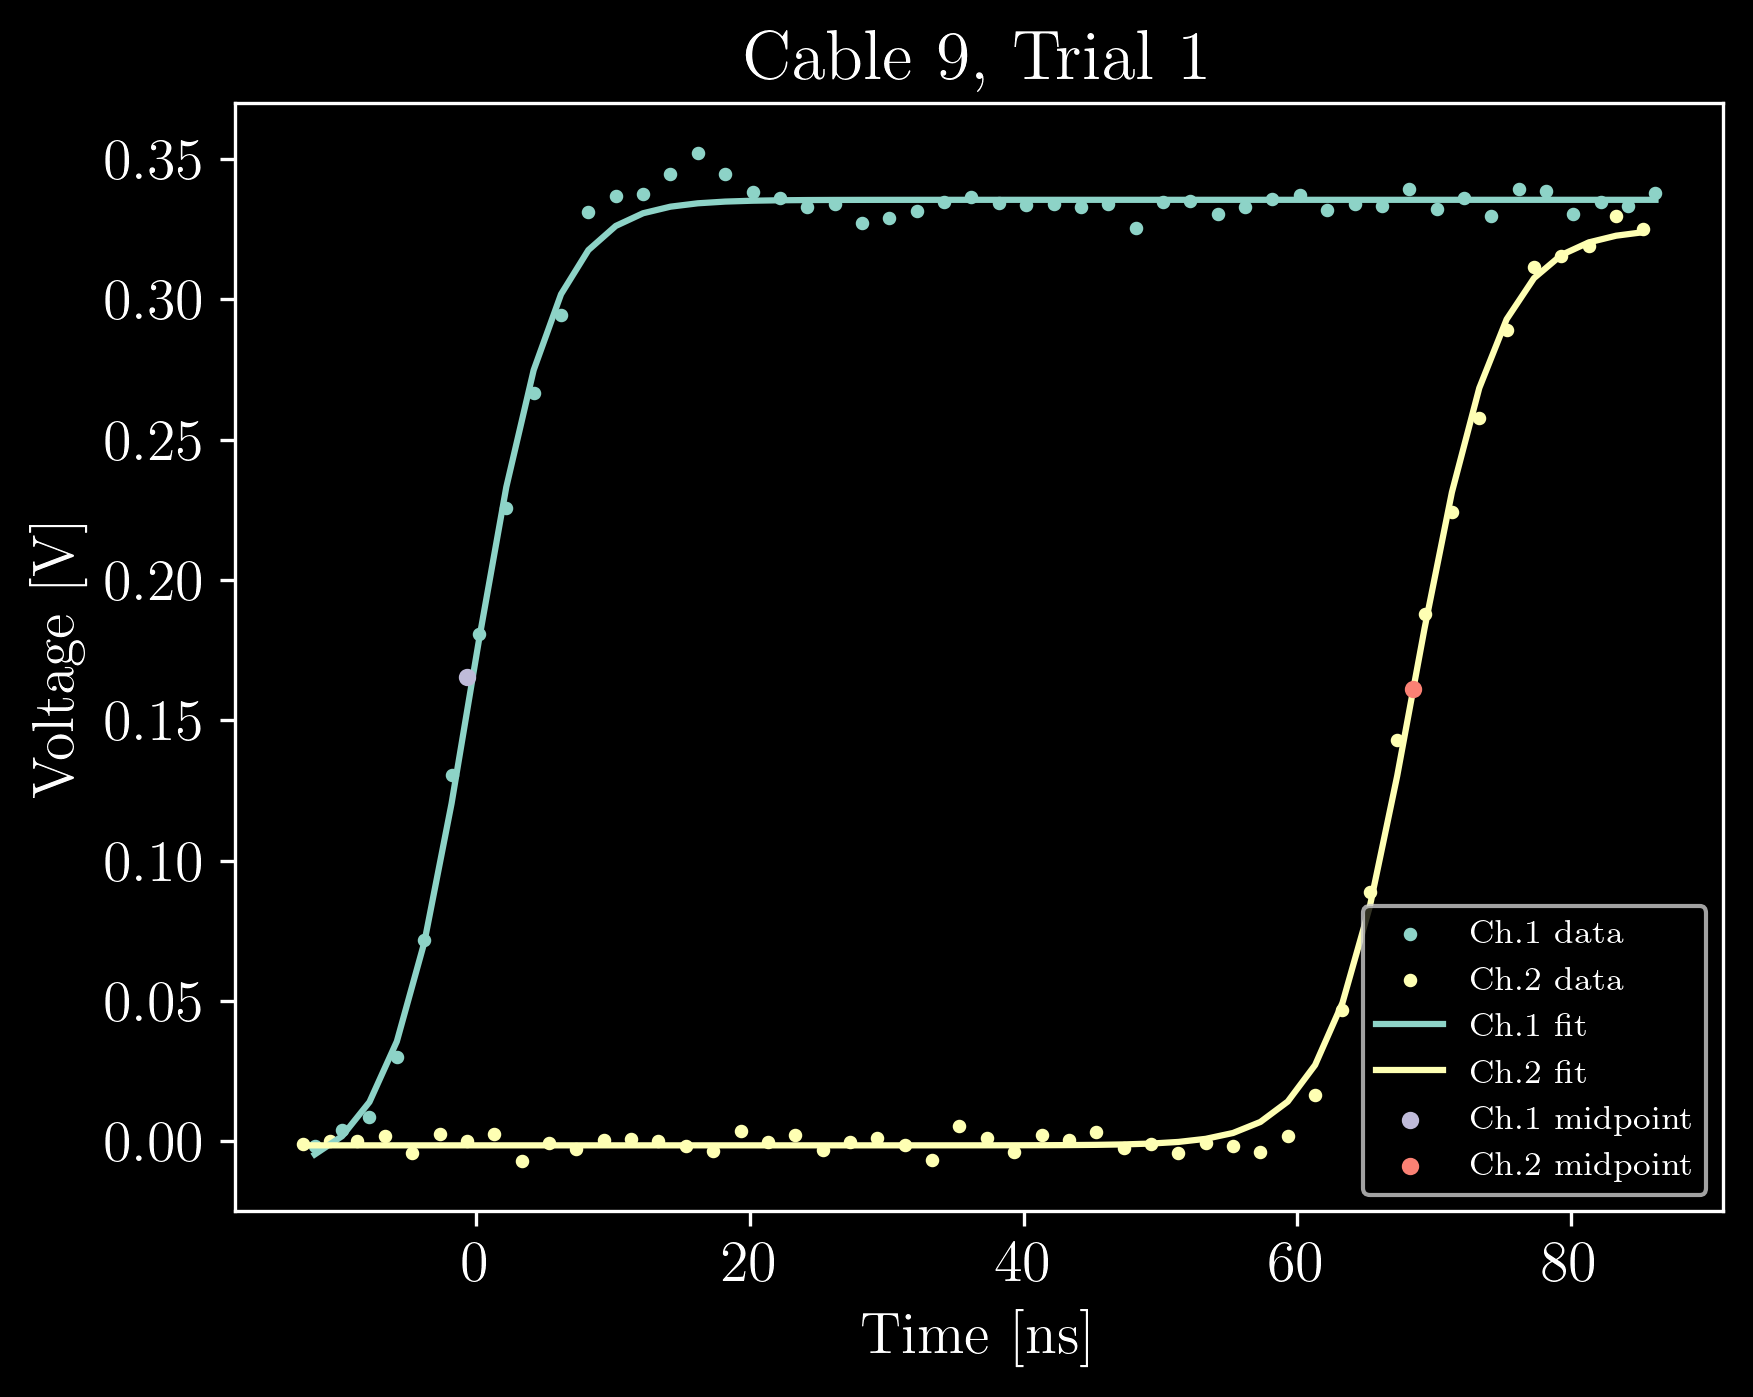

In [213]:
tdelay_Cable9_1 = analyze(file_CH1='20261111_Ch1_Reference_Cable9 copy.txt',
               file_CH2='20261111_Ch2_Cable9_withCables5and1_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.18174696871382*10, xstart_CH2=-1.26965040003773*10, 
               title='Cable 9, Trial 1')

#### Trial 2

In [49]:
### CH. 1 ###
# -1.18174696871382E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.30000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -1.19551725359221E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.30000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 69.15102380441898 ns


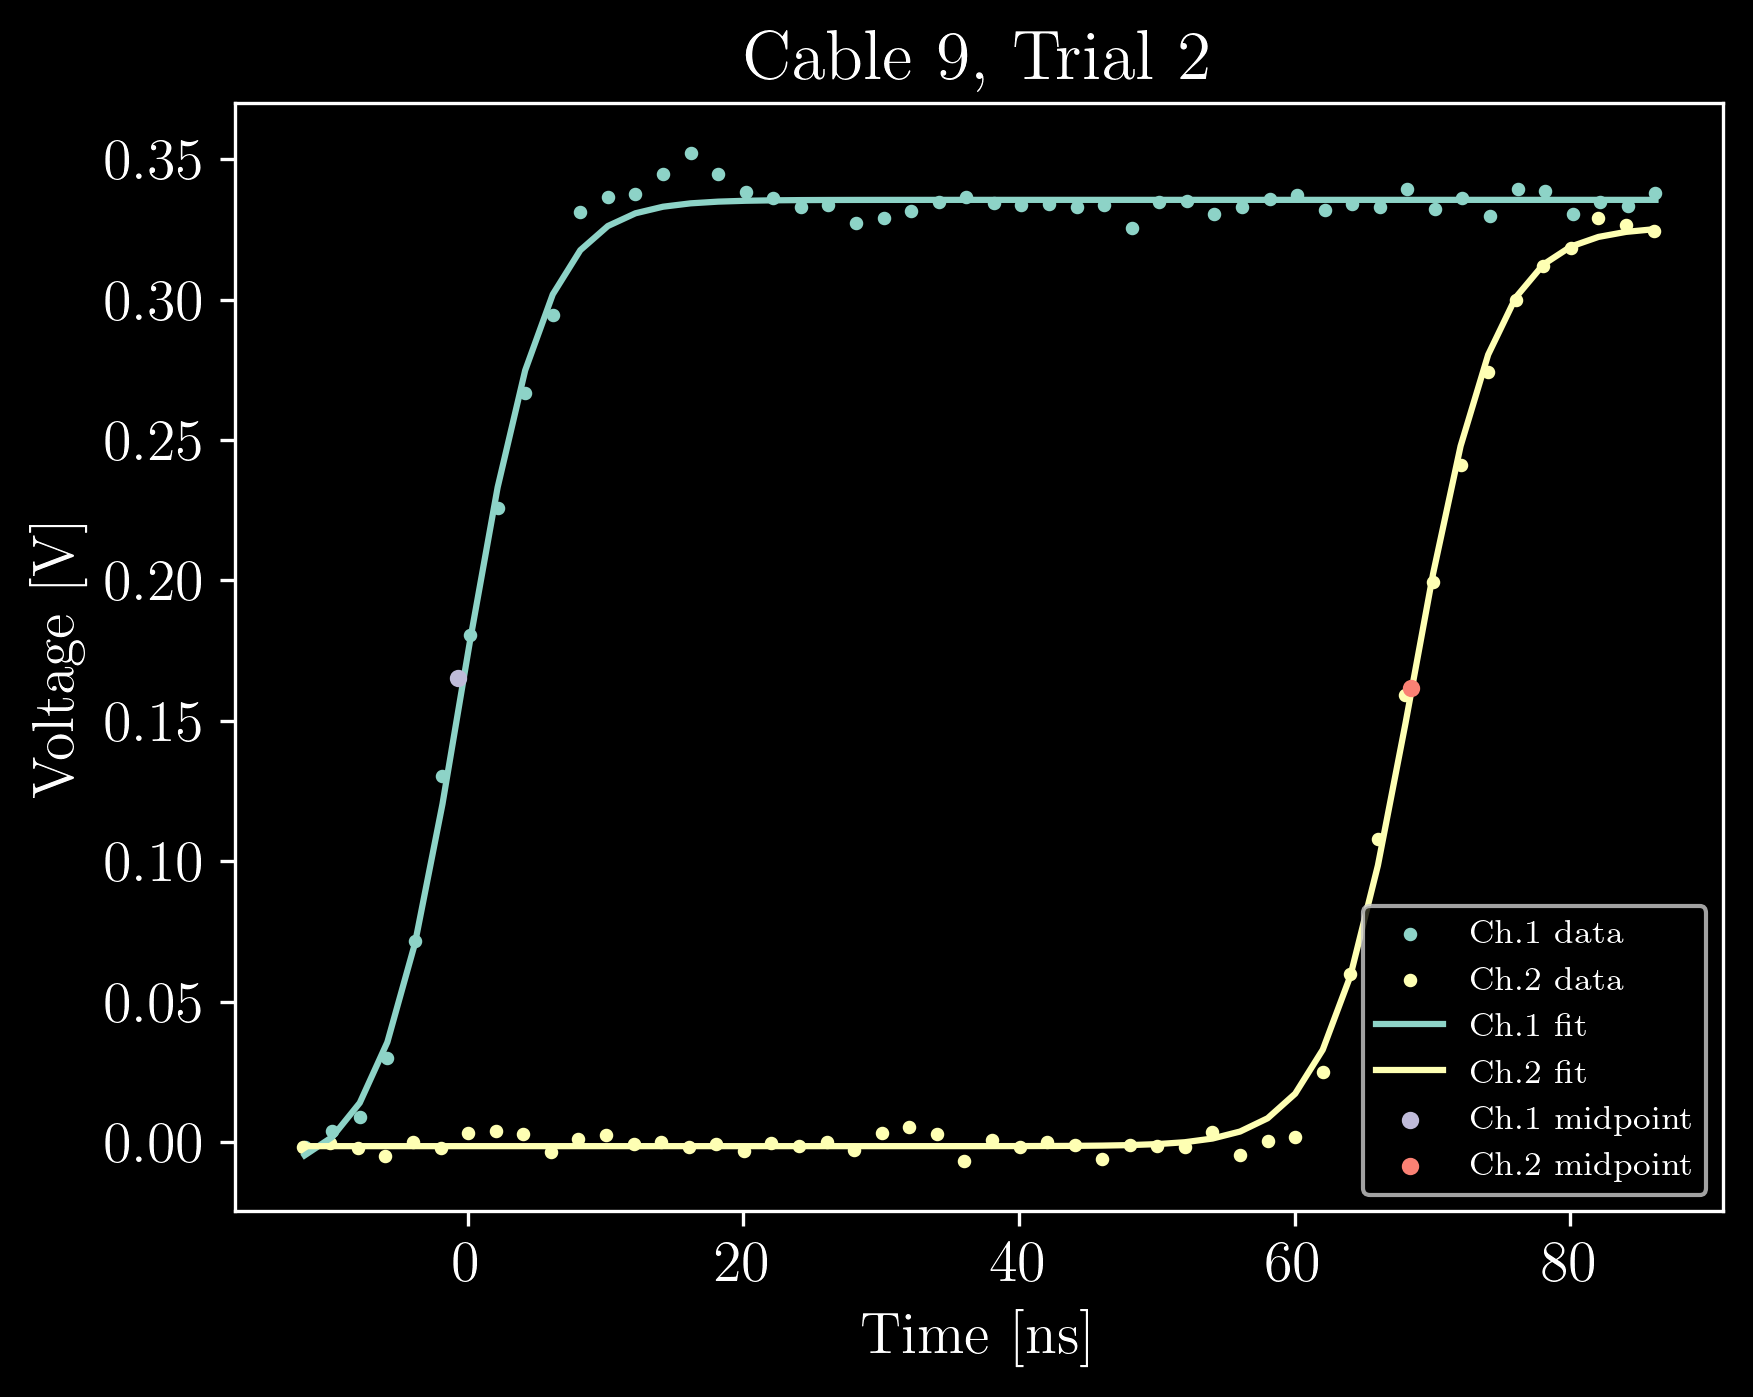

In [214]:
tdelay_Cable9_2 = analyze(file_CH1='20261111_Ch1_Reference_Cable9 copy.txt',
               file_CH2='20261111_Ch2_Cable9_withCables5and1_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.18174696871382*10, xstart_CH2=-1.19551725359221*10, 
               title='Cable 9, Trial 2')

#### Trial 3

In [ ]:
### CH. 1 ###
# -1.18174696871382E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.68300000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.30000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

### CH. 2 ###
# -1.25382315127373E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  1.65630000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.30000000000000E-0008        (X-Value of left side of the screen)
#  1.00000000000000E-0008        (X-Value/div)
#  5.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 69.23419411571071 ns


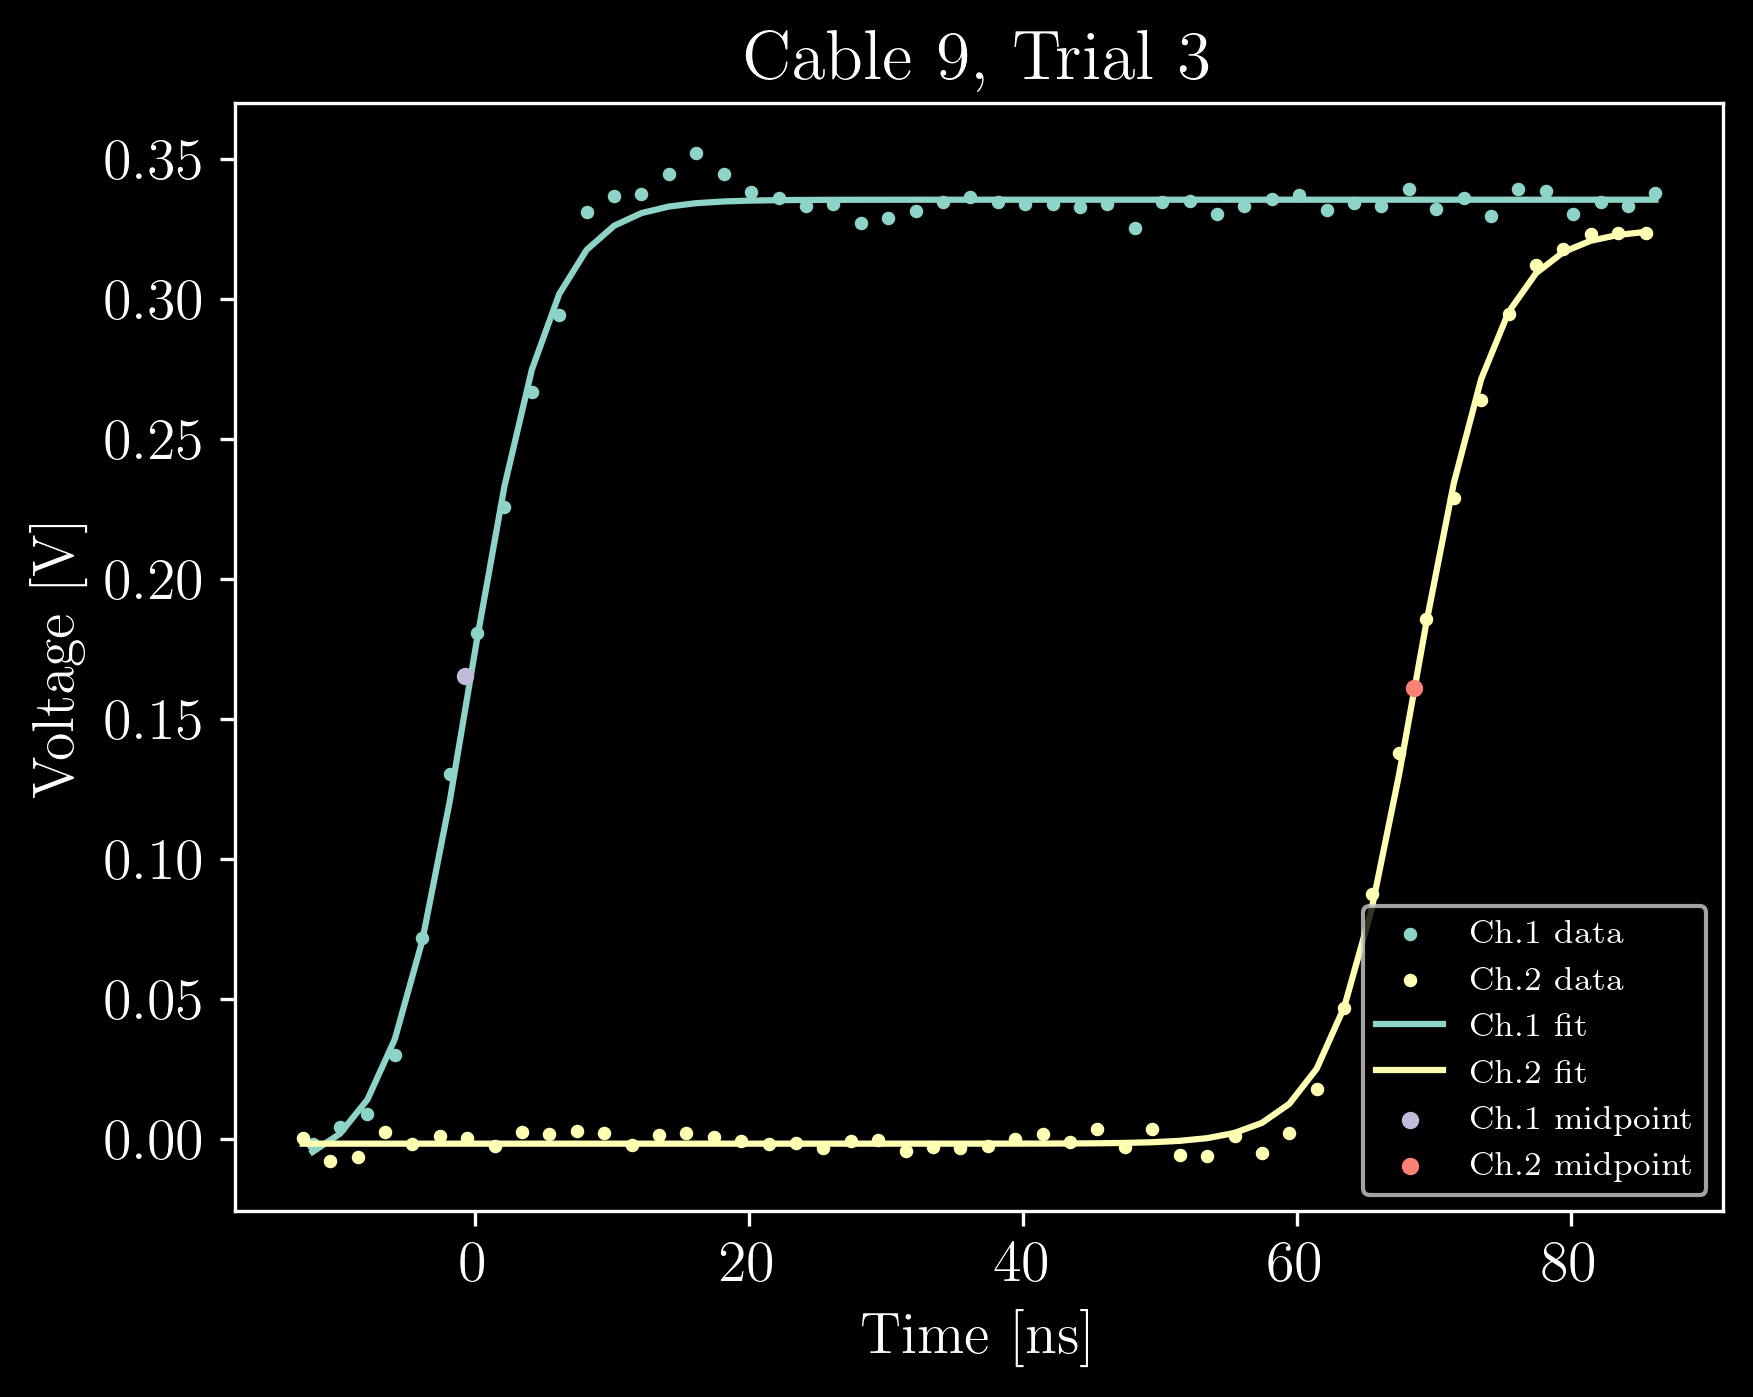

In [215]:
tdelay_Cable9_3 = analyze(file_CH1='20261111_Ch1_Reference_Cable9 copy.txt',
               file_CH2='20261111_Ch2_Cable9_withCables5and1_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.18174696871382*10, xstart_CH2=-1.25382315127373*10, 
               title='Cable 9, Trial 3')

#### Average

In [216]:
tdelay_Cable9_avg = (tdelay_Cable9_1+tdelay_Cable9_2+tdelay_Cable9_3)/3
print('Average time delay = ' + str(tdelay_Cable9_avg) + ' ns')

Average time delay = 69.16844165600266 ns


# Cable 10

Cable type: black, long, thick

#### Trial 1

In [76]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    100        (Record Length)
# Waveform


# -9.00012635498481E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -9.20000000000000E-0008        (X-Value of left side of the screen)
#  2.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    100        (Record Length)
# Waveform


# -9.09997420369729E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -9.20000000000000E-0008        (X-Value of left side of the screen)
#  2.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 67.87644169127891 ns


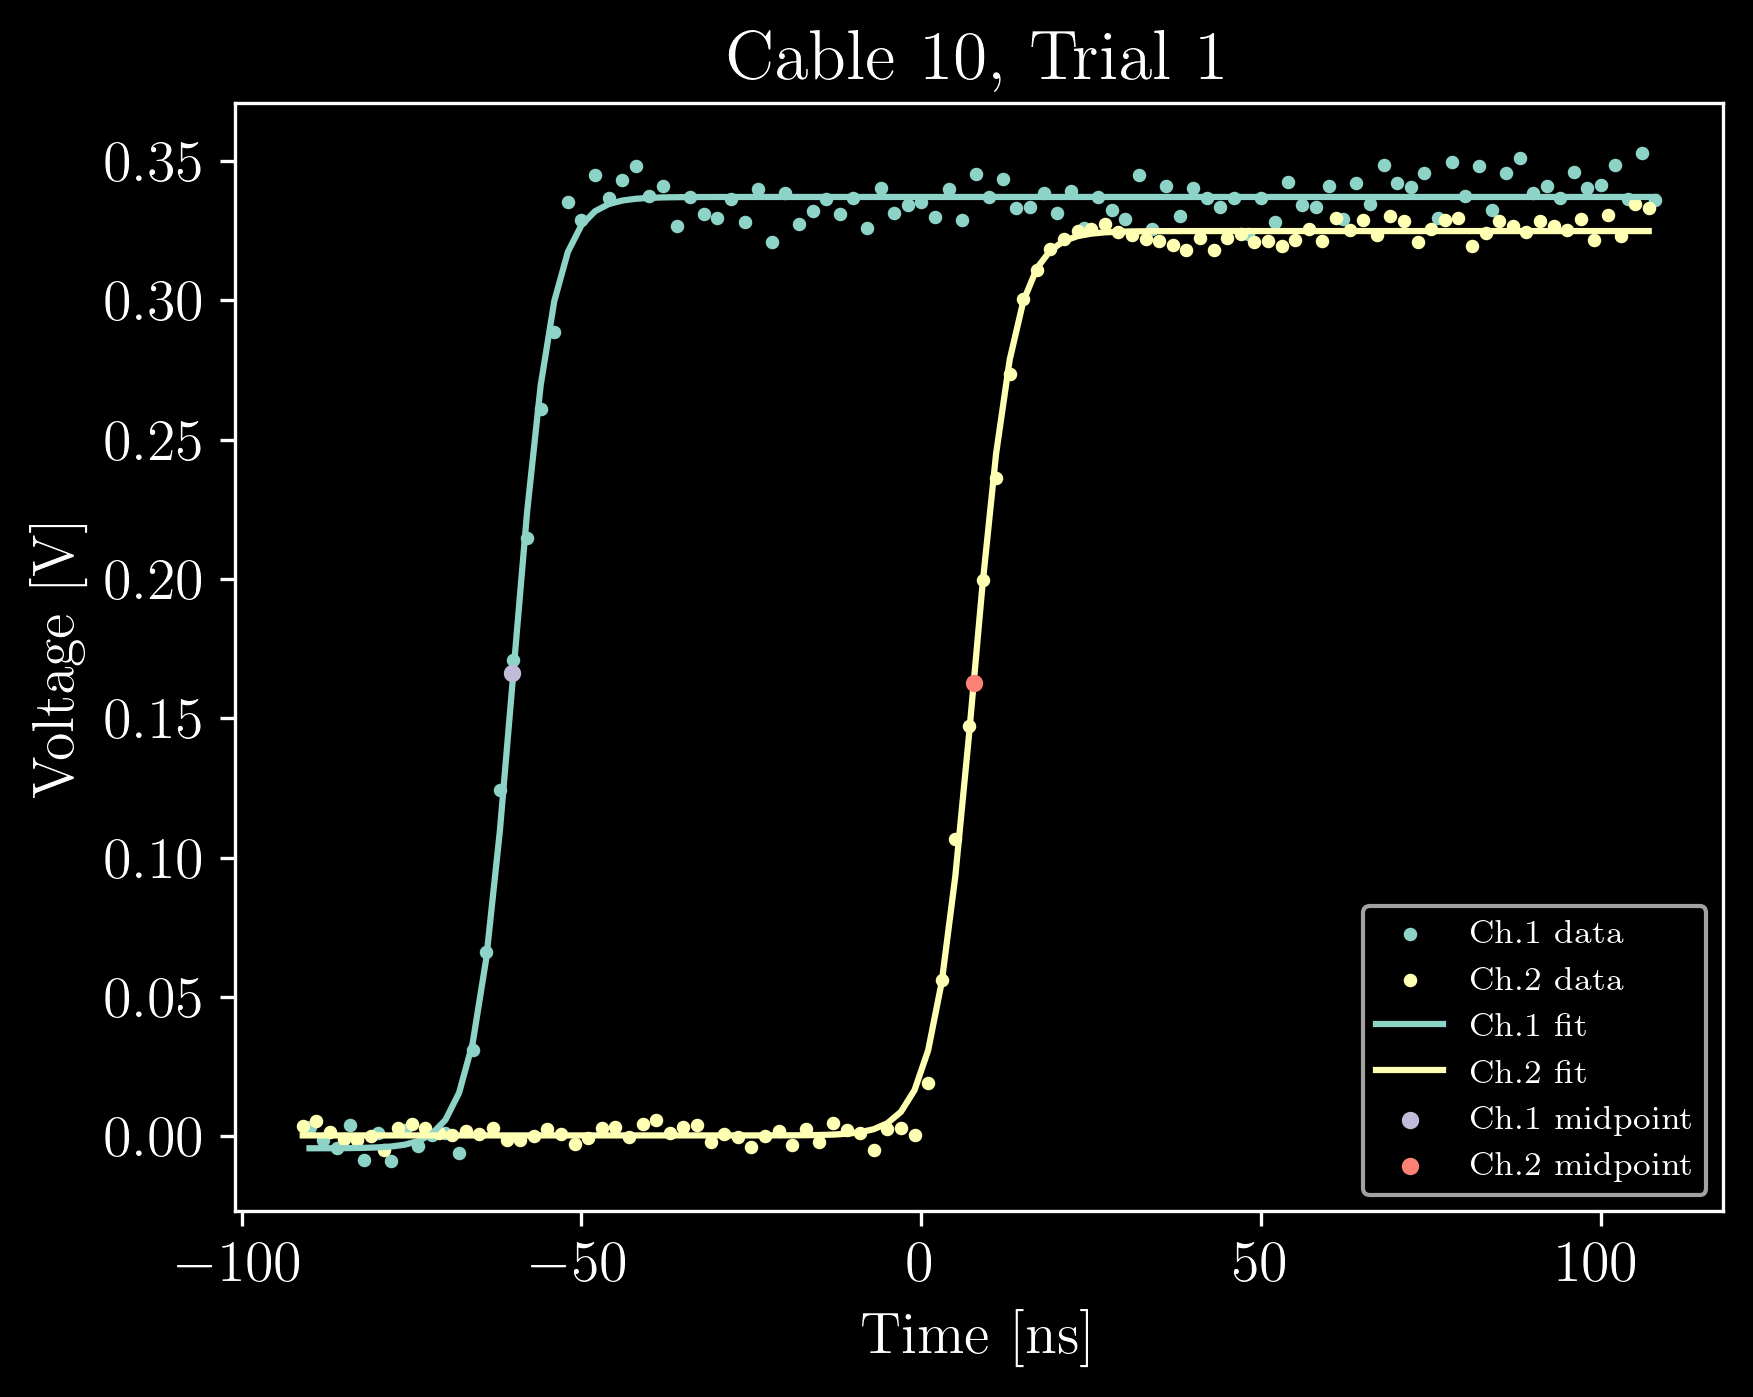

In [217]:
tdelay_Cable10_1 = analyze(file_CH1='20261111_Ch1_Reference_Cable10 copy.txt',
               file_CH2='20261111_Ch2_Cable10_withCables5and1_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-9.00012635498481*10, xstart_CH2=-9.09997420369729*10, 
               title='Cable 10, Trial 1', num=100)

#### Trial 2

In [ ]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    100        (Record Length)
# Waveform


# -9.00012635498481E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -9.20000000000000E-0008        (X-Value of left side of the screen)
#  2.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    100        (Record Length)
# Waveform


# -9.08066465057297E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -9.20000000000000E-0008        (X-Value of left side of the screen)
#  2.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 67.76366212036369 ns


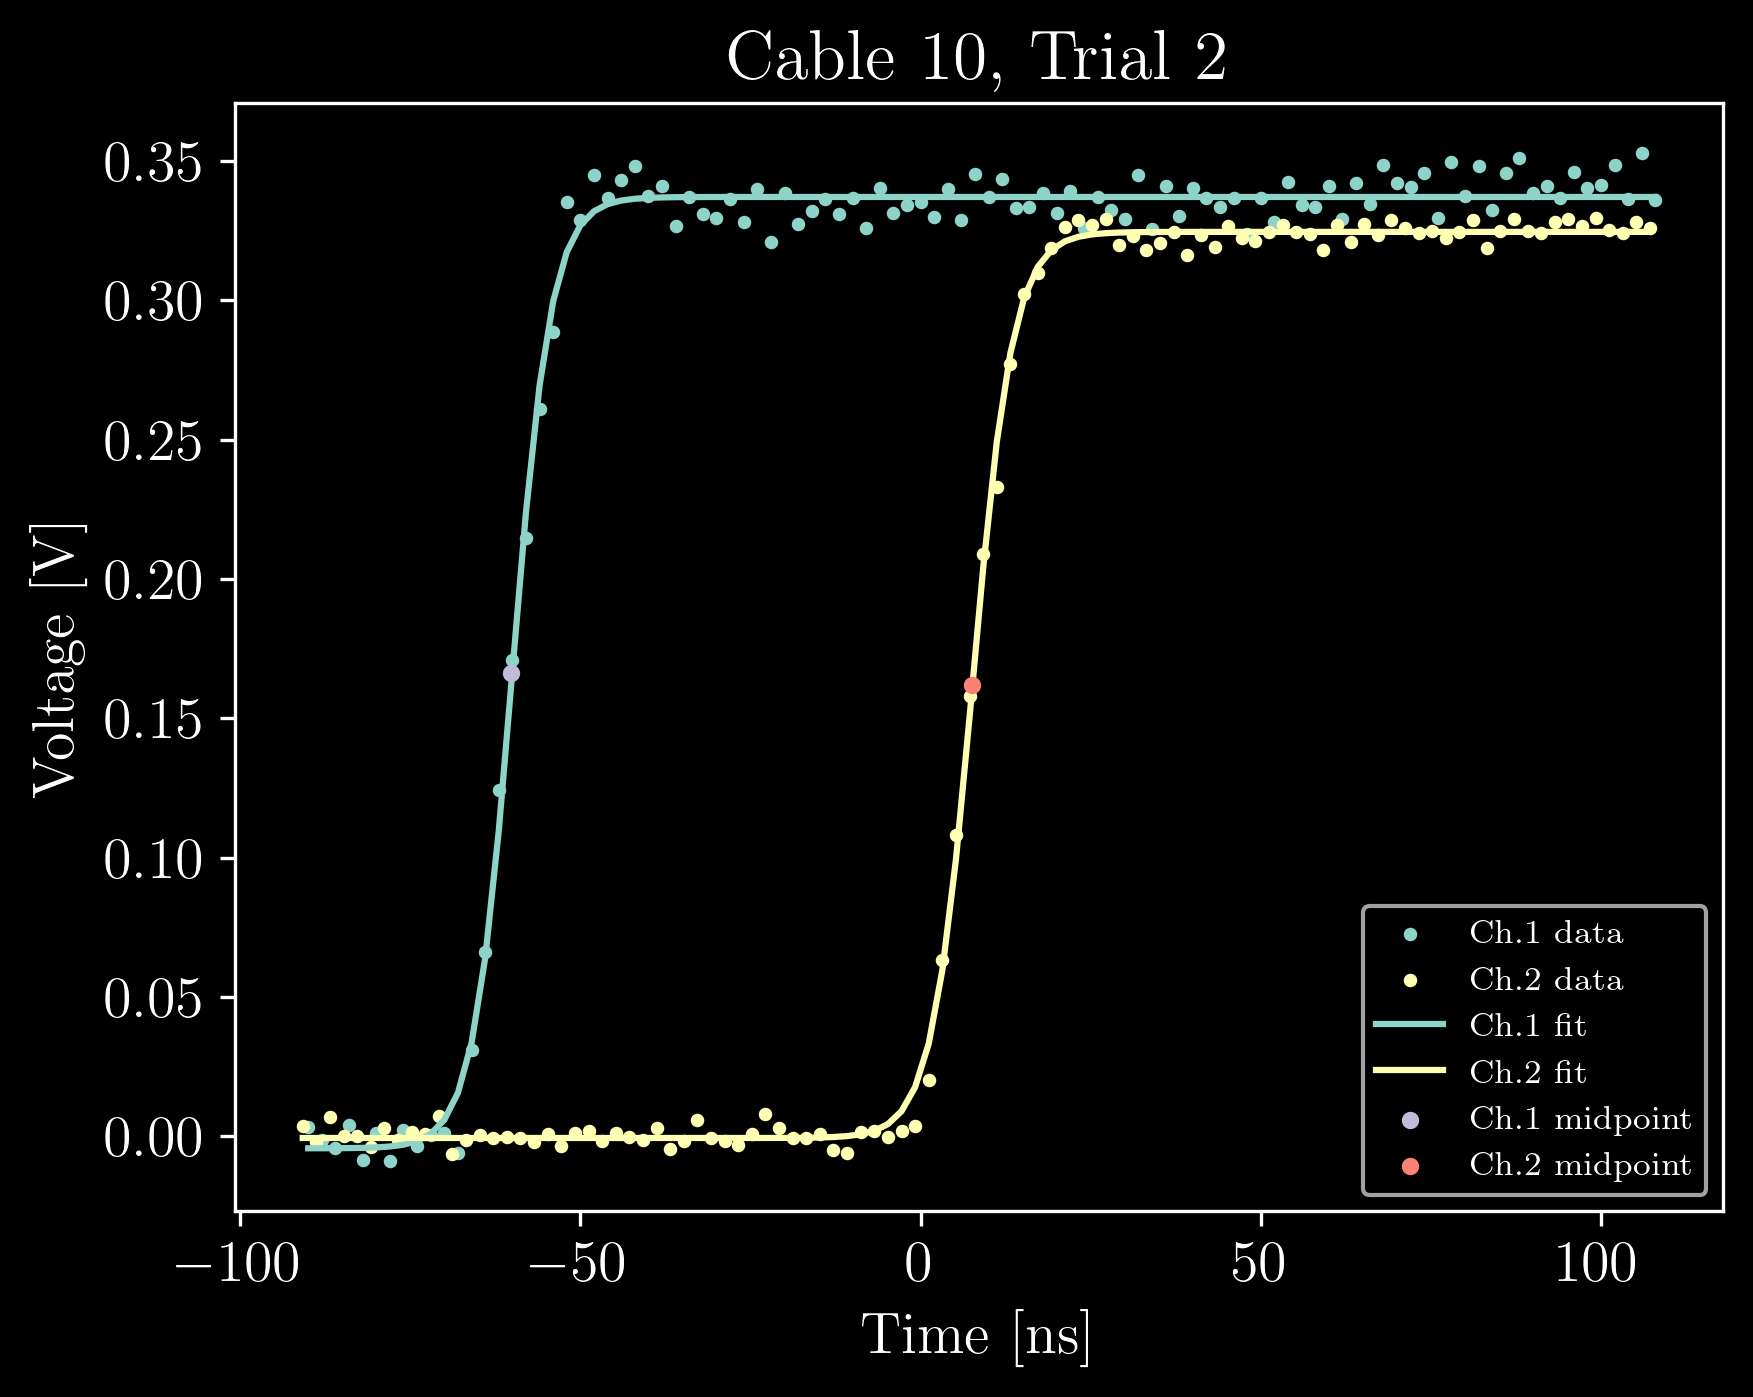

In [218]:
tdelay_Cable10_2 = analyze(file_CH1='20261111_Ch1_Reference_Cable10 copy.txt',
               file_CH2='20261111_Ch2_Cable10_withCables5and1_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-9.00012635498481*10, xstart_CH2=-9.08066465057297*10, 
               title='Cable 10, Trial 2', num=100)

#### Trial 3

In [ ]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    100        (Record Length)
# Waveform


# -9.00012635498481E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -9.20000000000000E-0008        (X-Value of left side of the screen)
#  2.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    100        (Record Length)
# Waveform


# -9.07971502055220E-0008        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -9.20000000000000E-0008        (X-Value of left side of the screen)
#  2.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 67.81189262905572 ns


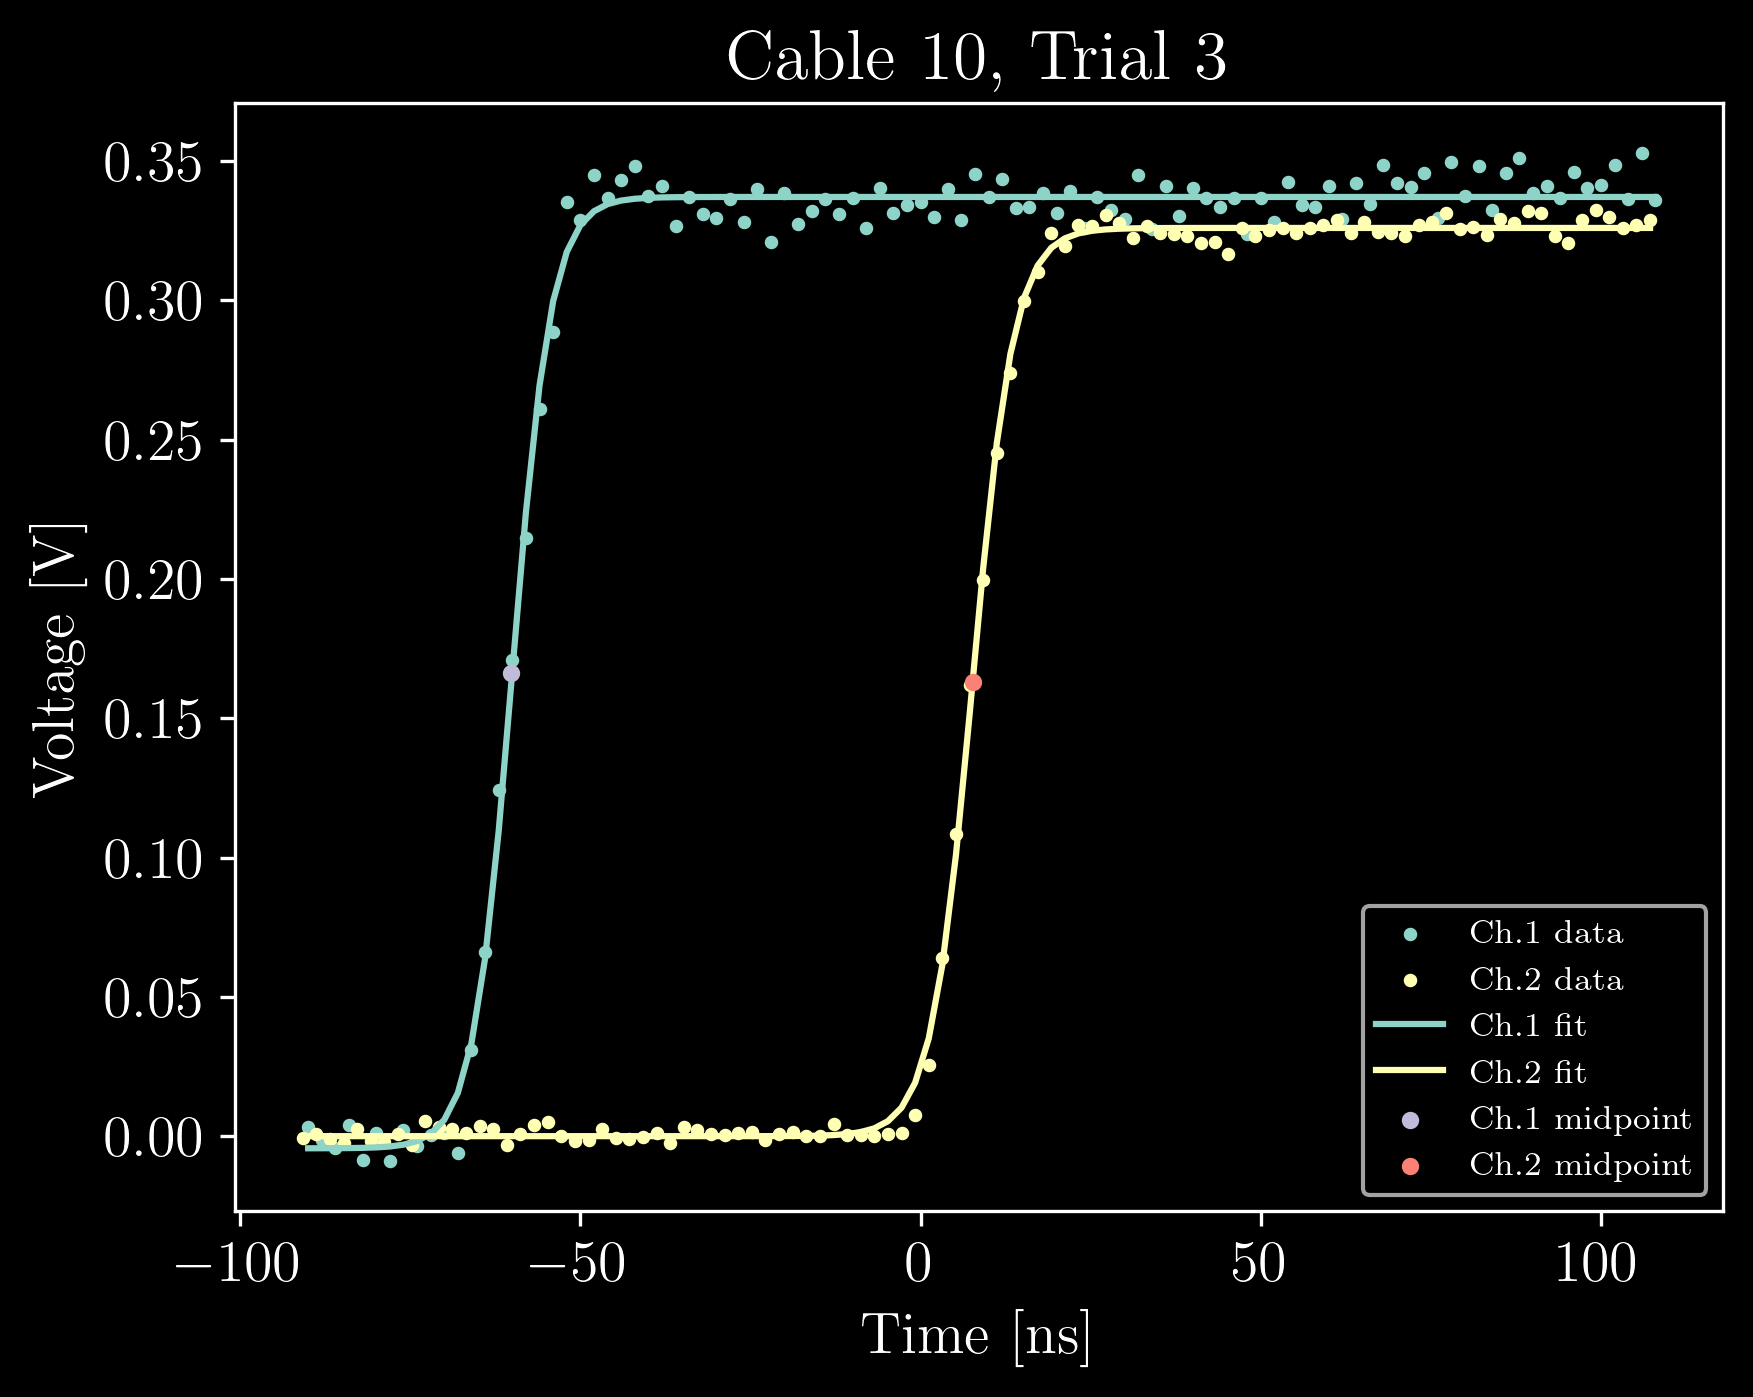

In [219]:
tdelay_Cable10_3 = analyze(file_CH1='20261111_Ch1_Reference_Cable10 copy.txt',
               file_CH2='20261111_Ch2_Cable10_withCables5and1_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-9.00012635498481*10, xstart_CH2=-9.07971502055220*10, 
               title='Cable 10, Trial 3', num=100)

#### Average

In [220]:
tdelay_Cable10_avg = (tdelay_Cable10_1+tdelay_Cable10_2+tdelay_Cable10_3)/3
print('Average time delay = ' + str(tdelay_Cable10_avg) + ' ns')

Average time delay = 67.81733214689945 ns


# Cable 11

Cable type: black, long, thick

#### Trial 1

In [85]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78218446144425E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78375903779611E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 67.33257535624087 ns


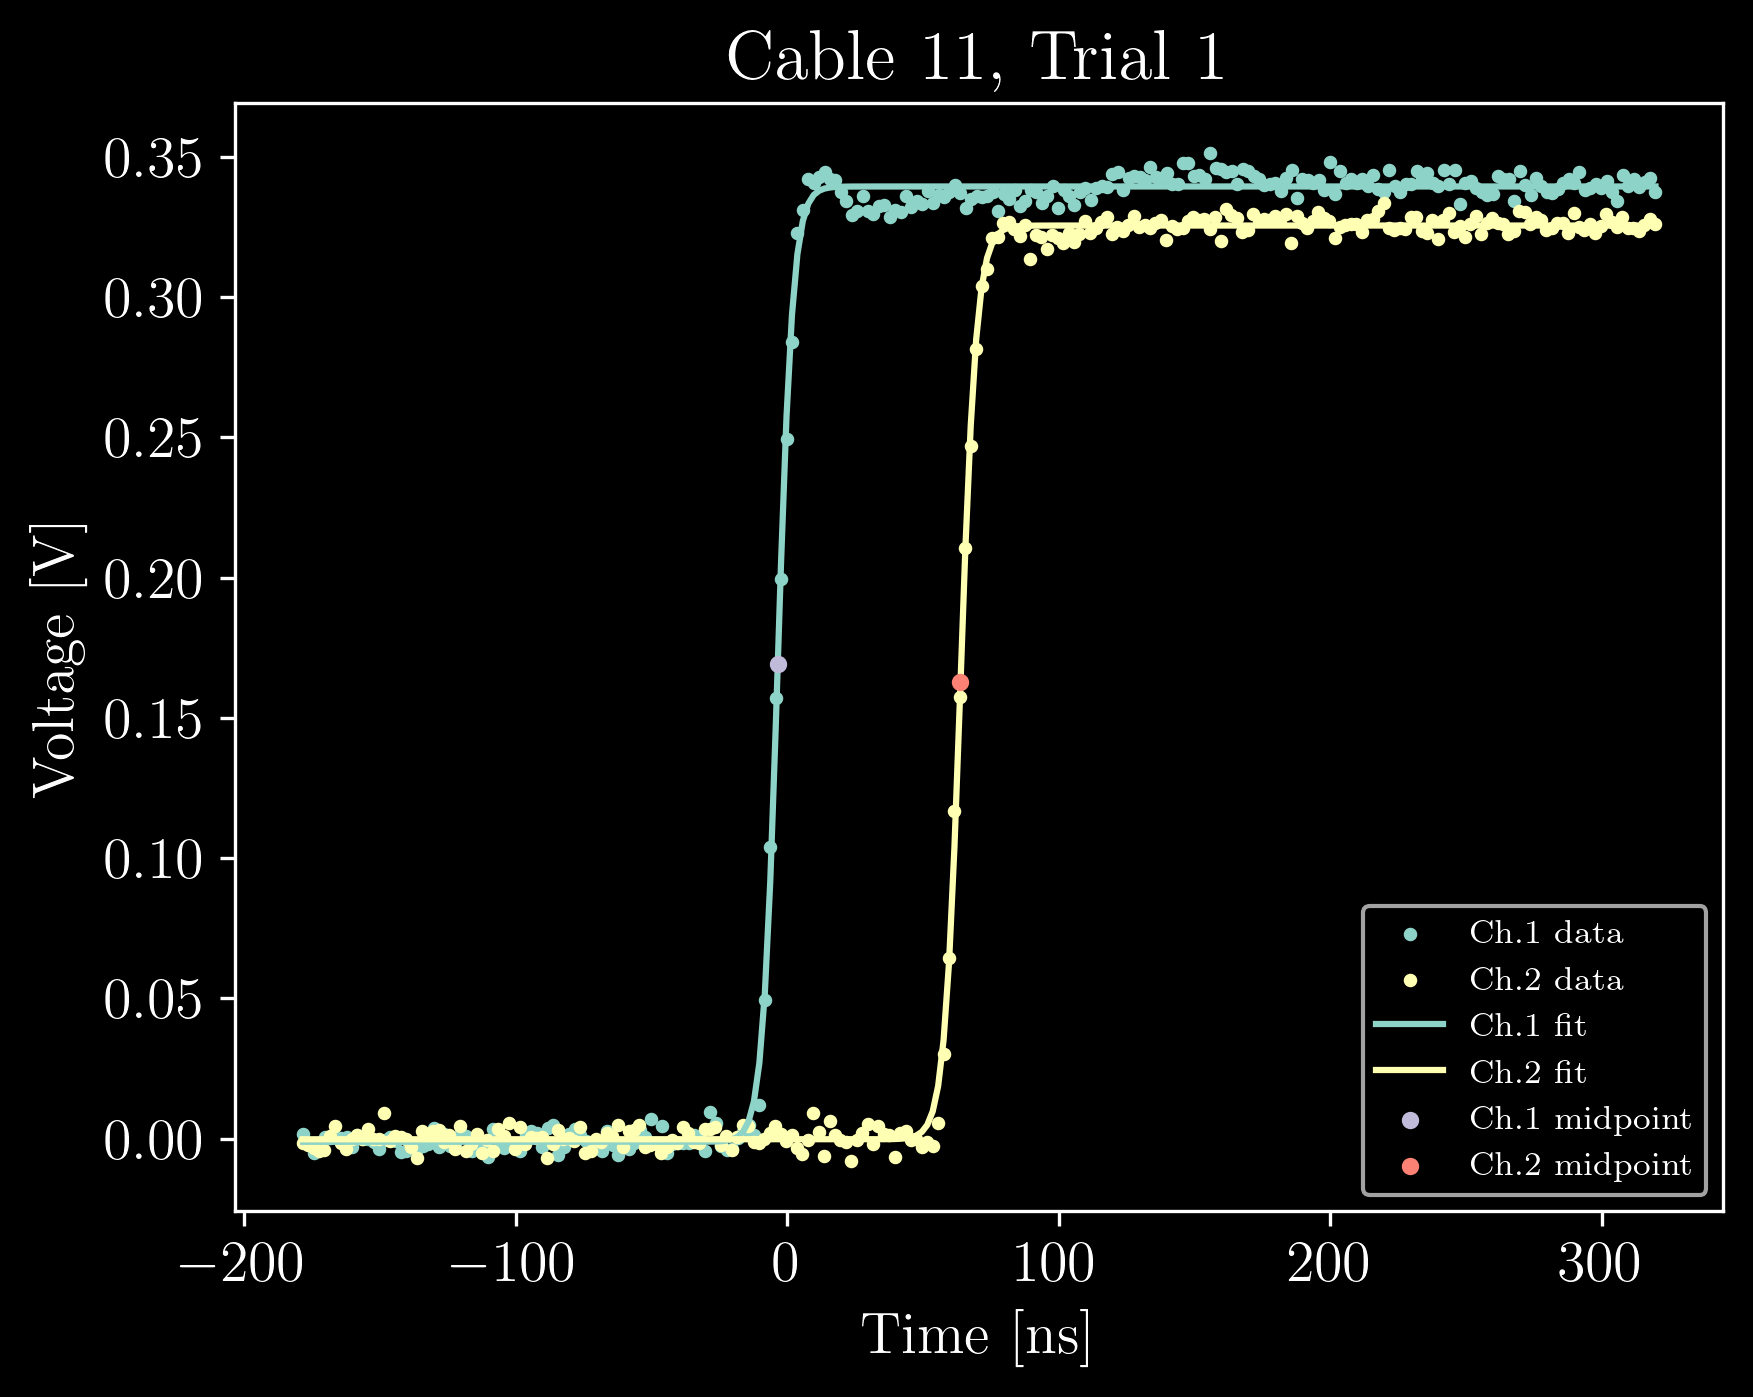

In [221]:
tdelay_Cable11_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables11and12 copy.txt',
               file_CH2='20261111_Ch2_Cable11_withCables5and1_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.78218446144425*100, xstart_CH2=-1.78375903779611*100, 
               title='Cable 11, Trial 1', num=250)

#### Trial 2

In [87]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78218446144425E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78760123917032E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 67.47686765699048 ns


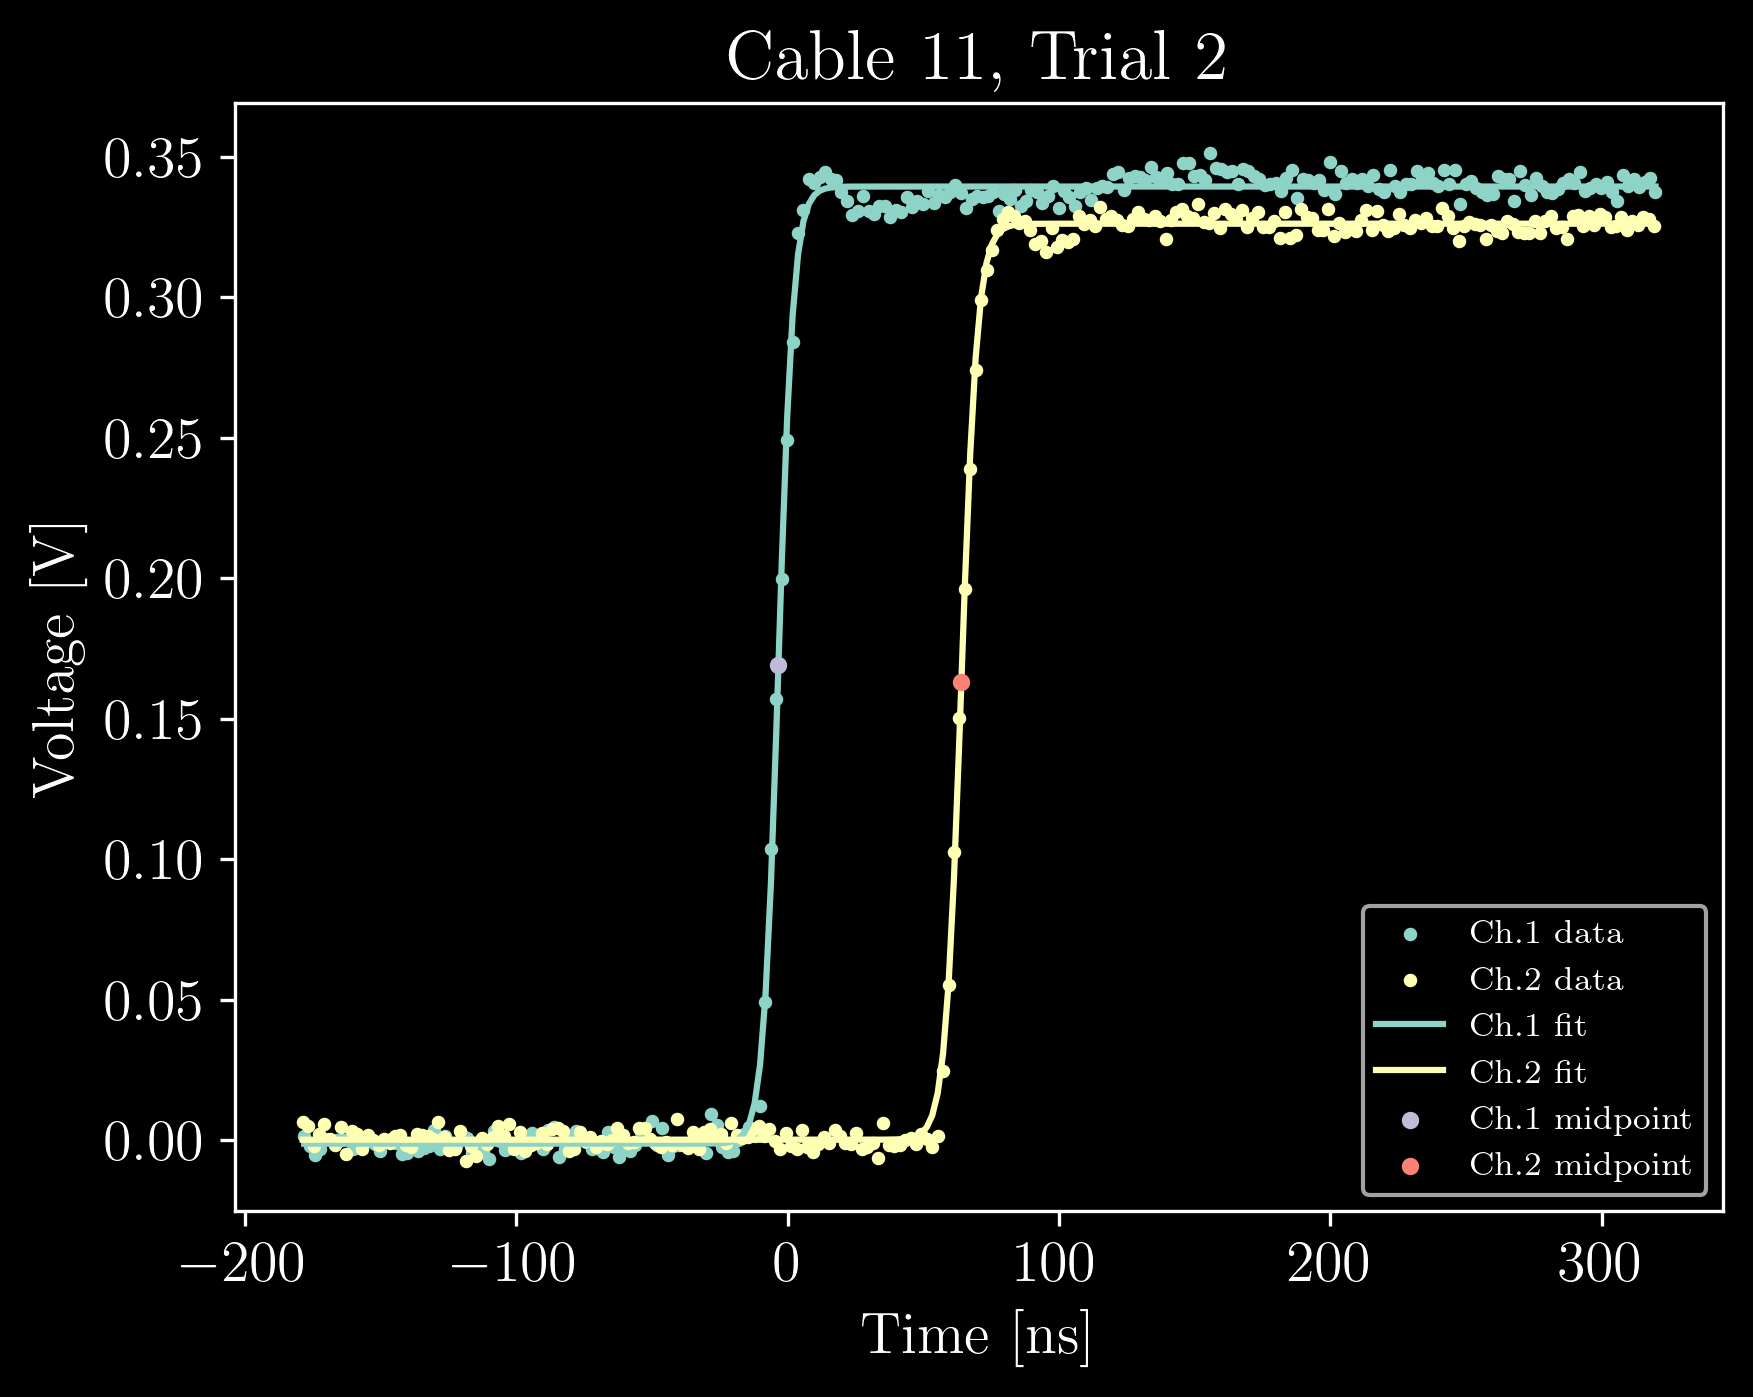

In [222]:
tdelay_Cable11_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables11and12 copy.txt',
               file_CH2='20261111_Ch2_Cable11_withCables5and1_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.78218446144425*100, xstart_CH2=-1.78760123917032*100, 
               title='Cable 11, Trial 2', num=250)

#### Trial 3

In [89]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78218446144425E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78813961249056E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 67.3725736659957 ns


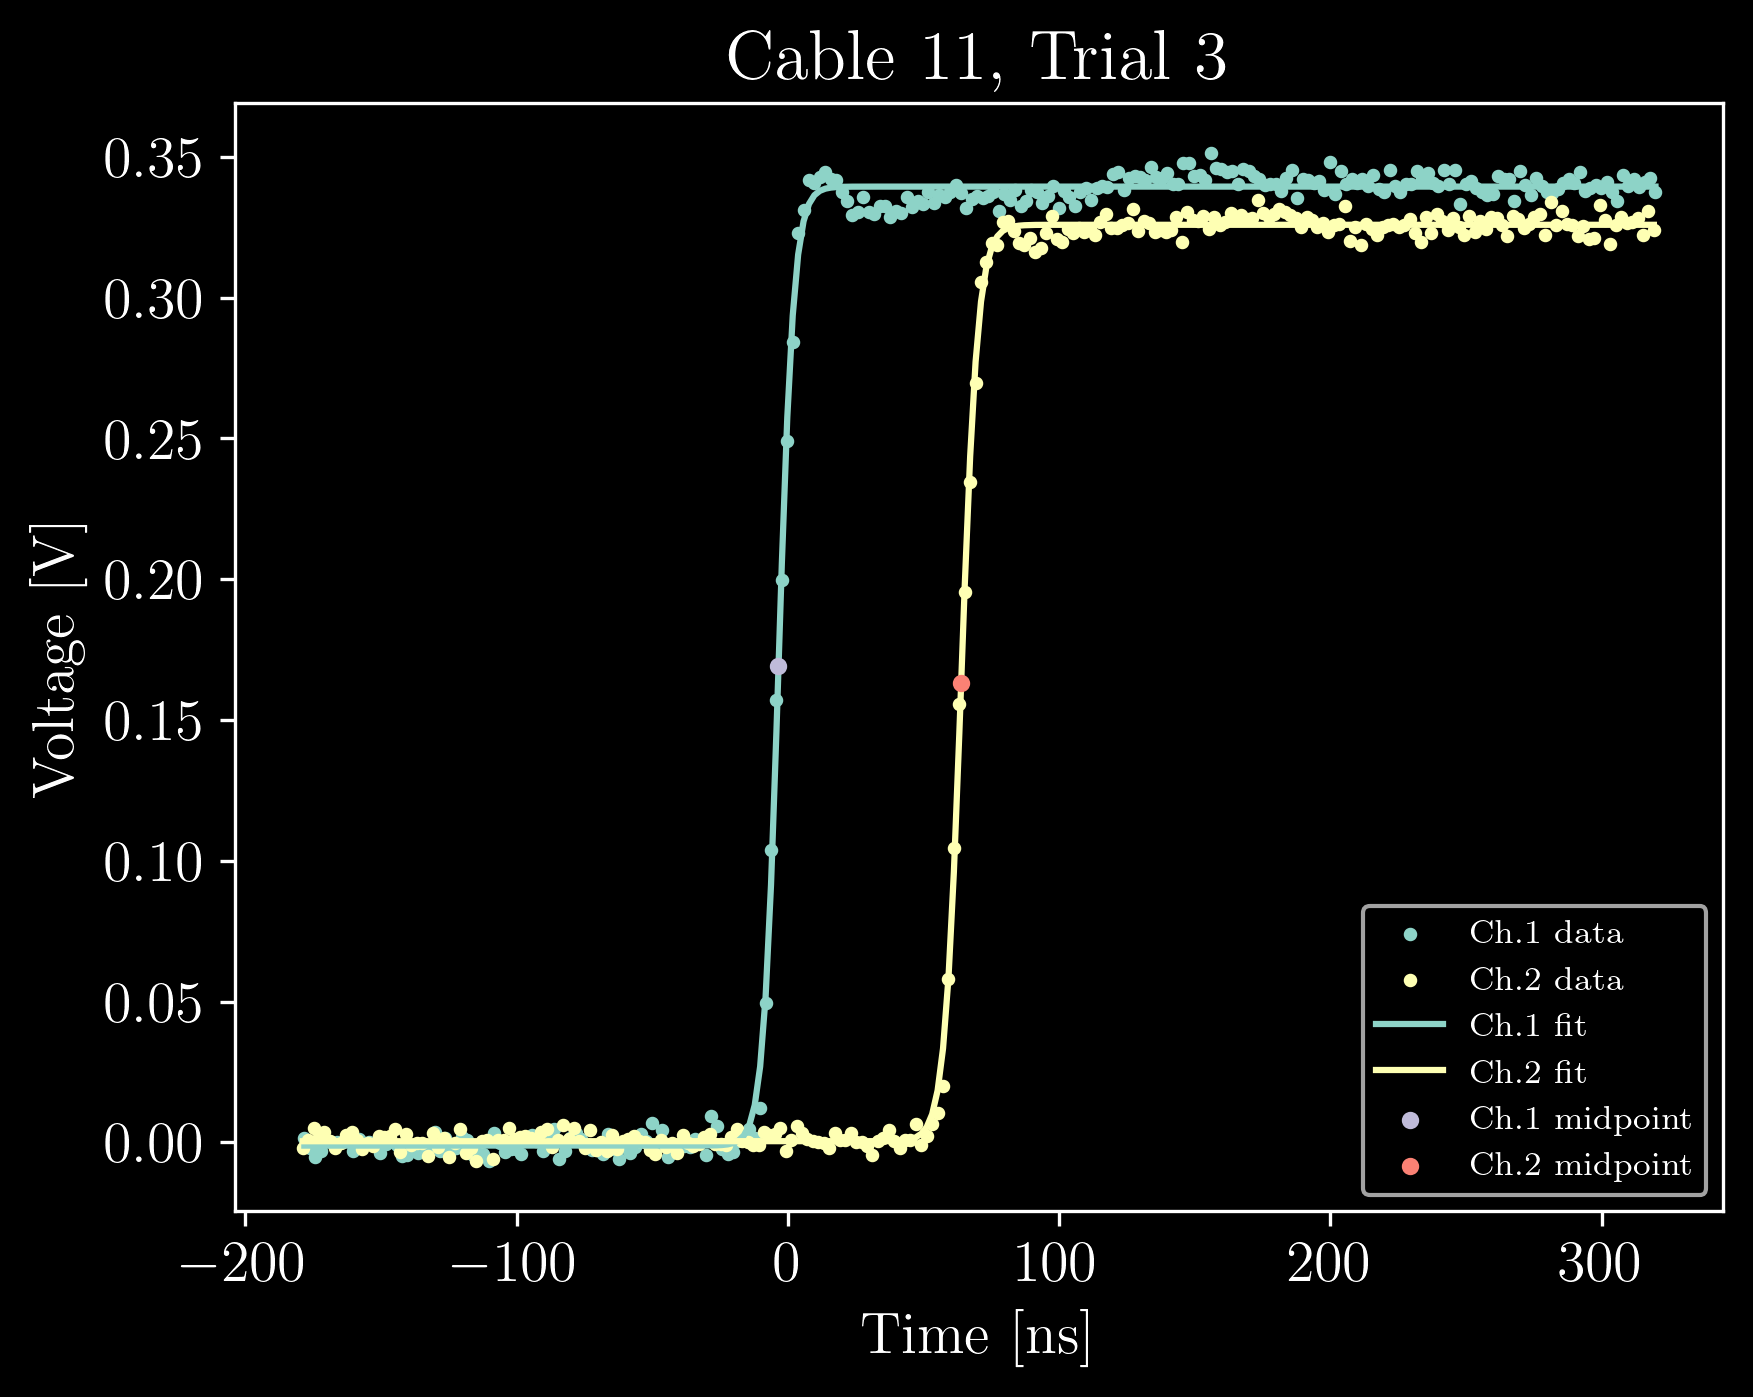

In [223]:
tdelay_Cable11_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables11and12 copy.txt',
               file_CH2='20261111_Ch2_Cable11_withCables5and1_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.78218446144425*100, xstart_CH2=-1.78813961249056*100, 
               title='Cable 11, Trial 3', num=250)

#### Average

In [224]:
tdelay_Cable11_avg = (tdelay_Cable11_1+tdelay_Cable11_2+tdelay_Cable11_3)/3
print('Average time delay = ' + str(tdelay_Cable11_avg) + ' ns')

Average time delay = 67.39400555974235 ns


# Cable 12

Cable type: black, long, thick

#### Trial 1

In [ ]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78218446144425E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78136194058049E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 66.60907651375031 ns


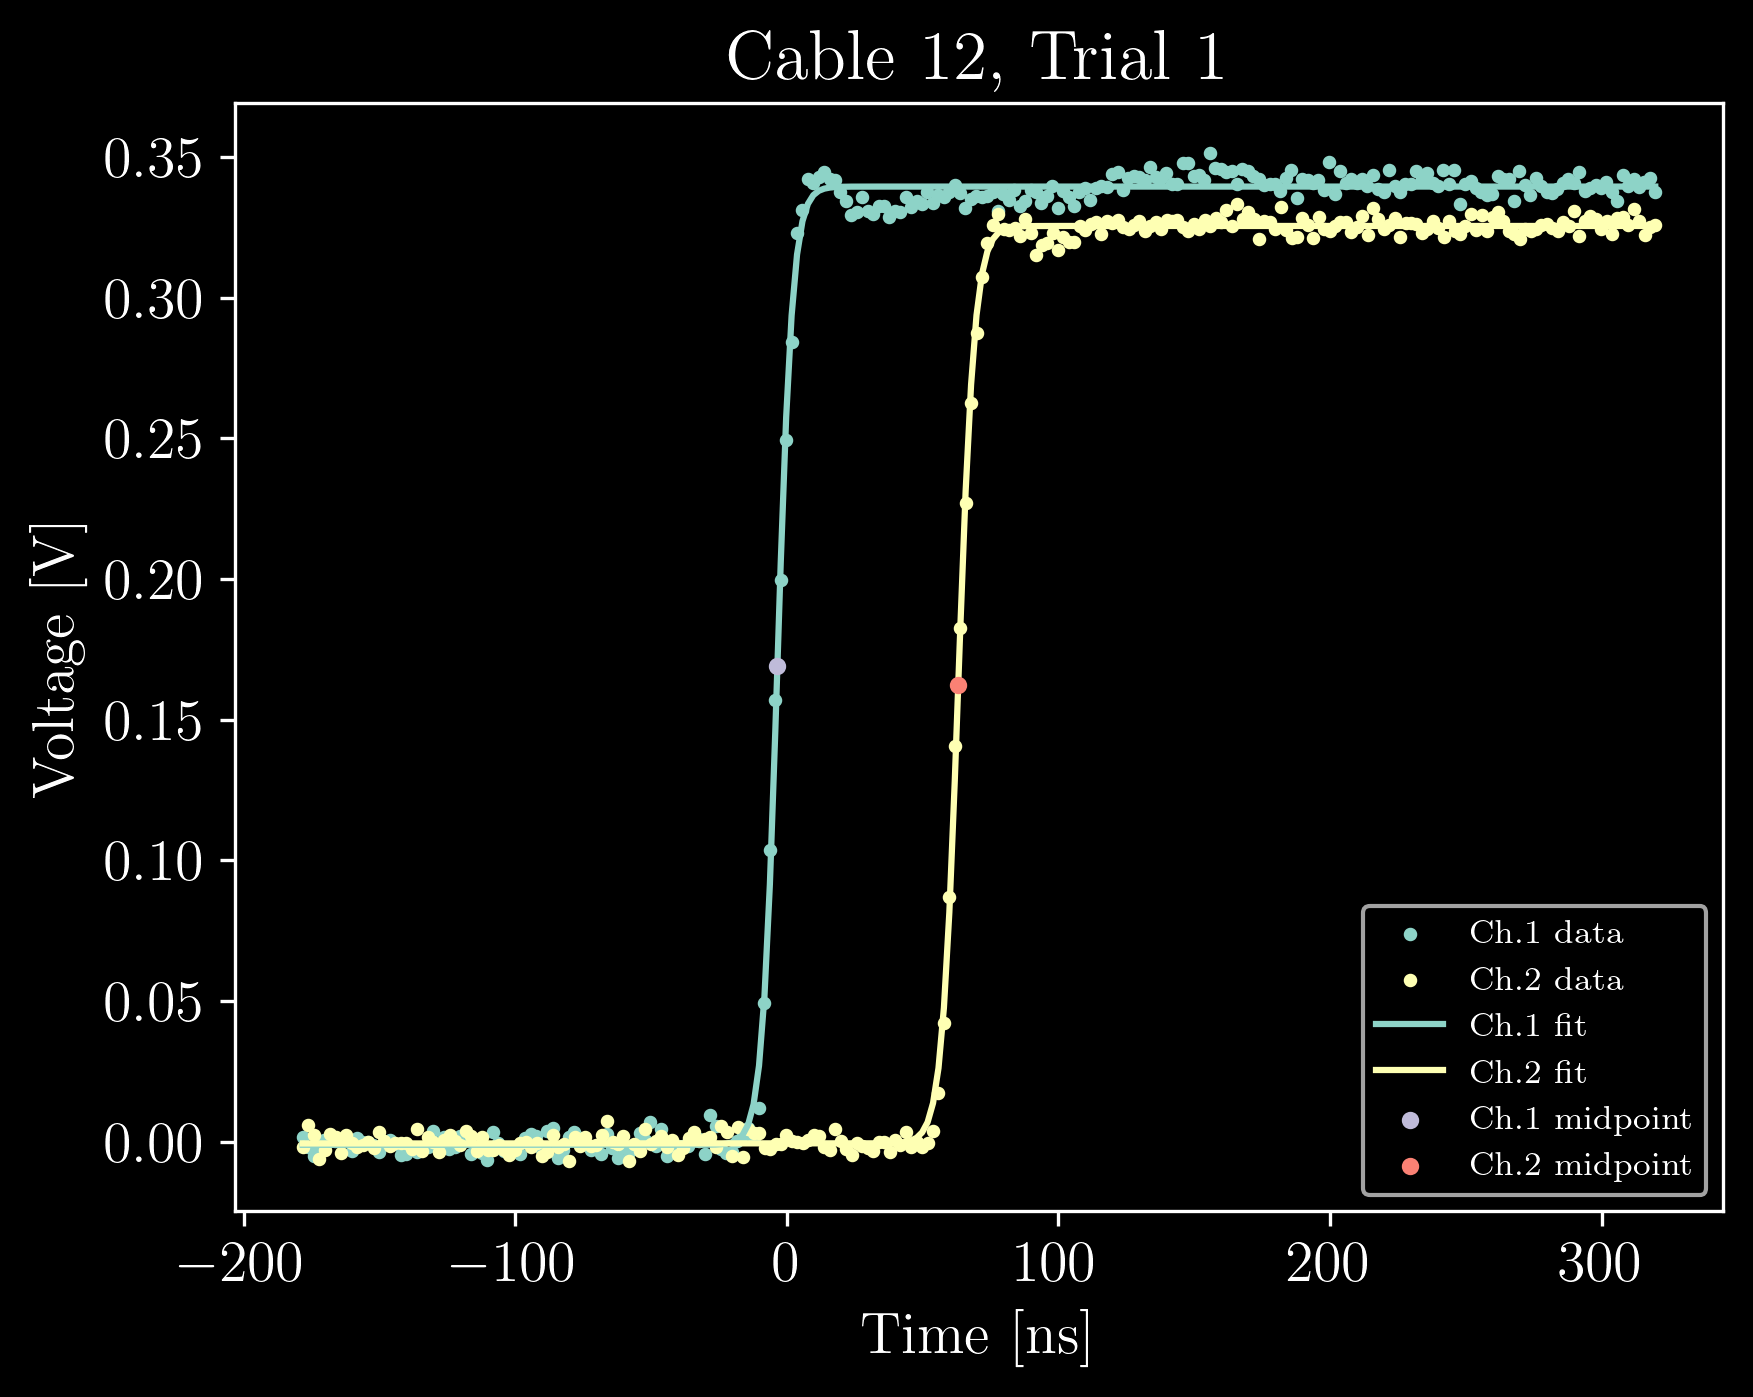

In [225]:
tdelay_Cable12_1 = analyze(file_CH1='20261111_Ch1_Reference_Cables11and12 copy.txt',
               file_CH2='20261111_Ch2_Cable12_withCables5and1_1 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.78218446144425*100, xstart_CH2=-1.78136194058049*100, 
               title='Cable 12, Trial 1', num=250)

#### Trial 2

In [ ]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78218446144425E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78967644816811E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 66.56080573143998 ns


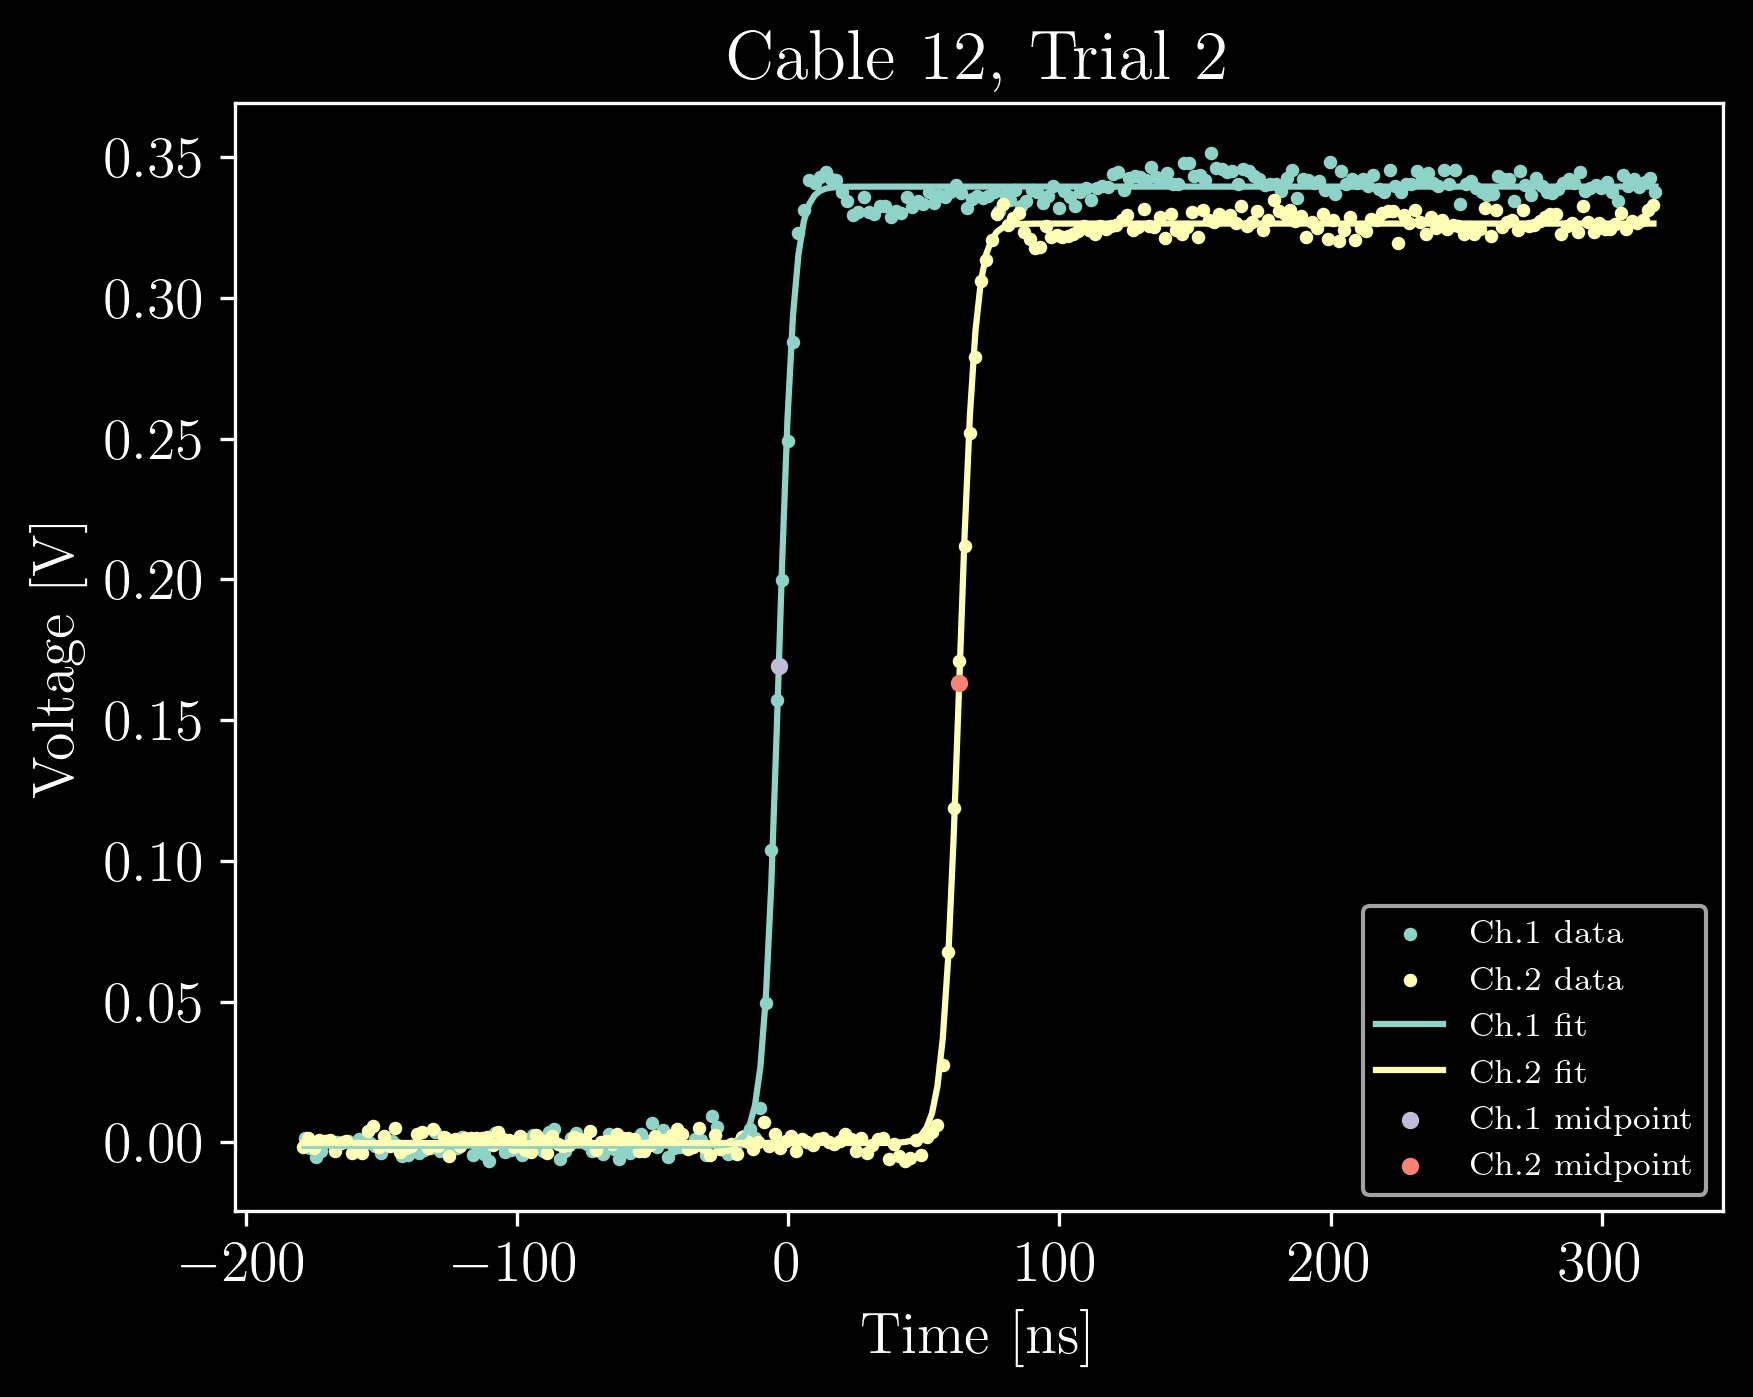

In [226]:
tdelay_Cable12_2 = analyze(file_CH1='20261111_Ch1_Reference_Cables11and12 copy.txt',
               file_CH2='20261111_Ch2_Cable12_withCables5and1_2 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.78218446144425*100, xstart_CH2=-1.78967644816811*100, 
               title='Cable 12, Trial 2', num=250)

#### Trial 3

In [ ]:
### CH. 1 ###
# This is text form of saved signal
# Format 4
# Channel 1
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78218446144425E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  2.48580000000000E-0001        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  8.00000000000000E-0002        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)


### CH. 2 ###
# This is text form of saved signal
# Format 4
# Channel 2
# Signal's parameters:
#    250        (Record Length)
# Waveform


# -1.78958721433675E-0007        (X-Value of the first point, Main unit)
# s        (Dimension of horizontal axes)
# s        (Dimension of horizontal axes)
#  2.00000000000000E-0009        (Sample interval, Main unit)
#  1.00000000000000E+0000        (X-Axis Auxiliary coeffitient)
# V        (Dimension of vertical axes)
#  0.00000000000000E+0000        (Vertical offset)
# Display's parameters:
# -1.80000000000000E-0007        (X-Value of left side of the screen)
#  5.00000000000000E-0008        (X-Value/div)
#  1.00000000000000E-0001        (Vertical Scale per division)
#  0.00000000000000E+0000        (Vertical Position)

Time delay = 66.63564797358237 ns


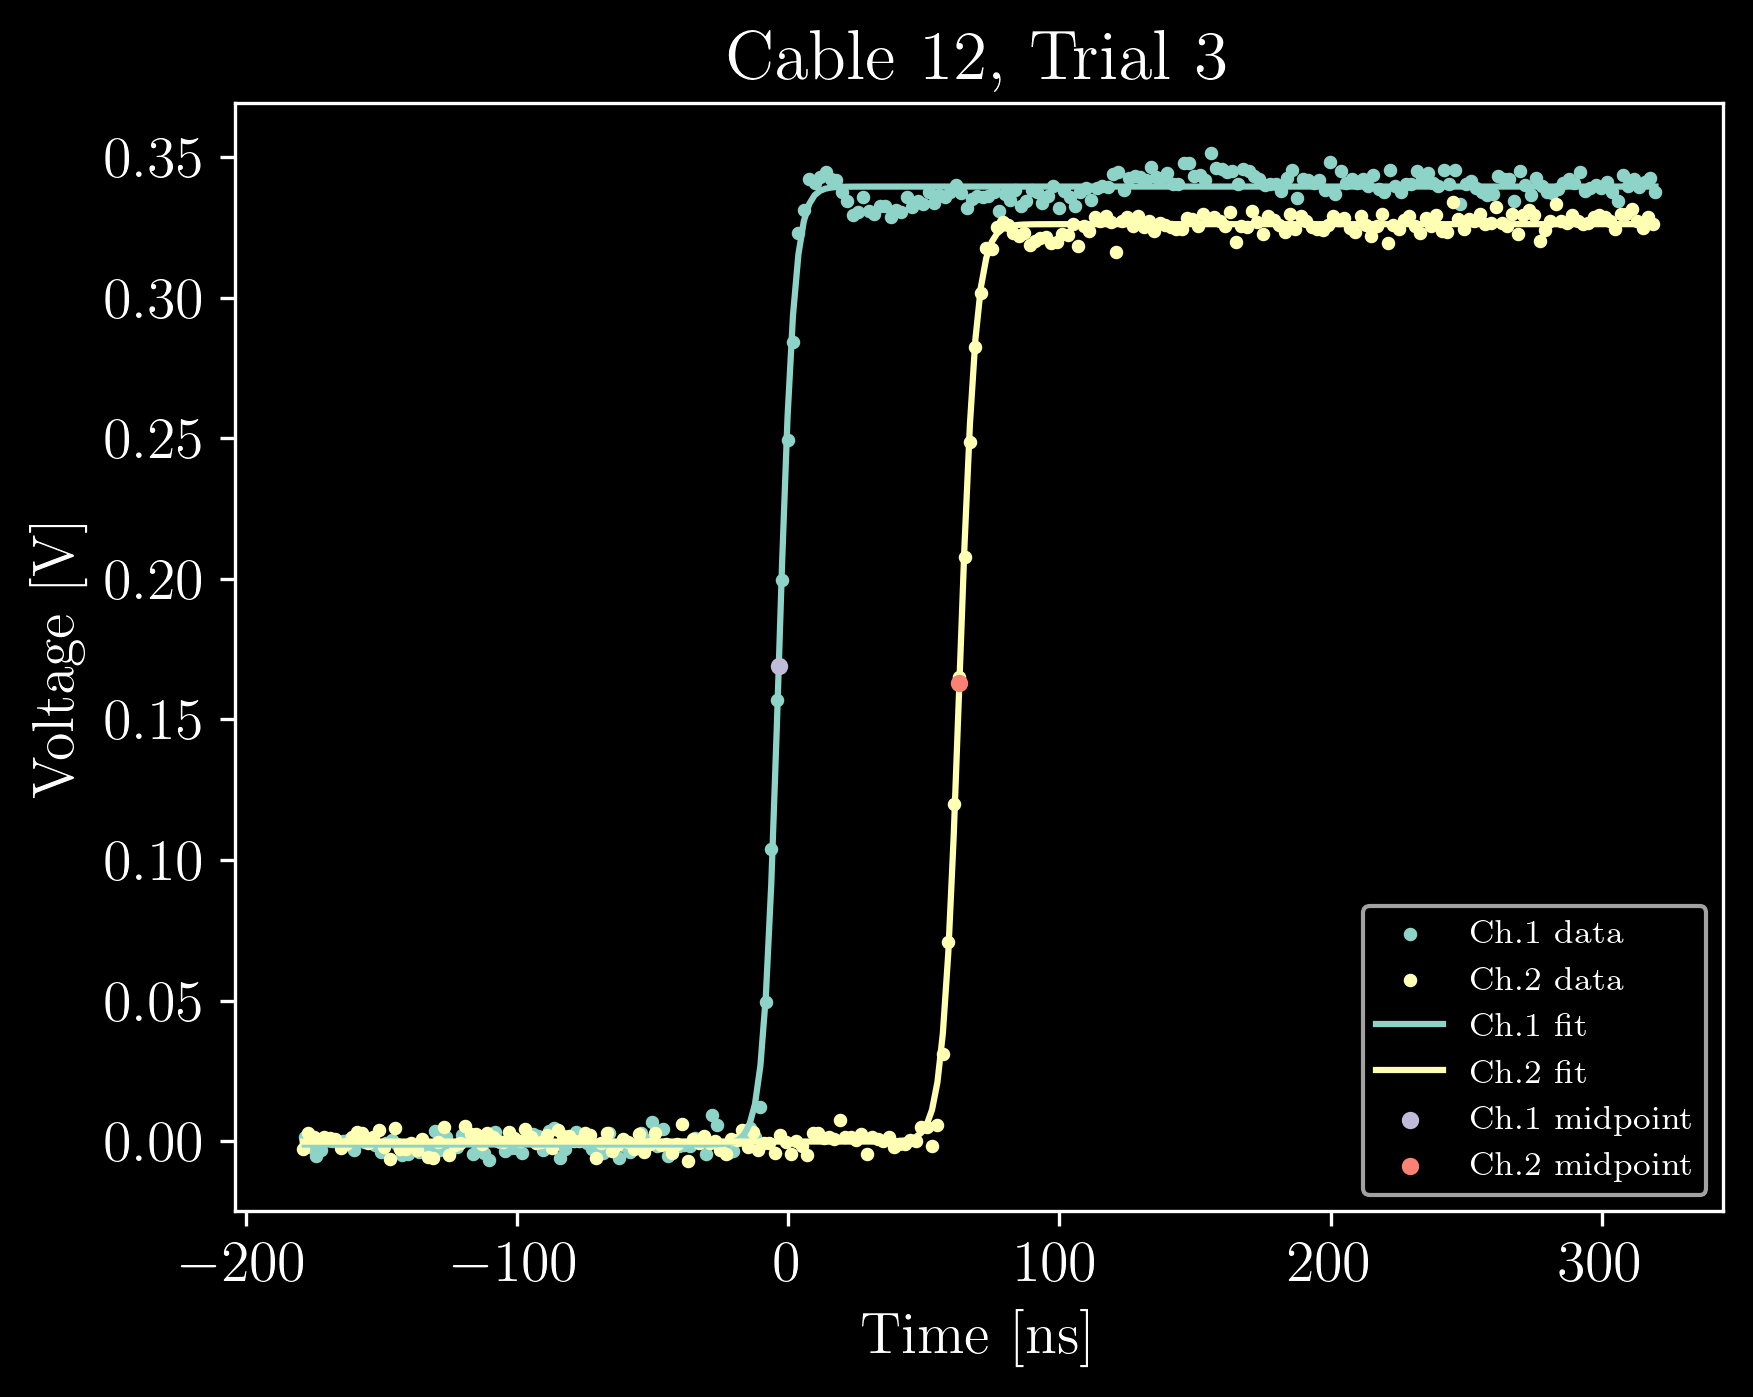

In [227]:
tdelay_Cable12_3 = analyze(file_CH1='20261111_Ch1_Reference_Cables11and12 copy.txt',
               file_CH2='20261111_Ch2_Cable12_withCables5and1_3 copy.txt', 
               xstep=2.00000000000000, 
               xstart_CH1=-1.78218446144425*100, xstart_CH2=-1.78958721433675*100, 
               title='Cable 12, Trial 3', num=250)

#### Average

In [228]:
tdelay_Cable12_avg = (tdelay_Cable12_1+tdelay_Cable12_2+tdelay_Cable12_3)/3
print('Average time delay = ' + str(tdelay_Cable12_avg) + ' ns')

Average time delay = 66.60184340625756 ns


# Summary table

In [256]:
rows = [['Cable 1', tdelay_Cable1_1, tdelay_Cable1_2, tdelay_Cable1_3, tdelay_Cable1_avg], 
        ['Cable 2', tdelay_Cable2_1, tdelay_Cable2_2, tdelay_Cable2_3, tdelay_Cable2_avg],
        ['Cable 3', tdelay_Cable3_1, tdelay_Cable3_2, tdelay_Cable3_3, tdelay_Cable3_avg],
        ['Cable 4', tdelay_Cable4_1, tdelay_Cable4_2, tdelay_Cable4_3, tdelay_Cable4_avg],
        ['Cable 5', tdelay_Cable5_1, tdelay_Cable5_2, tdelay_Cable5_3, tdelay_Cable5_avg],
        ['Cable 6', tdelay_Cable6_1, tdelay_Cable6_2, tdelay_Cable6_3, tdelay_Cable6_avg],
        ['Cable 7', tdelay_Cable7_1, tdelay_Cable7_2, tdelay_Cable7_3, tdelay_Cable7_avg],
        ['Cable 8', tdelay_Cable8_1, tdelay_Cable8_2, tdelay_Cable8_3, tdelay_Cable8_avg],
        ['Cable 9', tdelay_Cable9_1, tdelay_Cable9_2, tdelay_Cable9_3, tdelay_Cable9_avg],
        ['Cable 10', tdelay_Cable10_1, tdelay_Cable10_2, tdelay_Cable10_3, tdelay_Cable10_avg],
        ['Cable 11', tdelay_Cable11_1, tdelay_Cable11_2, tdelay_Cable11_3, tdelay_Cable11_avg],
        ['Cable 12', tdelay_Cable12_1, tdelay_Cable12_2, tdelay_Cable12_3, tdelay_Cable12_avg]]
df = pd.DataFrame(rows, columns=['Cable #', 'Trial 1', 'Trial 2', 'Trial 3', 'Average'])
print('Time delay (ns) for each cable:')
print(df)

Time delay (ns) for each cable:
     Cable #    Trial 1    Trial 2    Trial 3    Average
0    Cable 1  15.151951  15.027148  14.978259  15.052453
1    Cable 2  14.782473  14.968547  14.877141  14.876053
2    Cable 3  14.911423  14.895022  14.884115  14.896853
3    Cable 4  14.975727  14.845325  14.988194  14.936416
4    Cable 5   3.943551   3.946138   3.966970   3.952220
5    Cable 6   4.012931   3.908775   3.887735   3.936480
6    Cable 7   3.924993   4.036566   3.706733   3.889431
7    Cable 8   4.011271   3.940550   4.000138   3.983986
8    Cable 9  69.120107  69.151024  69.234194  69.168442
9   Cable 10  67.876442  67.763662  67.811893  67.817332
10  Cable 11  67.332575  67.476868  67.372574  67.394006
11  Cable 12  66.609077  66.560806  66.635648  66.601843
